In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/favorita-grocery-sales-forecasting/test.csv.7z
/kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z
/kaggle/input/competitions/favorita-grocery-sales-forecasting/items.csv.7z
/kaggle/input/competitions/favorita-grocery-sales-forecasting/holidays_events.csv.7z
/kaggle/input/competitions/favorita-grocery-sales-forecasting/transactions.csv.7z
/kaggle/input/competitions/favorita-grocery-sales-forecasting/train.csv.7z
/kaggle/input/competitions/favorita-grocery-sales-forecasting/oil.csv.7z
/kaggle/input/competitions/favorita-grocery-sales-forecasting/sample_submission.csv.7z


In [3]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
#creating datapath


data_path = "/kaggle/input/competitions/favorita-grocery-sales-forecasting"

print(os.listdir(data_path))

['test.csv.7z', 'stores.csv.7z', 'items.csv.7z', 'holidays_events.csv.7z', 'transactions.csv.7z', 'train.csv.7z', 'oil.csv.7z', 'sample_submission.csv.7z']


In [5]:
#check file size
import os

for file in os.listdir(data_path):
    file_path = os.path.join(data_path, file)
    size_mb = os.path.getsize(file_path) / (1024 ** 2)
    print(f"{file:30s} {size_mb:10.2f} MB")

test.csv.7z                          4.66 MB
stores.csv.7z                        0.00 MB
items.csv.7z                         0.01 MB
holidays_events.csv.7z               0.00 MB
transactions.csv.7z                  0.21 MB
train.csv.7z                       452.13 MB
oil.csv.7z                           0.00 MB
sample_submission.csv.7z             0.64 MB


In [6]:
#extracting data from the zips
!7z e "/kaggle/input/competitions/favorita-grocery-sales-forecasting/items.csv.7z" -o"/kaggle/working/favorita_data" -y


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,4 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /kaggle/input/competitions/favorita-grocery-sales-forecastin                                                                      1 file, 14315 bytes (14 KiB)

Extracting archive: /kaggle/input/competitions/favorita-grocery-sales-forecasting/items.csv.7z
--
Path = /kaggle/input/competitions/favorita-grocery-sales-forecasting/items.csv.7z
Type = 7z
Physical Size = 14315
Headers Size = 122
Method = LZMA2:17
Solid = -
Blocks = 1

    Everything is Ok

Size:       101841
Compressed: 14315


In [7]:
working_path = "/kaggle/working/favorita_data"

print(os.listdir(working_path))

['items.csv']


In [8]:
import pandas as pd

items = pd.read_csv(
    "/kaggle/working/favorita_data/items.csv"
)

print("Shape:", items.shape)

display(items.head())

Shape: (4100, 4)


,item_nbr,family,class,perishable
0,96995,GROCERY I,1093,0
1,99197,GROCERY I,1067,0
2,103501,CLEANING,3008,0
3,103520,GROCERY I,1028,0
4,103665,BREAD/BAKERY,2712,1


In [9]:
!7z


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,4 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Usage: 7z <command> [<switches>...] <archive_name> [<file_names>...]
       [<@listfiles...>]

<Commands>
  a : Add files to archive
  b : Benchmark
  d : Delete files from archive
  e : Extract files from archive (without using directory names)
  h : Calculate hash values for files
  i : Show information about supported formats
  l : List contents of archive
  rn : Rename files in archive
  t : Test integrity of archive
  u : Update files to archive
  x : eXtract files with full paths

<Switches>
  -- : Stop switches parsing
  -ai[r[-|0]]{@listfile|!wildcard} : Include archives
  -ax[r[-|0]]{@listfile|!wildcard} : eXclude archives
  -ao{a|s|t|u} : set Overwrite mode
  -an : disable archive_name field
  -bb[0-3] : set output log level
  -bd : disable progress indicator
  -bs{o|e|p}{0|1|2} : 

In [10]:
items.dtypes

item_nbr       int64
family        object
class          int64
perishable     int64
dtype: object

In [11]:
items.shape

(4100, 4)

In [12]:
items.nunique()

item_nbr      4100
family          33
class          337
perishable       2
dtype: int64

In [13]:
items.isnull().sum()

item_nbr      0
family        0
class         0
perishable    0
dtype: int64

In [14]:
items["family"].nunique()

33

In [15]:
items["family"].value_counts()

family
GROCERY I                     1334
BEVERAGES                      613
CLEANING                       446
PRODUCE                        306
DAIRY                          242
PERSONAL CARE                  153
BREAD/BAKERY                   134
HOME CARE                      108
DELI                            91
MEATS                           84
HOME AND KITCHEN I              77
LIQUOR,WINE,BEER                73
FROZEN FOODS                    55
POULTRY                         54
HOME AND KITCHEN II             45
EGGS                            41
CELEBRATION                     31
LAWN AND GARDEN                 26
PREPARED FOODS                  26
LADIESWEAR                      21
LINGERIE                        20
AUTOMOTIVE                      20
BEAUTY                          19
PLAYERS AND ELECTRONICS         17
SCHOOL AND OFFICE SUPPLIES      15
GROCERY II                      14
PET SUPPLIES                    14
SEAFOOD                          8
MAGAZINES    

In [16]:
items["perishable"].value_counts()

perishable
0    3114
1     986
Name: count, dtype: int64

In [17]:
items["perishable"].value_counts(normalize=True) * 100

perishable
0    75.95122
1    24.04878
Name: proportion, dtype: float64

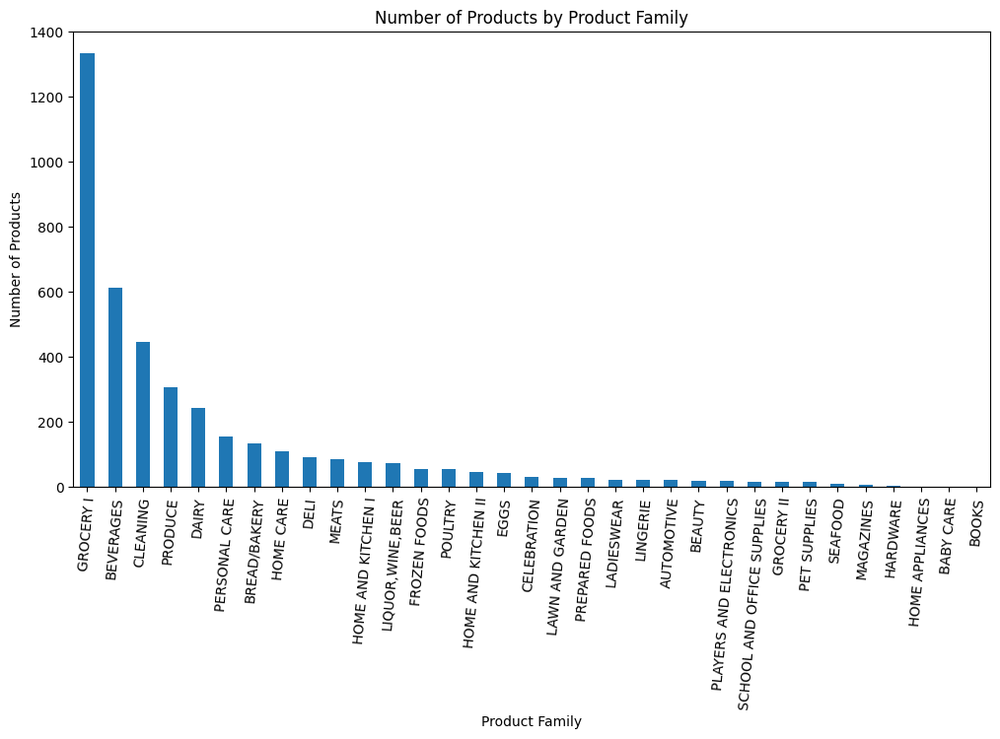

In [18]:
plt.figure(figsize=(12, 6))

items["family"].value_counts().plot(kind="bar")

plt.title("Number of Products by Product Family")
plt.xlabel("Product Family")
plt.ylabel("Number of Products")
plt.xticks(rotation=85)

plt.show()

In [20]:
#check stores
!7z e "/kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z" \
    -o"/kaggle/working/favorita_data" -y


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,4 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /kaggle/input/competitions/favorita-grocery-sales-forecastin                                                                      1 file, 648 bytes (1 KiB)

Extracting archive: /kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z
--
Path = /kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z
Type = 7z
Physical Size = 648
Headers Size = 130
Method = LZMA2:12
Solid = -
Blocks = 1

    Everything is Ok

Size:       1387
Compressed: 648


In [21]:
stores = pd.read_csv(
    "/kaggle/working/favorita_data/stores.csv"
)

print("Shape:", stores.shape)
display(stores.head())

Shape: (54, 5)


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [22]:
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   store_nbr  54 non-null     int64 
 1   city       54 non-null     object
 2   state      54 non-null     object
 3   type       54 non-null     object
 4   cluster    54 non-null     int64 
dtypes: int64(2), object(3)
memory usage: 2.2+ KB


In [23]:
stores.isnull().sum()

store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

In [24]:
perishable_pct = (
    items["perishable"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(perishable_pct)

perishable
0    75.95122
1    24.04878
Name: proportion, dtype: float64


In [25]:
!7z e "/kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z" \
    -o"/kaggle/working/favorita_data" -y


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,4 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /kaggle/input/competitions/favorita-grocery-sales-forecastin                                                                      1 file, 648 bytes (1 KiB)

Extracting archive: /kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z
--
Path = /kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z
Type = 7z
Physical Size = 648
Headers Size = 130
Method = LZMA2:12
Solid = -
Blocks = 1

    Everything is Ok

Size:       1387
Compressed: 648


In [26]:
stores = pd.read_csv(
    "/kaggle/working/favorita_data/stores.csv"
)

print("Shape:", stores.shape)

display(stores.head())

Shape: (54, 5)


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [27]:
!7z e "/kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z" \
    -o"/kaggle/working/favorita_data" -y

stores = pd.read_csv(
    "/kaggle/working/favorita_data/stores.csv"
)

print("Shape:", stores.shape)

print("\nFirst 5 rows:")
display(stores.head())

print("\nData types:")
print(stores.dtypes)

print("\nMissing values:")
print(stores.isnull().sum())

print("\nUnique values:")
print(stores.nunique())


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,4 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /kaggle/input/competitions/favorita-grocery-sales-forecastin                                                                      1 file, 648 bytes (1 KiB)

Extracting archive: /kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z
--
Path = /kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z
Type = 7z
Physical Size = 648
Headers Size = 130
Method = LZMA2:12
Solid = -
Blocks = 1

    Everything is Ok

Size:       1387
Compressed: 648
Shape: (54, 5)

First 5 rows:


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4



Data types:
store_nbr     int64
city         object
state        object
type         object
cluster       int64
dtype: object

Missing values:
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

Unique values:
store_nbr    54
city         22
state        16
type          5
cluster      17
dtype: int64


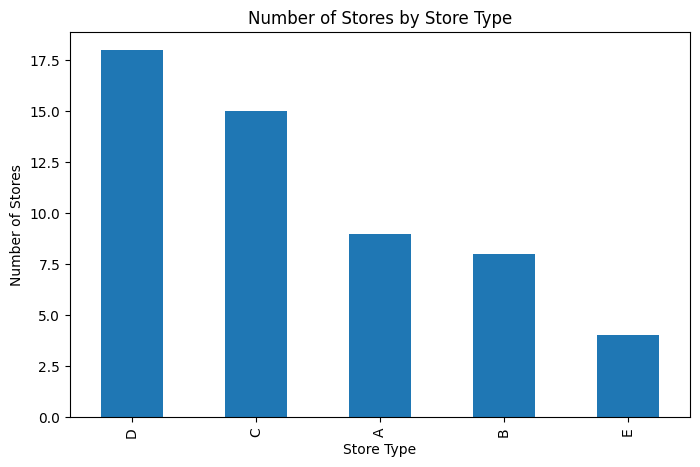

In [28]:
plt.figure(figsize=(8, 5))

stores["type"].value_counts().plot(kind="bar")

plt.title("Number of Stores by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Number of Stores")

plt.show()

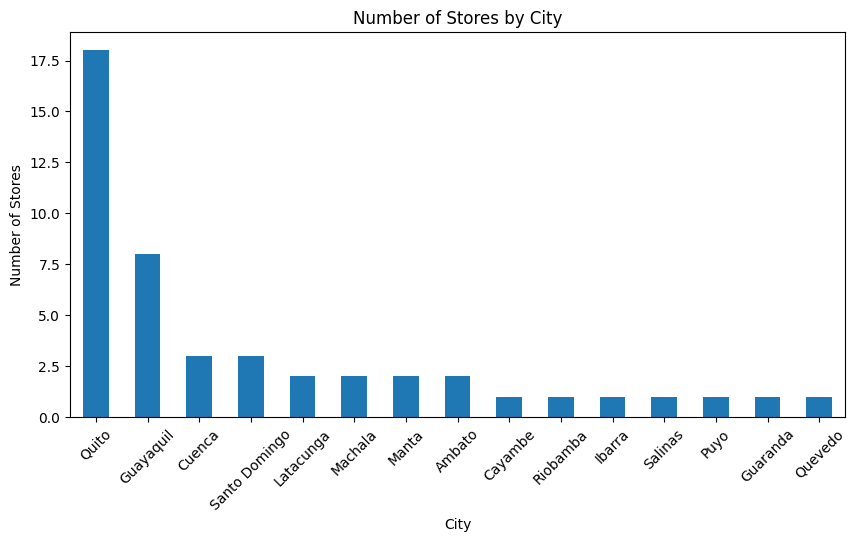

In [29]:
plt.figure(figsize=(10, 5))

stores["city"].value_counts().head(15).plot(kind="bar")

plt.title("Number of Stores by City")
plt.xlabel("City")
plt.ylabel("Number of Stores")

plt.xticks(rotation=45)

plt.show()

In [30]:
!7z l "/kaggle/input/competitions/favorita-grocery-sales-forecasting/train.csv.7z"


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,4 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /kaggle/input/competitions/favorita-grocery-sales-forecastin                                                                      1 file, 474092593 bytes (453 MiB)

Listing archive: /kaggle/input/competitions/favorita-grocery-sales-forecasting/train.csv.7z

--
Path = /kaggle/input/competitions/favorita-grocery-sales-forecasting/train.csv.7z
Type = 7z
Physical Size = 474092593
Headers Size = 122
Method = LZMA2:24
Solid = -
Blocks = 1

   Date      Time    Attr         Size   Compressed  Name
------------------- ----- ------------ ------------  ------------------------
2017-10-19 15:30:05 ....A   4997452288    474092471  train.csv
------------------- ----- ------------ ------------  ------------------------
2017-10-19 15:30:05         4997452288    47

In [31]:
!df -h /kaggle/working

Filesystem      Size  Used Avail Use% Mounted on
/dev/loop1       20G  188K   20G   1% /kaggle/working


In [32]:
!7z e "/kaggle/input/competitions/favorita-grocery-sales-forecasting/train.csv.7z" \
    -o"/kaggle/working/favorita_data" -y


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,4 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /kaggle/input/competitions/favorita-grocery-sales-forecastin                                                                      1 file, 474092593 bytes (453 MiB)

Extracting archive: /kaggle/input/competitions/favorita-grocery-sales-forecasting/train.csv.7z
--
Path = /kaggle/input/competitions/favorita-grocery-sales-forecasting/train.csv.7z
Type = 7z
Physical Size = 474092593
Headers Size = 122
Method = LZMA2:24
Solid = -
Blocks = 1

      0% - train.c                1% - train.c                2% - train.c                3% - train.c                4% - train.c                5% - train.c                6% - train.c                7% - train.c                8% - train.c                9% - train.c               10% - train.c               11% - 

In [33]:
import os

train_path = "/kaggle/working/favorita_data/train.csv"

print(os.path.exists(train_path))

if os.path.exists(train_path):
    size_gb = os.path.getsize(train_path) / (1024 ** 3)
    print(f"Train file size: {size_gb:.2f} GB")

True
Train file size: 4.65 GB


In [34]:
train_sample = pd.read_csv(
    train_path,
    nrows=10
)

display(train_sample)

,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,0,2013-01-01,25,103665,7.0,NaN
1,1,2013-01-01,25,105574,1.0,NaN
2,2,2013-01-01,25,105575,2.0,NaN
3,3,2013-01-01,25,108079,1.0,NaN
4,4,2013-01-01,25,108701,1.0,NaN
5,5,2013-01-01,25,108786,3.0,NaN
6,6,2013-01-01,25,108797,1.0,NaN
7,7,2013-01-01,25,108952,1.0,NaN
8,8,2013-01-01,25,111397,13.0,NaN
9,9,2013-01-01,25,114790,3.0,NaN


In [35]:
items[items["item_nbr"] == 103665]

,item_nbr,family,class,perishable
4,103665,BREAD/BAKERY,2712,1


In [36]:
train_sample.dtypes

id               int64
date            object
store_nbr        int64
item_nbr         int64
unit_sales     float64
onpromotion    float64
dtype: object

In [37]:
train_sample['date'] = pd.to_datetime(train_sample['date'])

In [38]:
train_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           10 non-null     int64         
 1   date         10 non-null     datetime64[ns]
 2   store_nbr    10 non-null     int64         
 3   item_nbr     10 non-null     int64         
 4   unit_sales   10 non-null     float64       
 5   onpromotion  0 non-null      float64       
dtypes: datetime64[ns](1), float64(2), int64(3)
memory usage: 612.0 bytes


In [39]:
print(train_sample["unit_sales"].describe())

count    10.00000
mean      3.30000
std       3.88873
min       1.00000
25%       1.00000
50%       1.50000
75%       3.00000
max      13.00000
Name: unit_sales, dtype: float64


In [40]:
train_path = "/kaggle/working/favorita_data/train.csv"

train_sample = pd.read_csv(
    train_path,
    nrows=10
)

display(train_sample)

print("\nData types:")
print(train_sample.dtypes)

print("\nSummary:")
print(train_sample["unit_sales"].describe())

,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,0,2013-01-01,25,103665,7.0,NaN
1,1,2013-01-01,25,105574,1.0,NaN
2,2,2013-01-01,25,105575,2.0,NaN
3,3,2013-01-01,25,108079,1.0,NaN
4,4,2013-01-01,25,108701,1.0,NaN
5,5,2013-01-01,25,108786,3.0,NaN
6,6,2013-01-01,25,108797,1.0,NaN
7,7,2013-01-01,25,108952,1.0,NaN
8,8,2013-01-01,25,111397,13.0,NaN
9,9,2013-01-01,25,114790,3.0,NaN



Data types:
id               int64
date            object
store_nbr        int64
item_nbr         int64
unit_sales     float64
onpromotion    float64
dtype: object

Summary:
count    10.00000
mean      3.30000
std       3.88873
min       1.00000
25%       1.00000
50%       1.50000
75%       3.00000
max      13.00000
Name: unit_sales, dtype: float64


In [41]:
train_sample["onpromotion"].unique()

array([nan])

In [43]:
train_sample.isnull().sum()

id              0
date            0
store_nbr       0
item_nbr        0
unit_sales      0
onpromotion    10
dtype: int64

In [44]:
train_sample = pd.read_csv(
    train_path,
    nrows=10000
)

train_sample["date"] = pd.to_datetime(train_sample["date"])

In [45]:
print(train_sample["onpromotion"].unique())

[nan]


In [46]:
print(train_sample["onpromotion"].value_counts(dropna=False))

onpromotion
NaN    10000
Name: count, dtype: int64


In [47]:
print("Minimum date:", train_sample["date"].min())
print("Maximum date:", train_sample["date"].max())
print("Number of unique dates:", train_sample["date"].nunique())

Minimum date: 2013-01-01 00:00:00
Maximum date: 2013-01-02 00:00:00
Number of unique dates: 2


In [48]:
print("Number of stores:", train_sample["store_nbr"].nunique())
print("Number of products:", train_sample["item_nbr"].nunique())

Number of stores: 10
Number of products: 1469


In [56]:
train_reader = pd.read_csv(
    train_path,
    usecols=["date", "onpromotion"],
    chunksize=100000
)

for i, chunk in enumerate(train_reader):
    
    print(f"\nChunk {i}")
    print(
        "Date range:",
        chunk["date"].min(),
        "to",
        chunk["date"].max()
    )
    
    print("Promotion values:")
    print(
        chunk["onpromotion"]
        .value_counts(dropna=False)
        .to_dict()
    )
    
    if i == 4:
        break


Chunk 0
Date range: 2013-01-01 to 2013-01-04
Promotion values:
{nan: 100000}

Chunk 1
Date range: 2013-01-04 to 2013-01-06
Promotion values:
{nan: 100000}

Chunk 2
Date range: 2013-01-06 to 2013-01-09
Promotion values:
{nan: 100000}

Chunk 3
Date range: 2013-01-09 to 2013-01-11
Promotion values:
{nan: 100000}

Chunk 4
Date range: 2013-01-11 to 2013-01-14
Promotion values:
{nan: 100000}


In [57]:
train_reader = pd.read_csv(
    train_path,
    usecols=["date", "onpromotion"],
    chunksize=100000
)

for i, chunk in enumerate(train_reader):

    if not chunk["onpromotion"].isna().all():

        print("First chunk containing promotion information:")
        print("Chunk:", i)
        print("Date range:", chunk["date"].min(), "to", chunk["date"].max())

        print("\nPromotion values:")
        print(chunk["onpromotion"].value_counts(dropna=False))

        break

First chunk containing promotion information:
Chunk: 216
Date range: 2014-03-31 to 2014-04-01

Promotion values:
onpromotion
NaN      57651
False    42341
True         8
Name: count, dtype: int64


In [58]:
train_reader = pd.read_csv(
    train_path,
    usecols=["date"],
    chunksize=100000
)

min_date = None
max_date = None

for chunk in train_reader:

    chunk_min = chunk["date"].min()
    chunk_max = chunk["date"].max()

    if min_date is None or chunk_min < min_date:
        min_date = chunk_min

    if max_date is None or chunk_max > max_date:
        max_date = chunk_max

print("Earliest date:", min_date)
print("Latest date:", max_date)

Earliest date: 2013-01-01
Latest date: 2017-08-15


In [62]:
(pd.to_datetime(max_date) - pd.to_datetime(min_date)).days

1687

In [63]:
train_reader = pd.read_csv(
    train_path,
    usecols=["date"],
    chunksize=100000
)

dates = set()

for chunk in train_reader:
    dates.update(chunk["date"].unique())

print("Number of unique dates:", len(dates))

Number of unique dates: 1684


In [64]:
daily_sales_parts = []

train_reader = pd.read_csv(
    train_path,
    usecols=["date", "unit_sales"],
    chunksize=100000
)

for chunk in train_reader:
    
    daily_sales = (
        chunk
        .groupby("date")["unit_sales"]
        .sum()
    )
    
    daily_sales_parts.append(daily_sales)

daily_sales = (
    pd.concat(daily_sales_parts)
    .groupby(level=0)
    .sum()
    .reset_index()
)

daily_sales.columns = ["date", "total_sales"]

daily_sales["date"] = pd.to_datetime(daily_sales["date"])

daily_sales = daily_sales.sort_values("date")

display(daily_sales.head())
display(daily_sales.tail())

,date,total_sales
0,2013-01-01,2511.619
1,2013-01-02,496092.418
2,2013-01-03,361429.231
3,2013-01-04,354459.677
4,2013-01-05,477350.121


,date,total_sales
1679,2017-08-11,826373.722
1680,2017-08-12,792630.535
1681,2017-08-13,865639.677
1682,2017-08-14,760922.406
1683,2017-08-15,762661.936


In [65]:
print("Shape:", daily_sales.shape)

print("\nDate range:")
print(daily_sales["date"].min(), "to", daily_sales["date"].max())

print("\nMissing values:")
print(daily_sales.isnull().sum())

print("\nSummary statistics:")
print(daily_sales["total_sales"].describe())

Shape: (1684, 2)

Date range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00

Missing values:
date           0
total_sales    0
dtype: int64

Summary statistics:
count    1.684000e+03
mean     6.375358e+05
std      2.343921e+05
min      2.511619e+03
25%      4.425738e+05
50%      6.321889e+05
75%      7.859455e+05
max      1.463084e+06
Name: total_sales, dtype: float64


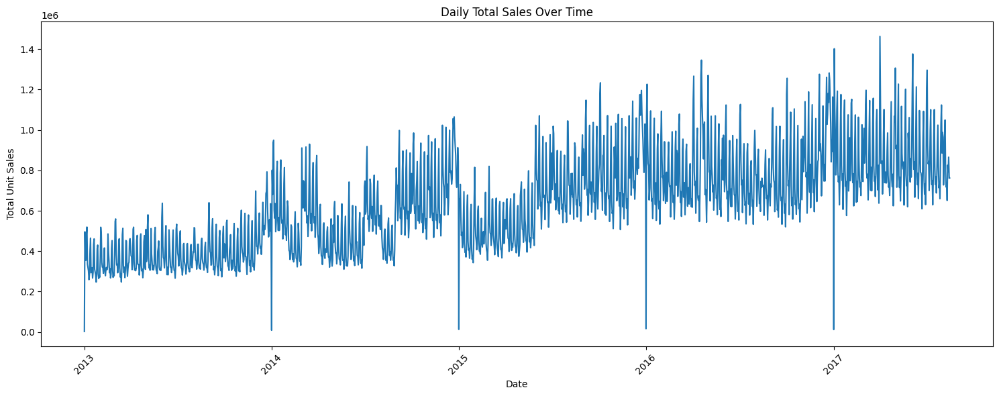

In [66]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["total_sales"]
)

plt.title("Daily Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
full_dates = pd.date_range(
    start=daily_sales["date"].min(),
    end=daily_sales["date"].max(),
    freq="D"
)

missing_dates = full_dates.difference(
    daily_sales["date"]
)

print("Expected calendar days:", len(full_dates))
print("Observed sales days:", len(daily_sales))
print("Missing dates:", len(missing_dates))

print("\nMissing dates:")
print(missing_dates)

Expected calendar days: 1688
Observed sales days: 1684
Missing dates: 4

Missing dates:
DatetimeIndex(['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25'], dtype='datetime64[ns]', freq=None)


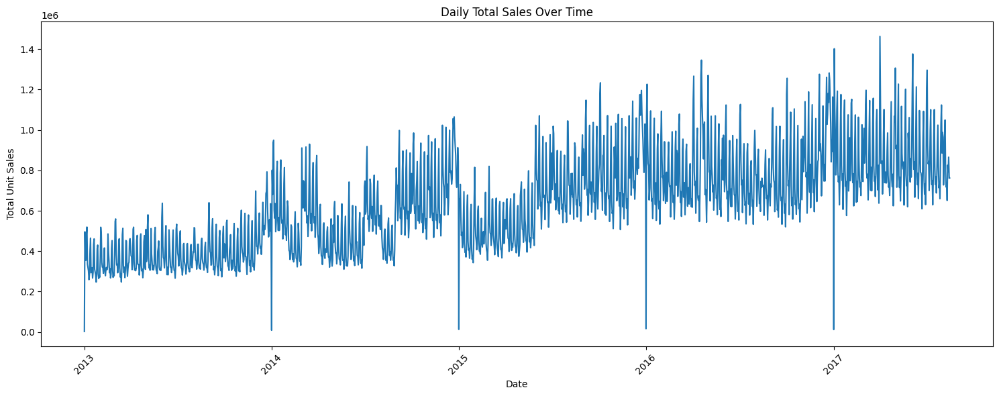

In [68]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["total_sales"]
)

plt.title("Daily Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [69]:

# 1. Basic information
print("=" * 60)
print("DAILY SALES DATASET")
print("=" * 60)

print("Shape:", daily_sales.shape)

print("\nDate range:")
print(
    daily_sales["date"].min(),
    "to",
    daily_sales["date"].max()
)

print("\nMissing values:")
print(daily_sales.isnull().sum())


# 2. Create the complete calendar range
full_dates = pd.date_range(
    start=daily_sales["date"].min(),
    end=daily_sales["date"].max(),
    freq="D"
)

# Find dates that are missing from our daily dataset
missing_dates = full_dates.difference(
    daily_sales["date"]
)

print("\n" + "=" * 60)
print("MISSING CALENDAR DATES")
print("=" * 60)

print("Expected calendar days:", len(full_dates))
print("Observed sales days:", len(daily_sales))
print("Number of missing dates:", len(missing_dates))

print("\nMissing dates:")
print(missing_dates)


# 3. Summary statistics
print("\n" + "=" * 60)
print("SUMMARY STATISTICS")
print("=" * 60)

print(daily_sales["total_sales"].describe())


DAILY SALES DATASET
Shape: (1684, 2)

Date range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00

Missing values:
date           0
total_sales    0
dtype: int64

MISSING CALENDAR DATES
Expected calendar days: 1688
Observed sales days: 1684
Number of missing dates: 4

Missing dates:
DatetimeIndex(['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25'], dtype='datetime64[ns]', freq=None)

SUMMARY STATISTICS
count    1.684000e+03
mean     6.375358e+05
std      2.343921e+05
min      2.511619e+03
25%      4.425738e+05
50%      6.321889e+05
75%      7.859455e+05
max      1.463084e+06
Name: total_sales, dtype: float64


In [70]:

# 4. Minimum-sales day
min_day = daily_sales.loc[
    daily_sales["total_sales"].idxmin()
]

print("\n" + "=" * 60)
print("MINIMUM SALES DAY")
print("=" * 60)

print(min_day)


# 5. Maximum-sales day
max_day = daily_sales.loc[
    daily_sales["total_sales"].idxmax()
]

print("\n" + "=" * 60)
print("MAXIMUM SALES DAY")
print("=" * 60)

print(max_day)



MINIMUM SALES DAY
date           2013-01-01 00:00:00
total_sales               2511.619
Name: 0, dtype: object

MAXIMUM SALES DAY
date           2017-04-01 00:00:00
total_sales            1463083.963
Name: 1547, dtype: object


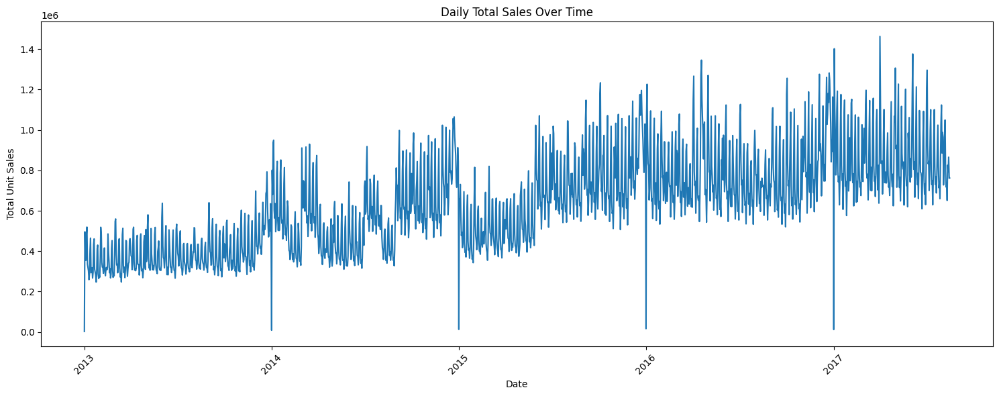

In [71]:

# 6. Plot daily total sales
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["total_sales"]
)

plt.title("Daily Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



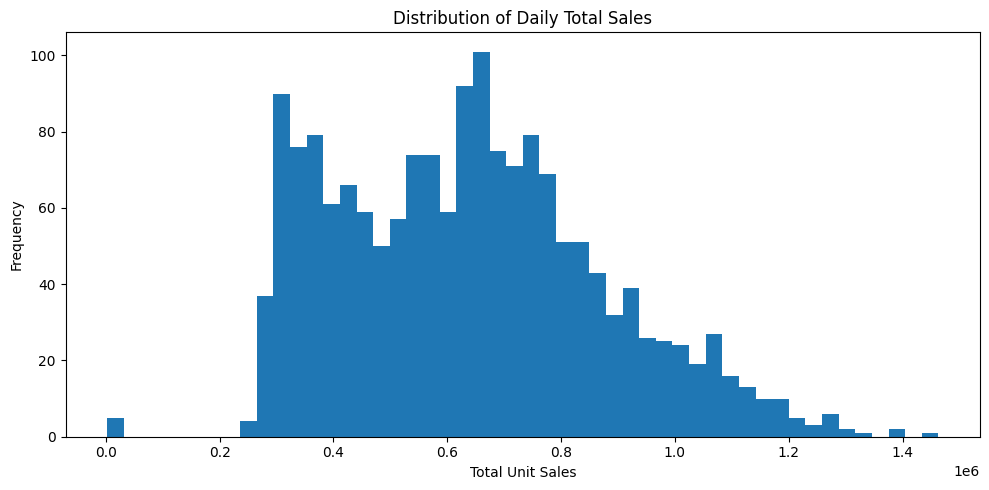

In [72]:

# 7. Histogram of daily sales
plt.figure(figsize=(10, 5))

plt.hist(
    daily_sales["total_sales"],
    bins=50
)

plt.title("Distribution of Daily Total Sales")
plt.xlabel("Total Unit Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

WEEKLY SALES
Shape: (242, 2)

Date range:
2013-01-06 00:00:00 to 2017-08-20 00:00:00

Summary statistics:
count    2.420000e+02
mean     4.436406e+06
std      1.342108e+06
min      1.523584e+06
25%      3.033951e+06
50%      4.820201e+06
75%      5.526853e+06
max      7.477141e+06
Name: total_sales, dtype: float64

MONTHLY SALES
Shape: (56, 2)

Date range:
2013-01-31 00:00:00 to 2017-08-31 00:00:00

Summary statistics:
count    5.600000e+01
mean     1.917161e+07
std      5.806462e+06
min      9.658960e+06
25%      1.320528e+07
50%      2.046384e+07
75%      2.390314e+07
max      2.963820e+07
Name: total_sales, dtype: float64


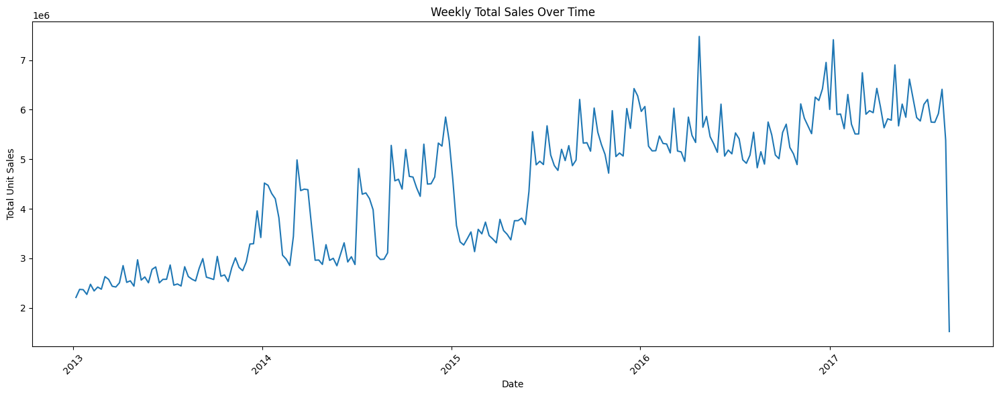

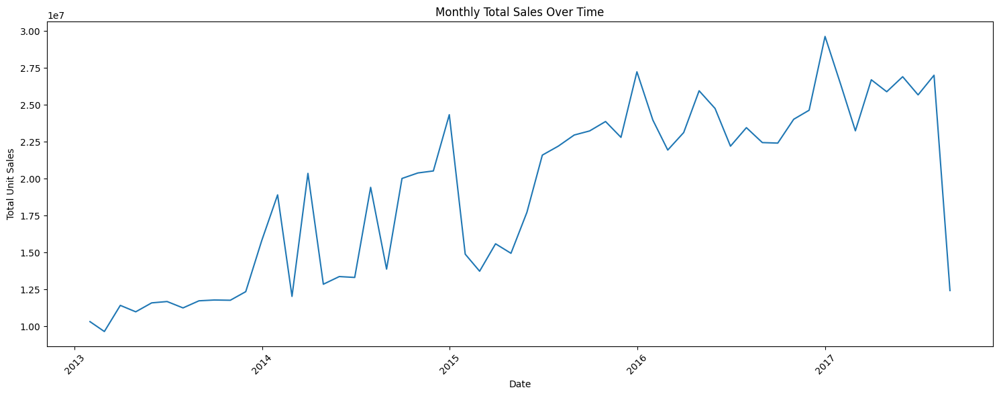


AVERAGE SALES BY MONTH
month
1     1.888838e+07
2     1.612744e+07
3     1.944569e+07
4     1.813303e+07
5     1.887662e+07
6     1.890088e+07
7     2.067261e+07
8     1.669447e+07
9     1.936842e+07
10    2.002008e+07
11    2.008392e+07
12    2.425625e+07
Name: total_sales, dtype: float64

AVERAGE SALES BY DAY OF WEEK
day_of_week
0    617479.929934
1    569916.489993
2    593244.190965
3    505256.688612
4    579573.986125
5    772147.340838
6    825218.075771
Name: total_sales, dtype: float64


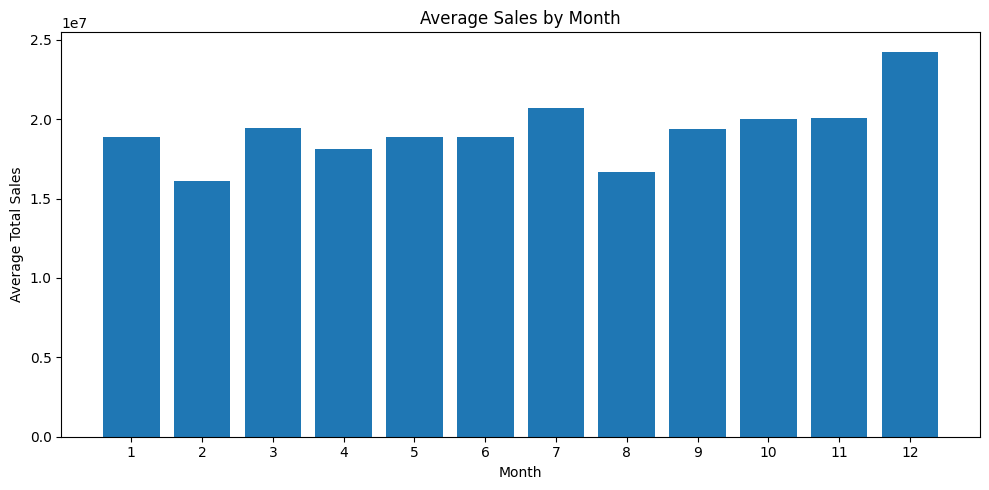

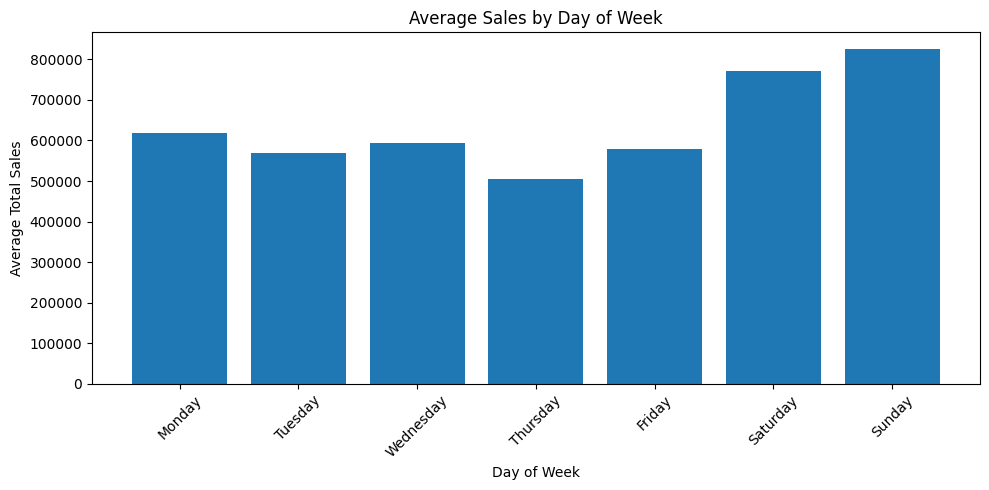

In [73]:
# ============================================================
# STEP 11 — WEEKLY AND MONTHLY SALES ANALYSIS
# ============================================================

# Make sure date is datetime
daily_sales["date"] = pd.to_datetime(daily_sales["date"])

# Set date as index for resampling
daily_sales_indexed = daily_sales.set_index("date")


# ============================================================
# 1. WEEKLY SALES
# ============================================================

weekly_sales = (
    daily_sales_indexed["total_sales"]
    .resample("W")
    .sum()
    .reset_index()
)

weekly_sales.columns = ["date", "total_sales"]


print("=" * 60)
print("WEEKLY SALES")
print("=" * 60)

print("Shape:", weekly_sales.shape)

print("\nDate range:")
print(
    weekly_sales["date"].min(),
    "to",
    weekly_sales["date"].max()
)

print("\nSummary statistics:")
print(weekly_sales["total_sales"].describe())


# ============================================================
# 2. MONTHLY SALES
# ============================================================

monthly_sales = (
    daily_sales_indexed["total_sales"]
    .resample("ME")
    .sum()
    .reset_index()
)

monthly_sales.columns = ["date", "total_sales"]


print("\n" + "=" * 60)
print("MONTHLY SALES")
print("=" * 60)

print("Shape:", monthly_sales.shape)

print("\nDate range:")
print(
    monthly_sales["date"].min(),
    "to",
    monthly_sales["date"].max()
)

print("\nSummary statistics:")
print(monthly_sales["total_sales"].describe())


# ============================================================
# 3. WEEKLY SALES PLOT
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    weekly_sales["date"],
    weekly_sales["total_sales"]
)

plt.title("Weekly Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# 4. MONTHLY SALES PLOT
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_sales["date"],
    monthly_sales["total_sales"]
)

plt.title("Monthly Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# 5. AVERAGE SALES BY MONTH
# ============================================================

monthly_sales["month"] = monthly_sales["date"].dt.month

avg_sales_by_month = (
    monthly_sales
    .groupby("month")["total_sales"]
    .mean()
)

print("\n" + "=" * 60)
print("AVERAGE SALES BY MONTH")
print("=" * 60)

print(avg_sales_by_month)


# ============================================================
# 6. AVERAGE SALES BY DAY OF WEEK
# ============================================================

daily_sales["day_of_week"] = daily_sales["date"].dt.dayofweek

avg_sales_by_day = (
    daily_sales
    .groupby("day_of_week")["total_sales"]
    .mean()
)

print("\n" + "=" * 60)
print("AVERAGE SALES BY DAY OF WEEK")
print("=" * 60)

print(avg_sales_by_day)


# ============================================================
# 7. MONTHLY SEASONALITY BAR CHART
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    avg_sales_by_month.index,
    avg_sales_by_month.values
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Total Sales")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()


# ============================================================
# 8. DAY-OF-WEEK PATTERN
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    avg_sales_by_day.index,
    avg_sales_by_day.values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Total Sales")

plt.xticks(
    range(7),
    ["Monday", "Tuesday", "Wednesday",
     "Thursday", "Friday", "Saturday", "Sunday"],
    rotation=45
)

plt.tight_layout()
plt.show()

STEP 12: OUTLIERS AND DATA QUALITY

DAILY SALES IQR OUTLIERS
Q1: 442573.755
Q3: 785945.482
IQR: 343371.72699999996
Lower bound: -72483.83549999993
Upper bound: 1301003.0724999998

Number of outlier days: 5

Outlier days:


,date,total_sales,day_of_week
1577,2017-05-01,1306699.367,0
1200,2016-04-18,1345920.605,0
1611,2017-06-04,1376511.520,6
1458,2017-01-02,1402305.371,0
1547,2017-04-01,1463083.963,5



LOWEST 10 SALES DAYS


,date,total_sales,day_of_week
0,2013-01-01,2511.6190,1
364,2014-01-01,8602.0654,2
1457,2017-01-01,12082.5010,6
728,2015-01-01,12773.6170,3
1092,2016-01-01,16433.3940,4
23,2013-01-24,247245.6910,3
72,2013-03-14,247541.4200,3
9,2013-01-10,258982.0030,3
28,2013-01-29,264488.8180,1
177,2013-06-27,266525.4590,3



HIGHEST 10 SALES DAYS


,date,total_sales,day_of_week
1547,2017-04-01,1463083.963,5
1458,2017-01-02,1402305.371,0
1611,2017-06-04,1376511.520,6
1200,2016-04-18,1345920.605,0
1577,2017-05-01,1306699.367,0
1639,2017-07-02,1296379.217,6
1449,2016-12-23,1282145.517,4
1430,2016-12-04,1276195.036,6
1199,2016-04-17,1271833.739,6
1213,2016-05-01,1270121.208,6



DAILY SALES QUALITY
Zero-sales days: 0
Negative-sales days: 0

RAW UNIT SALES QUALITY CHECK
Rows scanned: 125497040
Negative unit_sales rows: 7795
Zero unit_sales rows: 0
Minimum unit_sales: -15372.0
Maximum unit_sales: 89440.0


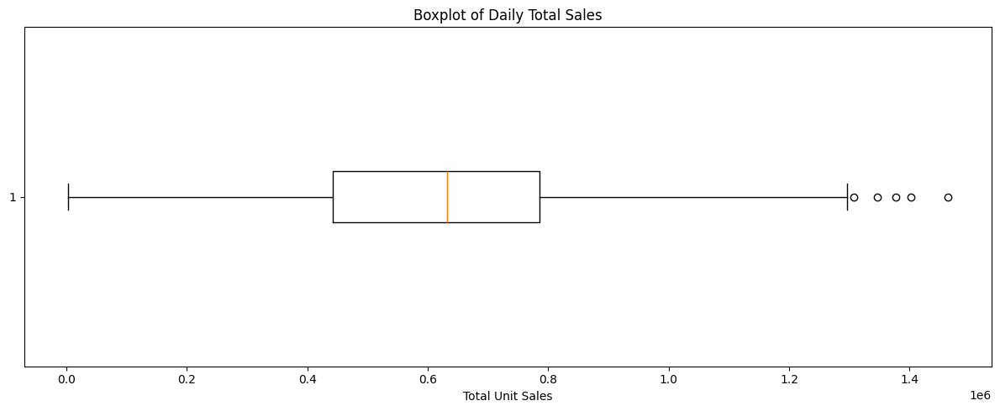

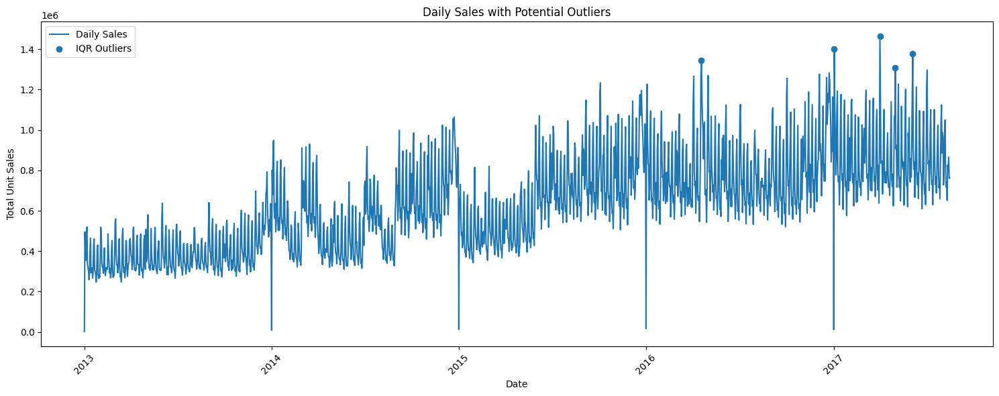

In [74]:
# ============================================================
# STEP 12 — OUTLIERS AND DATA QUALITY CHECK
# ============================================================

print("=" * 70)
print("STEP 12: OUTLIERS AND DATA QUALITY")
print("=" * 70)


# ============================================================
# 1. IQR OUTLIER DETECTION ON DAILY SALES
# ============================================================

Q1 = daily_sales["total_sales"].quantile(0.25)
Q3 = daily_sales["total_sales"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

daily_outliers = daily_sales[
    (daily_sales["total_sales"] < lower_bound) |
    (daily_sales["total_sales"] > upper_bound)
].copy()

print("\n" + "=" * 70)
print("DAILY SALES IQR OUTLIERS")
print("=" * 70)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nNumber of outlier days:", len(daily_outliers))

print("\nOutlier days:")
display(
    daily_outliers
    .sort_values("total_sales")
    .head(20)
)


# ============================================================
# 2. LOWEST AND HIGHEST SALES DAYS
# ============================================================

print("\n" + "=" * 70)
print("LOWEST 10 SALES DAYS")
print("=" * 70)

display(
    daily_sales
    .nsmallest(10, "total_sales")
)


print("\n" + "=" * 70)
print("HIGHEST 10 SALES DAYS")
print("=" * 70)

display(
    daily_sales
    .nlargest(10, "total_sales")
)


# ============================================================
# 3. CHECK ZERO AND NEGATIVE DAILY SALES
# ============================================================

zero_sales_days = (
    daily_sales["total_sales"] == 0
).sum()

negative_sales_days = (
    daily_sales["total_sales"] < 0
).sum()

print("\n" + "=" * 70)
print("DAILY SALES QUALITY")
print("=" * 70)

print("Zero-sales days:", zero_sales_days)
print("Negative-sales days:", negative_sales_days)


# ============================================================
# 4. SCAN RAW TRAIN DATA FOR NEGATIVE UNIT SALES
# ============================================================

negative_rows = 0
zero_rows = 0
total_rows = 0

max_unit_sales = None
min_unit_sales = None

train_reader = pd.read_csv(
    train_path,
    usecols=["unit_sales"],
    chunksize=100000
)

for chunk in train_reader:

    total_rows += len(chunk)

    negative_rows += (
        chunk["unit_sales"] < 0
    ).sum()

    zero_rows += (
        chunk["unit_sales"] == 0
    ).sum()

    chunk_max = chunk["unit_sales"].max()
    chunk_min = chunk["unit_sales"].min()

    if max_unit_sales is None or chunk_max > max_unit_sales:
        max_unit_sales = chunk_max

    if min_unit_sales is None or chunk_min < min_unit_sales:
        min_unit_sales = chunk_min


print("\n" + "=" * 70)
print("RAW UNIT SALES QUALITY CHECK")
print("=" * 70)

print("Rows scanned:", total_rows)
print("Negative unit_sales rows:", negative_rows)
print("Zero unit_sales rows:", zero_rows)
print("Minimum unit_sales:", min_unit_sales)
print("Maximum unit_sales:", max_unit_sales)


# ============================================================
# 5. OUTLIER VISUALIZATION
# ============================================================

plt.figure(figsize=(12, 5))

plt.boxplot(
    daily_sales["total_sales"],
    vert=False
)

plt.title("Boxplot of Daily Total Sales")
plt.xlabel("Total Unit Sales")

plt.tight_layout()
plt.show()


# ============================================================
# 6. DAILY SALES WITH OUTLIERS HIGHLIGHTED
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["total_sales"],
    label="Daily Sales"
)

plt.scatter(
    daily_outliers["date"],
    daily_outliers["total_sales"],
    label="IQR Outliers"
)

plt.title("Daily Sales with Potential Outliers")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [75]:
# ============================================================
# STEP 13 — CREATE TIME-BASED + HOLIDAY FEATURES
# ============================================================

# ------------------------------------------------------------
# 1. Create a complete daily calendar
# ------------------------------------------------------------

full_dates = pd.date_range(
    start=daily_sales["date"].min(),
    end=daily_sales["date"].max(),
    freq="D"
)

daily_features = pd.DataFrame({
    "date": full_dates
})

# Merge our observed daily sales onto the complete calendar
daily_features = daily_features.merge(
    daily_sales[["date", "total_sales"]],
    on="date",
    how="left"
)

# Flag dates where no sales record exists
daily_features["sales_missing"] = (
    daily_features["total_sales"].isna().astype(int)
)


# ------------------------------------------------------------
# 2. Create time-based features
# ------------------------------------------------------------

daily_features["year"] = daily_features["date"].dt.year
daily_features["month"] = daily_features["date"].dt.month
daily_features["quarter"] = daily_features["date"].dt.quarter
daily_features["day"] = daily_features["date"].dt.day
daily_features["day_of_week"] = daily_features["date"].dt.dayofweek

# Monday = 0 ... Sunday = 6
daily_features["day_name"] = (
    daily_features["date"].dt.day_name()
)

daily_features["is_weekend"] = (
    daily_features["day_of_week"] >= 5
).astype(int)


# ------------------------------------------------------------
# 3. Extract holidays_events.csv
# ------------------------------------------------------------

holidays_path = (
    "/kaggle/input/competitions/"
    "favorita-grocery-sales-forecasting/holidays_events.csv.7z"
)

!7z e "{holidays_path}" \
    -o"/kaggle/working/favorita_data" -y


# ------------------------------------------------------------
# 4. Load holiday data
# ------------------------------------------------------------

holidays = pd.read_csv(
    "/kaggle/working/favorita_data/holidays_events.csv"
)

holidays["date"] = pd.to_datetime(
    holidays["date"]
)

print("=" * 70)
print("HOLIDAY DATASET")
print("=" * 70)

print("Shape:", holidays.shape)

print("\nColumns:")
print(holidays.columns.tolist())

print("\nFirst 5 rows:")
display(holidays.head())

print("\nMissing values:")
print(holidays.isnull().sum())


# ------------------------------------------------------------
# 5. Create one holiday record per date
# ------------------------------------------------------------

holiday_info = (
    holidays
    .groupby("date")
    .agg(
        holiday_count=("description", "size"),
        holiday_types=(
            "type",
            lambda x: ", ".join(
                sorted(set(x.astype(str)))
            )
        ),
        holiday_names=(
            "description",
            lambda x: ", ".join(
                sorted(set(x.astype(str)))
            )
        ),
        holiday_locales=(
            "locale",
            lambda x: ", ".join(
                sorted(set(x.astype(str)))
            )
        )
    )
    .reset_index()
)

holiday_info["is_holiday"] = 1


# ------------------------------------------------------------
# 6. Merge holiday information with daily dataset
# ------------------------------------------------------------

daily_features = daily_features.merge(
    holiday_info,
    on="date",
    how="left"
)


# ------------------------------------------------------------
# 7. Fill holiday indicators
# ------------------------------------------------------------

daily_features["is_holiday"] = (
    daily_features["is_holiday"]
    .fillna(0)
    .astype(int)
)

daily_features["holiday_count"] = (
    daily_features["holiday_count"]
    .fillna(0)
    .astype(int)
)

daily_features["holiday_types"] = (
    daily_features["holiday_types"]
    .fillna("None")
)

daily_features["holiday_names"] = (
    daily_features["holiday_names"]
    .fillna("None")
)

daily_features["holiday_locales"] = (
    daily_features["holiday_locales"]
    .fillna("None")
)


# ------------------------------------------------------------
# 8. Display the final feature table
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DAILY FEATURE DATASET")
print("=" * 70)

print("Shape:", daily_features.shape)

print("\nColumns:")
print(daily_features.columns.tolist())

print("\nFirst 10 rows:")
display(daily_features.head(10))

print("\nMissing sales dates:")
display(
    daily_features[
        daily_features["sales_missing"] == 1
    ]
)

print("\nHoliday dates among missing-sales dates:")
display(
    daily_features[
        (daily_features["sales_missing"] == 1) &
        (daily_features["is_holiday"] == 1)
    ]
)


# ------------------------------------------------------------
# 9. Check feature distributions
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TIME FEATURE SUMMARY")
print("=" * 70)

print("\nYear counts:")
print(daily_features["year"].value_counts().sort_index())

print("\nMonth counts:")
print(daily_features["month"].value_counts().sort_index())

print("\nDay-of-week counts:")
print(
    daily_features["day_of_week"]
    .value_counts()
    .sort_index()
)

print("\nWeekend counts:")
print(
    daily_features["is_weekend"]
    .value_counts()
)

print("\nHoliday counts:")
print(
    daily_features["is_holiday"]
    .value_counts()
)


# ------------------------------------------------------------
# 10. Save the current feature dataset
# ------------------------------------------------------------

daily_features.to_csv(
    "/kaggle/working/daily_sales_features.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/daily_sales_features.csv")



7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,4 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /kaggle/input/competitions/favorita-grocery-sales-forecastin                                                                      1 file, 1898 bytes (2 KiB)

Extracting archive: /kaggle/input/competitions/favorita-grocery-sales-forecasting/holidays_events.csv.7z
--
Path = /kaggle/input/competitions/favorita-grocery-sales-forecasting/holidays_events.csv.7z
Type = 7z
Physical Size = 1898
Headers Size = 146
Method = LZMA2:24k
Solid = -
Blocks = 1

    Everything is Ok

Size:       22309
Compressed: 1898
HOLIDAY DATASET
Shape: (350, 6)

Columns:
['date', 'type', 'locale', 'locale_name', 'description', 'transferred']

First 5 rows:


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False



Missing values:
date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64

DAILY FEATURE DATASET
Shape: (1688, 15)

Columns:
['date', 'total_sales', 'sales_missing', 'year', 'month', 'quarter', 'day', 'day_of_week', 'day_name', 'is_weekend', 'holiday_count', 'holiday_types', 'holiday_names', 'holiday_locales', 'is_holiday']

First 10 rows:


,date,total_sales,sales_missing,year,month,quarter,day,day_of_week,day_name,is_weekend,holiday_count,holiday_types,holiday_names,holiday_locales,is_holiday
0,2013-01-01,2511.619,0,2013,1,1,1,1,Tuesday,0,1,Holiday,Primer dia del ano,National,1
1,2013-01-02,496092.418,0,2013,1,1,2,2,Wednesday,0,0,None,None,None,0
2,2013-01-03,361429.231,0,2013,1,1,3,3,Thursday,0,0,None,None,None,0
3,2013-01-04,354459.677,0,2013,1,1,4,4,Friday,0,0,None,None,None,0
4,2013-01-05,477350.121,0,2013,1,1,5,5,Saturday,1,1,Work Day,Recupero puente Navidad,National,1
5,2013-01-06,519695.401,0,2013,1,1,6,6,Sunday,1,0,None,None,None,0
6,2013-01-07,336122.801,0,2013,1,1,7,0,Monday,0,0,None,None,None,0
7,2013-01-08,318347.778,0,2013,1,1,8,1,Tuesday,0,0,None,None,None,0
8,2013-01-09,302530.809,0,2013,1,1,9,2,Wednesday,0,0,None,None,None,0
9,2013-01-10,258982.003,0,2013,1,1,10,3,Thursday,0,0,None,None,None,0



Missing sales dates:


,date,total_sales,sales_missing,year,month,quarter,day,day_of_week,day_name,is_weekend,holiday_count,holiday_types,holiday_names,holiday_locales,is_holiday
358,2013-12-25,NaN,1,2013,12,4,25,2,Wednesday,0,1,Holiday,Navidad,National,1
723,2014-12-25,NaN,1,2014,12,4,25,3,Thursday,0,1,Holiday,Navidad,National,1
1088,2015-12-25,NaN,1,2015,12,4,25,4,Friday,0,1,Holiday,Navidad,National,1
1454,2016-12-25,NaN,1,2016,12,4,25,6,Sunday,1,1,Holiday,Navidad,National,1



Holiday dates among missing-sales dates:


,date,total_sales,sales_missing,year,month,quarter,day,day_of_week,day_name,is_weekend,holiday_count,holiday_types,holiday_names,holiday_locales,is_holiday
358,2013-12-25,NaN,1,2013,12,4,25,2,Wednesday,0,1,Holiday,Navidad,National,1
723,2014-12-25,NaN,1,2014,12,4,25,3,Thursday,0,1,Holiday,Navidad,National,1
1088,2015-12-25,NaN,1,2015,12,4,25,4,Friday,0,1,Holiday,Navidad,National,1
1454,2016-12-25,NaN,1,2016,12,4,25,6,Sunday,1,1,Holiday,Navidad,National,1



TIME FEATURE SUMMARY

Year counts:
year
2013    365
2014    365
2015    365
2016    366
2017    227
Name: count, dtype: int64

Month counts:
month
1     155
2     141
3     155
4     150
5     155
6     150
7     155
8     139
9     120
10    124
11    120
12    124
Name: count, dtype: int64

Day-of-week counts:
day_of_week
0    241
1    242
2    241
3    241
4    241
5    241
6    241
Name: count, dtype: int64

Weekend counts:
is_weekend
0    1206
1     482
Name: count, dtype: int64

Holiday counts:
is_holiday
0    1432
1     256
Name: count, dtype: int64

Saved:
/kaggle/working/daily_sales_features.csv


YEARLY TOTAL SALES


,year,total_sales
0,2013,1.404180e+08
1,2014,2.094741e+08
2,2015,2.408678e+08
3,2016,2.886334e+08
4,2017,1.942169e+08



YEARLY AVERAGE DAILY SALES


,year,total_sales
0,2013,385763.736069
1,2014,575478.355994
2,2015,661724.809478
3,2016,790776.370553
4,2017,855581.239537



AVERAGE DAILY SALES BY MONTH


month
1     609302.427826
2     571895.137866
3     627280.426773
4     604434.377091
5     608923.187230
6     630029.288595
7     666858.404401
8     600520.495226
9     645613.966011
10    645808.922815
11    669464.117255
12    808541.583939
Name: total_sales, dtype: float64


AVERAGE DAILY SALES BY DAY OF WEEK


,day_of_week,day_name,total_sales
0,0,Monday,617479.929934
1,1,Tuesday,569916.489993
2,2,Wednesday,593244.190965
3,3,Thursday,505256.688612
4,4,Friday,579573.986125
5,5,Saturday,772147.340838
6,6,Sunday,825218.075771


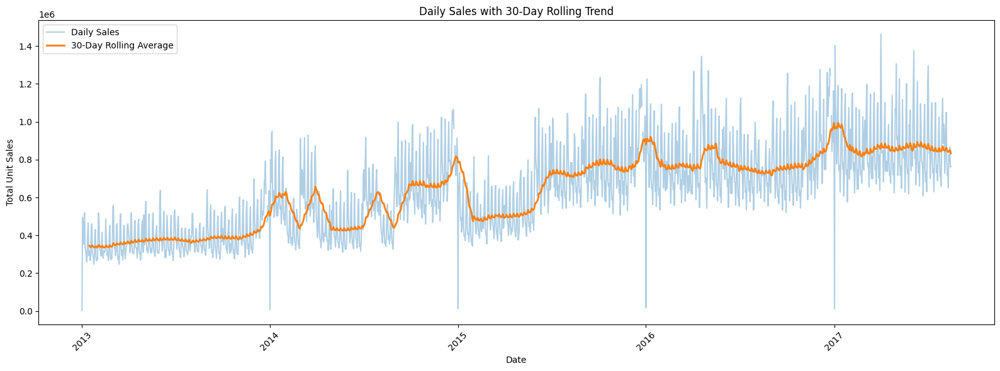

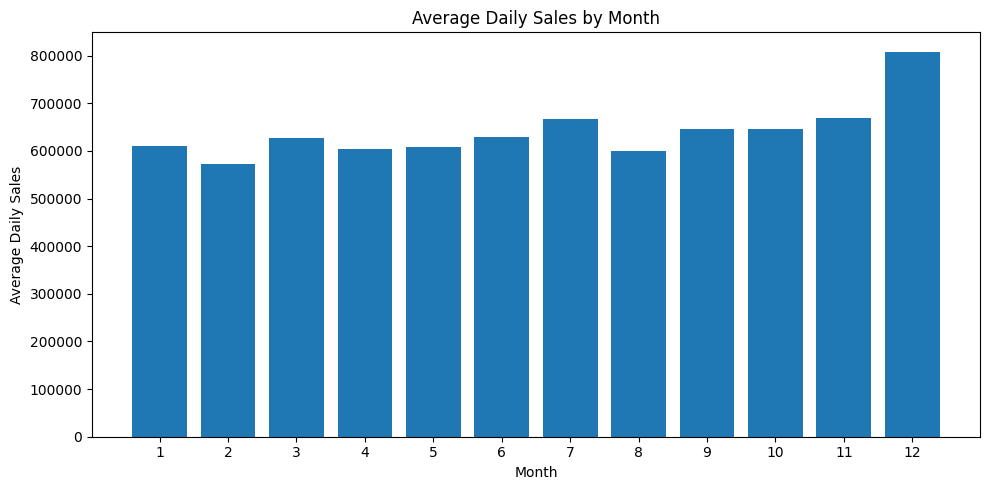

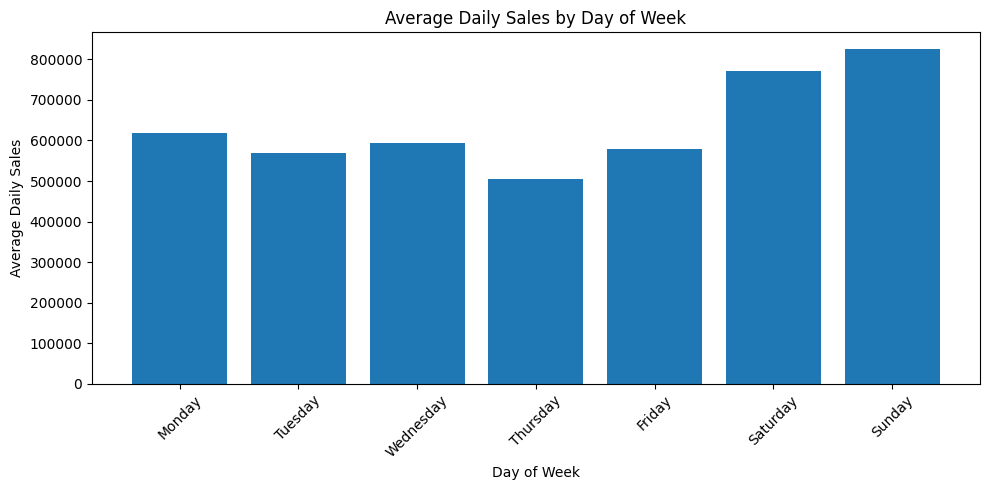


YEAR × MONTH — AVERAGE DAILY SALES


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2013,333142.314065,344962.849179,368661.194742,366448.757967,374119.419581,389644.535400,363141.890548,378638.320000,393097.741100,379858.689032,411884.343400,526745.404967
2014,610052.861326,429940.736968,656954.290961,428708.335220,431605.911668,443998.405743,626512.582068,447908.045755,667413.803810,657936.696358,684387.806853,811348.278857
2015,480545.840548,490799.816036,503180.887677,498502.005700,571947.233677,720103.944967,716439.291516,740763.685194,774696.082567,770266.505290,760165.078900,908132.522533
2016,773476.963968,756807.165586,746186.383355,865335.936867,798819.524452,740307.286000,756860.368645,724271.429613,747248.236567,775173.800581,821419.239867,987940.129400
2017,849294.159226,830361.120571,861419.377129,863176.849700,868123.846774,856092.270867,871337.889226,828888.195933,NaN,NaN,NaN,NaN


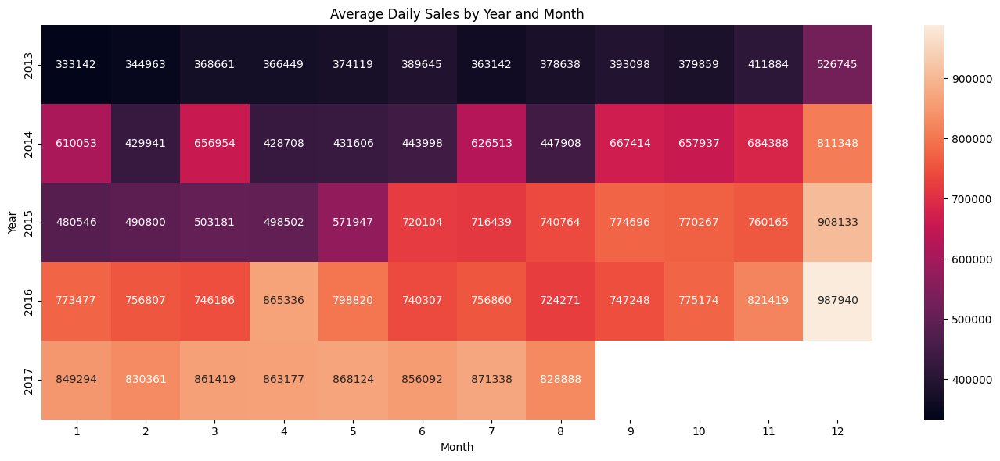

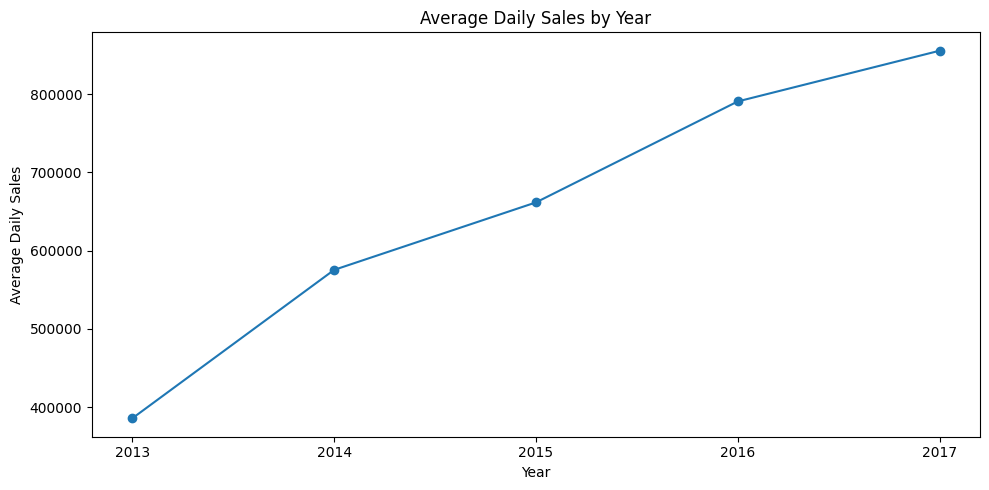


HOLIDAY VS NON-HOLIDAY SALES


,is_holiday,count,mean,median,category
0,0,1432,627536.722316,624853.7476,Non-Holiday
1,1,252,694355.882662,680788.3720,Holiday


In [76]:
# ============================================================
# STEP 14 — TREND AND SEASONALITY ANALYSIS
# ============================================================

# Make sure dates are datetime
daily_features["date"] = pd.to_datetime(daily_features["date"])


# ============================================================
# 1. YEARLY TOTAL SALES
# ============================================================

yearly_sales = (
    daily_features
    .dropna(subset=["total_sales"])
    .groupby("year")["total_sales"]
    .sum()
    .reset_index()
)

print("=" * 70)
print("YEARLY TOTAL SALES")
print("=" * 70)

display(yearly_sales)


# ============================================================
# 2. YEARLY AVERAGE DAILY SALES
# ============================================================

yearly_avg_sales = (
    daily_features
    .dropna(subset=["total_sales"])
    .groupby("year")["total_sales"]
    .mean()
    .reset_index()
)

print("\n" + "=" * 70)
print("YEARLY AVERAGE DAILY SALES")
print("=" * 70)

display(yearly_avg_sales)


# ============================================================
# 3. AVERAGE SALES BY MONTH
# ============================================================

monthly_pattern = (
    daily_features
    .dropna(subset=["total_sales"])
    .groupby("month")["total_sales"]
    .mean()
)

print("\n" + "=" * 70)
print("AVERAGE DAILY SALES BY MONTH")
print("=" * 70)

display(monthly_pattern)


# ============================================================
# 4. AVERAGE SALES BY DAY OF WEEK
# ============================================================

weekday_pattern = (
    daily_features
    .dropna(subset=["total_sales"])
    .groupby(
        ["day_of_week", "day_name"]
    )["total_sales"]
    .mean()
    .reset_index()
)

print("\n" + "=" * 70)
print("AVERAGE DAILY SALES BY DAY OF WEEK")
print("=" * 70)

display(weekday_pattern)


# ============================================================
# 5. 30-DAY ROLLING AVERAGE
# ============================================================

daily_features["rolling_30d"] = (
    daily_features["total_sales"]
    .rolling(window=30, min_periods=15)
    .mean()
)


# ============================================================
# 6. DAILY SALES + 30-DAY TREND
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    daily_features["date"],
    daily_features["total_sales"],
    alpha=0.35,
    label="Daily Sales"
)

plt.plot(
    daily_features["date"],
    daily_features["rolling_30d"],
    linewidth=2,
    label="30-Day Rolling Average"
)

plt.title("Daily Sales with 30-Day Rolling Trend")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 7. MONTHLY SEASONAL PATTERN
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_pattern.index,
    monthly_pattern.values
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()


# ============================================================
# 8. WEEKLY SEASONAL PATTERN
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    weekday_pattern["day_name"],
    weekday_pattern["total_sales"]
)

plt.title("Average Daily Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 9. YEAR × MONTH TABLE
# ============================================================

year_month_sales = (
    daily_features
    .dropna(subset=["total_sales"])
    .groupby(["year", "month"])["total_sales"]
    .mean()
    .unstack()
)

print("\n" + "=" * 70)
print("YEAR × MONTH — AVERAGE DAILY SALES")
print("=" * 70)

display(year_month_sales)


# ============================================================
# 10. YEAR × MONTH HEATMAP
# ============================================================

plt.figure(figsize=(14, 6))

sns.heatmap(
    year_month_sales,
    annot=True,
    fmt=".0f"
)

plt.title("Average Daily Sales by Year and Month")
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()


# ============================================================
# 11. YEARLY TREND PLOT
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_avg_sales["year"],
    yearly_avg_sales["total_sales"],
    marker="o"
)

plt.title("Average Daily Sales by Year")
plt.xlabel("Year")
plt.ylabel("Average Daily Sales")

plt.xticks(
    yearly_avg_sales["year"]
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. HOLIDAY VS NON-HOLIDAY SALES
# ============================================================

holiday_comparison = (
    daily_features
    .dropna(subset=["total_sales"])
    .groupby("is_holiday")["total_sales"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

holiday_comparison["category"] = (
    holiday_comparison["is_holiday"]
    .map({
        0: "Non-Holiday",
        1: "Holiday"
    })
)

print("\n" + "=" * 70)
print("HOLIDAY VS NON-HOLIDAY SALES")
print("=" * 70)

display(holiday_comparison)

MISSING VALUE CHECK
Remaining missing total_sales: 0
Structural missing days: 4

Structural missing dates:


,date,original_total_sales,total_sales,holiday_names,is_holiday,structural_missing
358,2013-12-25,NaN,0.0,Navidad,1,1
723,2014-12-25,NaN,0.0,Navidad,1,1
1088,2015-12-25,NaN,0.0,Navidad,1,1
1454,2016-12-25,NaN,0.0,Navidad,1,1



CHRISTMAS CHECK


,date,original_total_sales,total_sales,holiday_names,structural_missing
358,2013-12-25,NaN,0.0,Navidad,1
723,2014-12-25,NaN,0.0,Navidad,1
1088,2015-12-25,NaN,0.0,Navidad,1
1454,2016-12-25,NaN,0.0,Navidad,1



OUTLIER CHECK
Number of flagged outliers: 5

Outlier dates:


,date,total_sales,outlier_flag
1203,2016-04-18,1345920.605,1
1462,2017-01-02,1402305.371,1
1551,2017-04-01,1463083.963,1
1581,2017-05-01,1306699.367,1
1615,2017-06-04,1376511.520,1



FINAL FORECASTING SERIES
Shape: (1688, 19)
Date range: 2013-01-01 00:00:00 to 2017-08-15 00:00:00

Missing values:
date           0
total_sales    0
dtype: int64

Target summary:
count    1.688000e+03
mean     6.360250e+05
std      2.361585e+05
min      0.000000e+00
25%      4.408053e+05
50%      6.316926e+05
75%      7.855799e+05
max      1.463084e+06
Name: total_sales, dtype: float64


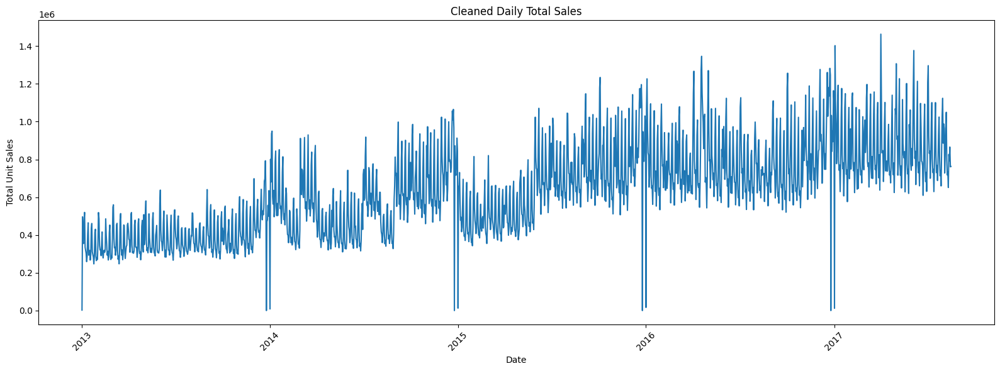


Saved:
/kaggle/working/final_forecasting_dataset.csv


In [77]:
# ============================================================
# STEP 15 — FINALIZE MISSING VALUES + CLEAN FORECAST SERIES
# ============================================================

# Make a copy so we keep the original daily_features unchanged
forecast_df = daily_features.copy()

# ------------------------------------------------------------
# 1. Preserve the original sales values
# ------------------------------------------------------------

forecast_df["original_total_sales"] = forecast_df["total_sales"]


# ------------------------------------------------------------
# 2. Identify structural missing sales days
# ------------------------------------------------------------

forecast_df["structural_missing"] = (
    forecast_df["total_sales"].isna() &
    (forecast_df["is_holiday"] == 1)
).astype(int)


# ------------------------------------------------------------
# 3. Fill structural missing sales with 0
# ------------------------------------------------------------

forecast_df["total_sales"] = forecast_df["total_sales"].fillna(0)


# ------------------------------------------------------------
# 4. Check whether any missing values remain
# ------------------------------------------------------------

print("=" * 70)
print("MISSING VALUE CHECK")
print("=" * 70)

print("Remaining missing total_sales:",
      forecast_df["total_sales"].isna().sum())

print("Structural missing days:",
      forecast_df["structural_missing"].sum())

print("\nStructural missing dates:")
display(
    forecast_df[
        forecast_df["structural_missing"] == 1
    ][[
        "date",
        "original_total_sales",
        "total_sales",
        "holiday_names",
        "is_holiday",
        "structural_missing"
    ]]
)


# ------------------------------------------------------------
# 5. Confirm the four Christmas dates
# ------------------------------------------------------------

christmas_check = forecast_df[
    (forecast_df["month"] == 12) &
    (forecast_df["day"] == 25)
][[
    "date",
    "original_total_sales",
    "total_sales",
    "holiday_names",
    "structural_missing"
]]

print("\n" + "=" * 70)
print("CHRISTMAS CHECK")
print("=" * 70)

display(christmas_check)


# ------------------------------------------------------------
# 6. IQR outlier flag
# ------------------------------------------------------------

Q1 = forecast_df["total_sales"].quantile(0.25)
Q3 = forecast_df["total_sales"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

forecast_df["outlier_flag"] = (
    (forecast_df["total_sales"] < lower_bound) |
    (forecast_df["total_sales"] > upper_bound)
).astype(int)

print("\n" + "=" * 70)
print("OUTLIER CHECK")
print("=" * 70)

print("Number of flagged outliers:",
      forecast_df["outlier_flag"].sum())

print("\nOutlier dates:")
display(
    forecast_df[
        forecast_df["outlier_flag"] == 1
    ][[
        "date",
        "total_sales",
        "outlier_flag"
    ]]
)


# ------------------------------------------------------------
# 7. Check final target series
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL FORECASTING SERIES")
print("=" * 70)

print("Shape:", forecast_df.shape)

print("Date range:",
      forecast_df["date"].min(),
      "to",
      forecast_df["date"].max())

print("\nMissing values:")
print(
    forecast_df[
        ["date", "total_sales"]
    ].isna().sum()
)

print("\nTarget summary:")
print(
    forecast_df["total_sales"].describe()
)


# ------------------------------------------------------------
# 8. Plot cleaned series
# ------------------------------------------------------------

plt.figure(figsize=(16, 6))

plt.plot(
    forecast_df["date"],
    forecast_df["total_sales"]
)

plt.title("Cleaned Daily Total Sales")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Save cleaned forecasting dataset
# ------------------------------------------------------------

forecast_df.to_csv(
    "/kaggle/working/final_forecasting_dataset.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/final_forecasting_dataset.csv")

TIME SERIES
Observations: 1688
Start: 2013-01-01 00:00:00
End: 2017-08-15 00:00:00

ADF TEST — Original Daily Sales
ADF Statistic: -2.5720624110192998
p-value: 0.09890995770646704
Used Lags: 22
Number of Observations: 1665

Critical Values:
   1%: -3.434283579780684
   5%: -2.863277451883613
   10%: -2.5676949772294817

Conclusion: Fail to reject H0 → Series is non-stationary.

ADF TEST — First Difference
ADF Statistic: -11.313717274814557
p-value: 1.2211377680277665e-20
Used Lags: 25
Number of Observations: 1661

Critical Values:
   1%: -3.4342930672797065
   5%: -2.8632816397229064
   10%: -2.567697207194407

Conclusion: Reject H0 → Series is stationary.

ADF TEST — 7-Day Seasonal Difference
ADF Statistic: -12.757490572709646
p-value: 8.279130434115295e-24
Used Lags: 22
Number of Observations: 1658

Critical Values:
   1%: -3.434300212992577
   5%: -2.863284793874921
   10%: -2.567698886736967

Conclusion: Reject H0 → Series is stationary.


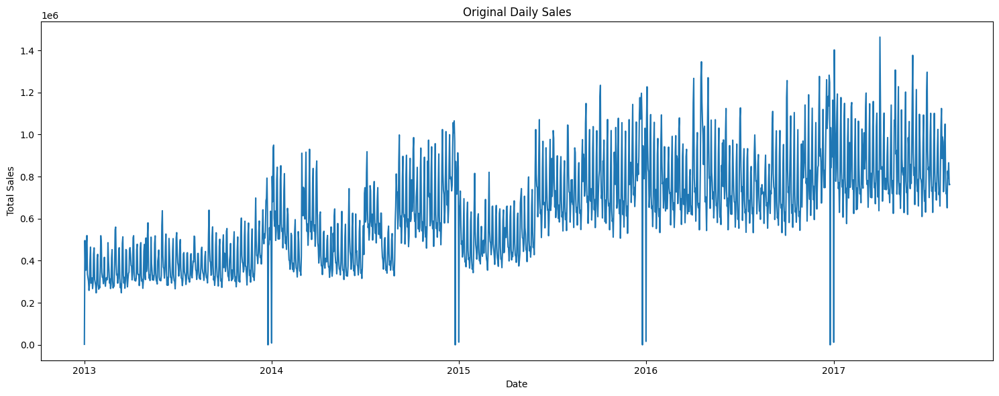

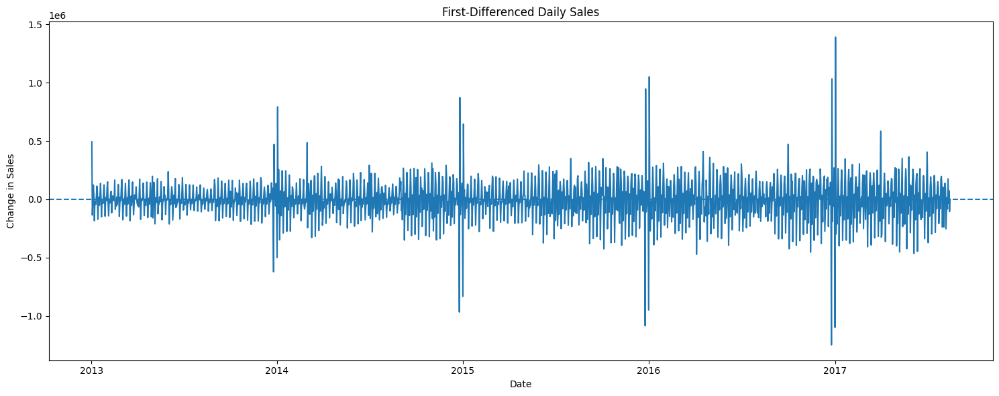

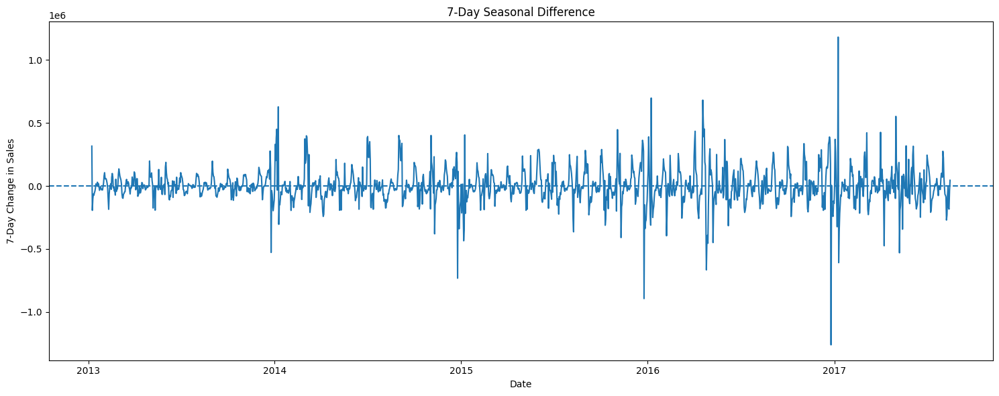


Saved:
/kaggle/working/stationarity_analysis.csv


In [78]:
# ============================================================
# STEP 16 — STATIONARITY TEST (ADF)
# ============================================================

from statsmodels.tsa.stattools import adfuller

# ------------------------------------------------------------
# 1. Prepare the time series
# ------------------------------------------------------------

ts = (
    forecast_df
    .set_index("date")["total_sales"]
    .asfreq("D")
)

print("=" * 70)
print("TIME SERIES")
print("=" * 70)

print("Observations:", len(ts))
print("Start:", ts.index.min())
print("End:", ts.index.max())


# ------------------------------------------------------------
# 2. Function for ADF test
# ------------------------------------------------------------

def adf_test(series, name):
    
    result = adfuller(
        series.dropna(),
        autolag="AIC"
    )
    
    print("\n" + "=" * 70)
    print(f"ADF TEST — {name}")
    print("=" * 70)
    
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    print("Used Lags:", result[2])
    print("Number of Observations:", result[3])
    
    print("\nCritical Values:")
    
    for key, value in result[4].items():
        print(f"   {key}: {value}")
    
    if result[1] < 0.05:
        print("\nConclusion: Reject H0 → Series is stationary.")
    else:
        print("\nConclusion: Fail to reject H0 → Series is non-stationary.")
    
    return result


# ------------------------------------------------------------
# 3. ADF on original series
# ------------------------------------------------------------

adf_original = adf_test(
    ts,
    "Original Daily Sales"
)


# ------------------------------------------------------------
# 4. First-order differencing
# ------------------------------------------------------------

ts_diff1 = ts.diff(1)

adf_diff1 = adf_test(
    ts_diff1,
    "First Difference"
)


# ------------------------------------------------------------
# 5. Seven-day seasonal difference
# ------------------------------------------------------------

ts_diff7 = ts.diff(7)

adf_diff7 = adf_test(
    ts_diff7,
    "7-Day Seasonal Difference"
)


# ------------------------------------------------------------
# 6. Plot original vs first difference
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    ts.index,
    ts.values
)

plt.title("Original Daily Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 6))

plt.plot(
    ts_diff1.index,
    ts_diff1.values
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("First-Differenced Daily Sales")
plt.xlabel("Date")
plt.ylabel("Change in Sales")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Plot 7-day seasonal difference
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    ts_diff7.index,
    ts_diff7.values
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("7-Day Seasonal Difference")
plt.xlabel("Date")
plt.ylabel("7-Day Change in Sales")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Save the stationary/differenced series
# ------------------------------------------------------------

stationarity_df = pd.DataFrame({
    "date": ts.index,
    "sales": ts.values,
    "diff_1": ts_diff1.values,
    "diff_7": ts_diff7.values
})

stationarity_df.to_csv(
    "/kaggle/working/stationarity_analysis.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/stationarity_analysis.csv")

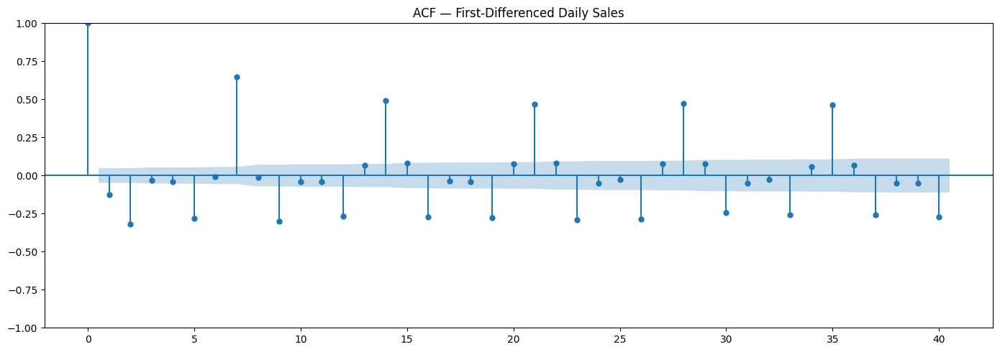

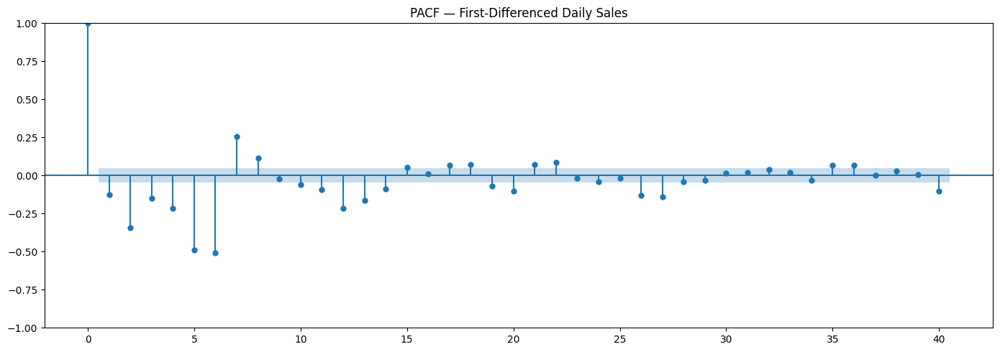

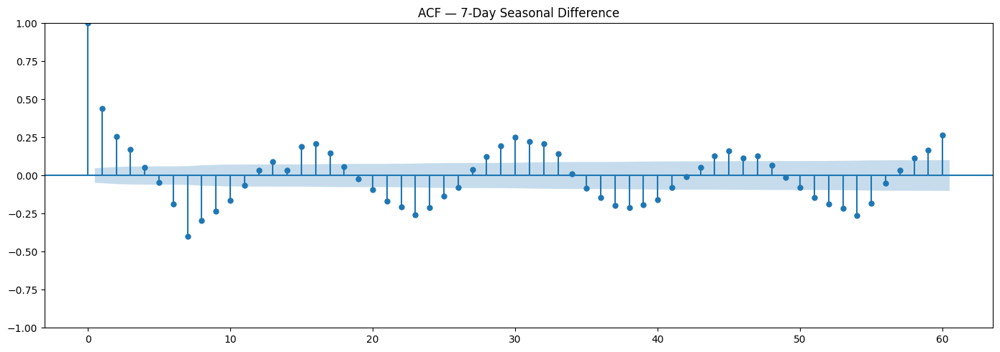

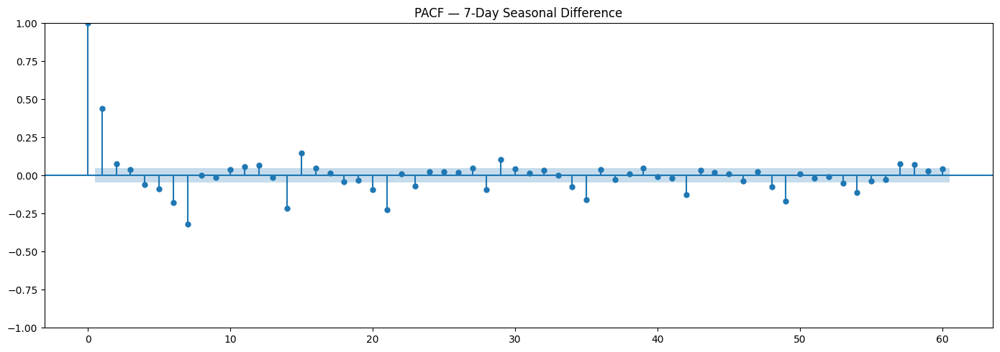

ACF VALUES — FIRST DIFFERENCE
Lag  0: 1.0000
Lag  1: -0.1263
Lag  2: -0.3196
Lag  3: -0.0323
Lag  4: -0.0412
Lag  5: -0.2805
Lag  6: -0.0064
Lag  7: 0.6458
Lag  8: -0.0105
Lag  9: -0.2993
Lag 10: -0.0410
Lag 11: -0.0405
Lag 12: -0.2659
Lag 13: 0.0695
Lag 14: 0.4919

PACF VALUES — FIRST DIFFERENCE
Lag  0: 1.0000
Lag  1: -0.1263
Lag  2: -0.3410
Lag  3: -0.1489
Lag  4: -0.2165
Lag  5: -0.4879
Lag  6: -0.5063
Lag  7: 0.2582
Lag  8: 0.1130
Lag  9: -0.0223
Lag 10: -0.0621
Lag 11: -0.0919
Lag 12: -0.2165
Lag 13: -0.1621
Lag 14: -0.0904

IMPORTANT ACF LAGS — 7-DAY DIFFERENCE
Lag  1: 0.4383
Lag  2: 0.2558
Lag  3: 0.1698
Lag  6: -0.1882
Lag  7: -0.3984
Lag  8: -0.2970
Lag 14: 0.0328
Lag 21: -0.1682
Lag 28: 0.1264


In [79]:
# ============================================================
# STEP 17 — ACF AND PACF ANALYSIS
# ============================================================

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

# ------------------------------------------------------------
# 1. Prepare stationary series
# ------------------------------------------------------------

# First difference
diff1 = ts.diff(1).dropna()

# 7-day seasonal difference
diff7 = ts.diff(7).dropna()


# ============================================================
# 2. ACF — FIRST DIFFERENCE
# ============================================================

plt.figure(figsize=(14, 5))

plot_acf(
    diff1,
    lags=40,
    ax=plt.gca()
)

plt.title("ACF — First-Differenced Daily Sales")
plt.tight_layout()
plt.show()


# ============================================================
# 3. PACF — FIRST DIFFERENCE
# ============================================================

plt.figure(figsize=(14, 5))

plot_pacf(
    diff1,
    lags=40,
    method="ywm",
    ax=plt.gca()
)

plt.title("PACF — First-Differenced Daily Sales")
plt.tight_layout()
plt.show()


# ============================================================
# 4. ACF — 7-DAY SEASONAL DIFFERENCE
# ============================================================

plt.figure(figsize=(14, 5))

plot_acf(
    diff7,
    lags=60,
    ax=plt.gca()
)

plt.title("ACF — 7-Day Seasonal Difference")
plt.tight_layout()
plt.show()


# ============================================================
# 5. PACF — 7-DAY SEASONAL DIFFERENCE
# ============================================================

plt.figure(figsize=(14, 5))

plot_pacf(
    diff7,
    lags=60,
    method="ywm",
    ax=plt.gca()
)

plt.title("PACF — 7-Day Seasonal Difference")
plt.tight_layout()
plt.show()


# ============================================================
# 6. NUMERICAL ACF VALUES
# ============================================================

acf_values = acf(
    diff1,
    nlags=14,
    fft=True
)

print("=" * 70)
print("ACF VALUES — FIRST DIFFERENCE")
print("=" * 70)

for lag, value in enumerate(acf_values):
    print(f"Lag {lag:2d}: {value:.4f}")


# ============================================================
# 7. NUMERICAL PACF VALUES
# ============================================================

pacf_values = pacf(
    diff1,
    nlags=14,
    method="ywm"
)

print("\n" + "=" * 70)
print("PACF VALUES — FIRST DIFFERENCE")
print("=" * 70)

for lag, value in enumerate(pacf_values):
    print(f"Lag {lag:2d}: {value:.4f}")


# ============================================================
# 8. IMPORTANT SEASONAL LAGS
# ============================================================

acf_seasonal = acf(
    diff7,
    nlags=28,
    fft=True
)

print("\n" + "=" * 70)
print("IMPORTANT ACF LAGS — 7-DAY DIFFERENCE")
print("=" * 70)

for lag in [1, 2, 3, 6, 7, 8, 14, 21, 28]:
    print(
        f"Lag {lag:2d}: "
        f"{acf_seasonal[lag]:.4f}"
    )

TIME SERIES SPLIT

TRAIN
Start: 2013-01-01 00:00:00
End: 2016-02-15 00:00:00
Observations: 1141

VALIDATION
Start: 2016-02-16 00:00:00
End: 2016-08-15 00:00:00
Observations: 182

TEST
Start: 2016-08-16 00:00:00
End: 2017-08-15 00:00:00
Observations: 365

MISSING VALUE CHECK
Train missing: 0
Validation missing: 0
Test missing: 0

OVERLAP CHECK
Train ∩ Validation: 0
Validation ∩ Test: 0
Train ∩ Test: 0


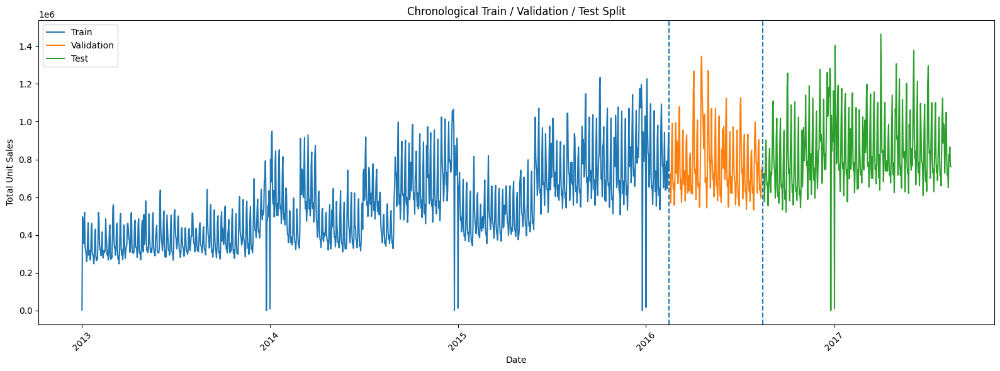


Saved:
/kaggle/working/train_timeseries.csv
/kaggle/working/validation_timeseries.csv
/kaggle/working/test_timeseries.csv


In [80]:
# ============================================================
# STEP 18 — CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# ------------------------------------------------------------
# 1. Prepare the time series
# ------------------------------------------------------------

model_df = (
    forecast_df[
        ["date", "total_sales"]
    ]
    .copy()
    .sort_values("date")
)

model_df["date"] = pd.to_datetime(
    model_df["date"]
)

model_df = model_df.set_index("date")

# Make sure we have a complete daily frequency
model_df = model_df.asfreq("D")


# ------------------------------------------------------------
# 2. Define split dates
# ------------------------------------------------------------

train_end = pd.Timestamp("2016-02-15")

validation_end = pd.Timestamp("2016-08-15")

test_start = validation_end + pd.Timedelta(days=1)


# ------------------------------------------------------------
# 3. Create the three datasets
# ------------------------------------------------------------

train_ts = model_df.loc[
    model_df.index <= train_end,
    "total_sales"
].copy()

validation_ts = model_df.loc[
    (model_df.index > train_end) &
    (model_df.index <= validation_end),
    "total_sales"
].copy()

test_ts = model_df.loc[
    model_df.index >= test_start,
    "total_sales"
].copy()


# ------------------------------------------------------------
# 4. Display split information
# ------------------------------------------------------------

print("=" * 70)
print("TIME SERIES SPLIT")
print("=" * 70)

print("\nTRAIN")
print("Start:", train_ts.index.min())
print("End:", train_ts.index.max())
print("Observations:", len(train_ts))

print("\nVALIDATION")
print("Start:", validation_ts.index.min())
print("End:", validation_ts.index.max())
print("Observations:", len(validation_ts))

print("\nTEST")
print("Start:", test_ts.index.min())
print("End:", test_ts.index.max())
print("Observations:", len(test_ts))


# ------------------------------------------------------------
# 5. Check for missing values
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MISSING VALUE CHECK")
print("=" * 70)

print("Train missing:", train_ts.isna().sum())
print("Validation missing:", validation_ts.isna().sum())
print("Test missing:", test_ts.isna().sum())


# ------------------------------------------------------------
# 6. Check that dates do not overlap
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OVERLAP CHECK")
print("=" * 70)

print(
    "Train ∩ Validation:",
    len(train_ts.index.intersection(validation_ts.index))
)

print(
    "Validation ∩ Test:",
    len(validation_ts.index.intersection(test_ts.index))
)

print(
    "Train ∩ Test:",
    len(train_ts.index.intersection(test_ts.index))
)


# ------------------------------------------------------------
# 7. Plot the split
# ------------------------------------------------------------

plt.figure(figsize=(16, 6))

plt.plot(
    train_ts.index,
    train_ts.values,
    label="Train"
)

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Validation"
)

plt.plot(
    test_ts.index,
    test_ts.values,
    label="Test"
)

plt.axvline(
    train_end,
    linestyle="--"
)

plt.axvline(
    validation_end,
    linestyle="--"
)

plt.title("Chronological Train / Validation / Test Split")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Save the splits
# ------------------------------------------------------------

train_ts.to_csv(
    "/kaggle/working/train_timeseries.csv",
    header=True
)

validation_ts.to_csv(
    "/kaggle/working/validation_timeseries.csv",
    header=True
)

test_ts.to_csv(
    "/kaggle/working/test_timeseries.csv",
    header=True
)

print("\nSaved:")
print("/kaggle/working/train_timeseries.csv")
print("/kaggle/working/validation_timeseries.csv")
print("/kaggle/working/test_timeseries.csv")

BASELINE MODEL RESULTS — VALIDATION SET


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Naive,130410.733,168915.085,16.084,60.773,0
1,Seasonal Naive (7-day),116352.289,165783.896,14.426,80.663,0


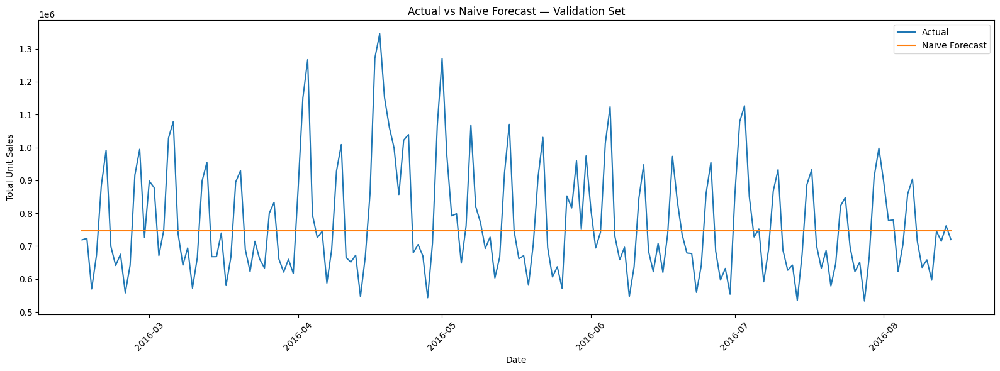

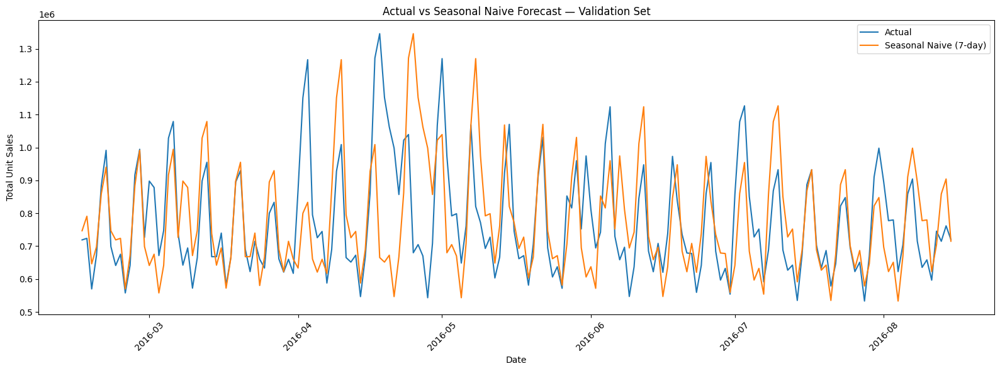


Saved:
/kaggle/working/baseline_results.csv


In [81]:
# ============================================================
# STEP 19 — BASELINE FORECASTS + EVALUATION METRICS
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. FUNCTION TO CALCULATE FORECAST METRICS
# ============================================================

def calculate_metrics(actual, predicted, name="Model"):

    actual = pd.Series(actual).reset_index(drop=True)
    predicted = pd.Series(predicted).reset_index(drop=True)

    # -------------------------------
    # MAE
    # -------------------------------
    mae = mean_absolute_error(
        actual,
        predicted
    )

    # -------------------------------
    # RMSE
    # -------------------------------
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    # -------------------------------
    # MAPE
    # Exclude actual zero values
    # -------------------------------
    non_zero_mask = actual != 0

    mape = (
        np.mean(
            np.abs(
                (
                    actual[non_zero_mask]
                    - predicted[non_zero_mask]
                )
                /
                actual[non_zero_mask]
            )
        )
        * 100
    )

    excluded_from_mape = (
        (~non_zero_mask).sum()
    )

    # -------------------------------
    # Directional Accuracy
    # -------------------------------
    # Compare:
    # actual direction:
    # actual[t] - actual[t-1]
    #
    # predicted direction:
    # predicted[t] - actual[t-1]
    #
    # This measures whether the forecast
    # gets the direction of movement correct.
    # -------------------------------

    actual_direction = np.sign(
        actual.diff()
    )

    predicted_direction = np.sign(
        predicted - actual.shift(1)
    )

    direction_mask = (
        actual_direction.notna()
        & predicted_direction.notna()
    )

    directional_accuracy = (
        np.mean(
            actual_direction[direction_mask]
            ==
            predicted_direction[direction_mask]
        )
        * 100
    )

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "Directional Accuracy (%)":
            directional_accuracy,
        "MAPE Zero Exclusions":
            excluded_from_mape
    }


# ============================================================
# 2. NAIVE FORECAST
# ============================================================

# Every validation prediction is the
# last known training value.

naive_predictions = pd.Series(
    train_ts.iloc[-1],
    index=validation_ts.index
)


# ============================================================
# 3. SEASONAL NAIVE FORECAST
# ============================================================

# Use the value from 7 days earlier.

combined_series = pd.concat([
    train_ts,
    validation_ts
])

seasonal_naive_predictions = (
    combined_series
    .shift(7)
    .loc[validation_ts.index]
)


# ============================================================
# 4. EVALUATE NAIVE
# ============================================================

naive_metrics = calculate_metrics(
    validation_ts,
    naive_predictions,
    "Naive"
)


# ============================================================
# 5. EVALUATE SEASONAL NAIVE
# ============================================================

seasonal_naive_metrics = calculate_metrics(
    validation_ts,
    seasonal_naive_predictions,
    "Seasonal Naive (7-day)"
)


# ============================================================
# 6. CREATE MODEL COMPARISON TABLE
# ============================================================

baseline_results = pd.DataFrame([
    naive_metrics,
    seasonal_naive_metrics
])

print("=" * 70)
print("BASELINE MODEL RESULTS — VALIDATION SET")
print("=" * 70)

display(
    baseline_results.round(3)
)


# ============================================================
# 7. COMPARE ACTUAL VS NAIVE
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    naive_predictions.values,
    label="Naive Forecast"
)

plt.title(
    "Actual vs Naive Forecast — Validation Set"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 8. COMPARE ACTUAL VS SEASONAL NAIVE
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    seasonal_naive_predictions.values,
    label="Seasonal Naive (7-day)"
)

plt.title(
    "Actual vs Seasonal Naive Forecast — Validation Set"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 9. SAVE BASELINE RESULTS
# ============================================================

baseline_results.to_csv(
    "/kaggle/working/baseline_results.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/baseline_results.csv")

TRAINING ARIMA(2,1,2)
                               SARIMAX Results                                
Dep. Variable:            total_sales   No. Observations:                 1141
Model:                 ARIMA(2, 1, 2)   Log Likelihood              -15004.490
Date:                Thu, 17 Sep 2026   AIC                          30018.980
Time:                        10:22:43   BIC                          30044.174
Sample:                    01-01-2013   HQIC                         30028.494
                         - 02-15-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9263      0.050     18.587      0.000       0.829       1.024
ar.L2         -0.5357      0.022    -24.782      0.000      -0.578      -0.493
ma.L1         -1.4080      0.0

date
2016-02-16    690874.463369
2016-02-17    703516.013580
2016-02-18    745114.892837
2016-02-19    776875.028098
2016-02-20    784009.877172
2016-02-21    773605.385720
2016-02-22    760145.963181
2016-02-23    753252.337950
2016-02-24    754076.913737
2016-02-25    758533.485490
Freq: D, Name: predicted_mean, dtype: float64


ARIMA RESULTS — VALIDATION SET


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,"ARIMA(2,1,2)",132584.086,166812.358,16.677,60.773,0



BASELINE vs ARIMA


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Naive,130410.733,168915.085,16.084,60.773,0
1,Seasonal Naive (7-day),116352.289,165783.896,14.426,80.663,0
2,"ARIMA(2,1,2)",132584.086,166812.358,16.677,60.773,0


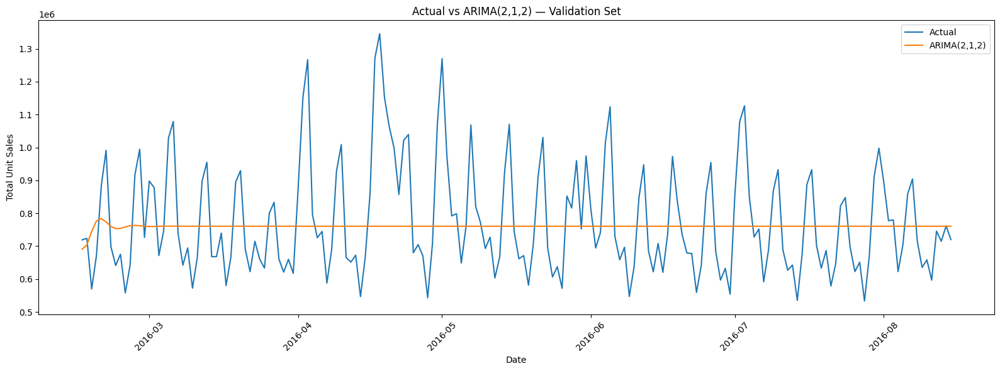

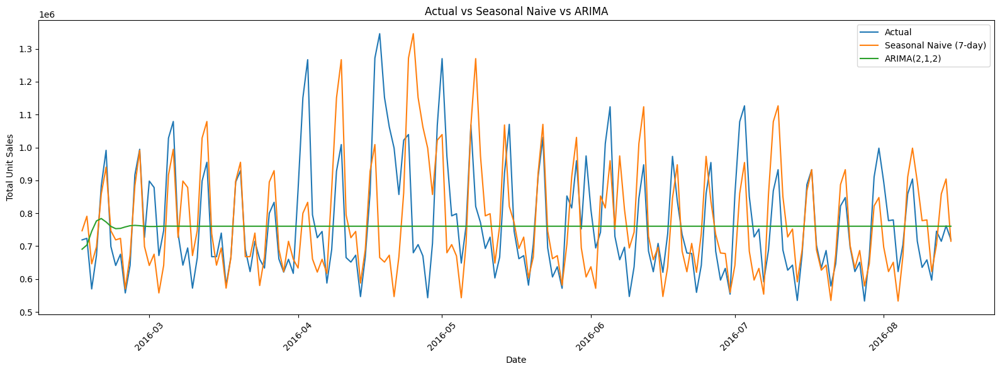


Saved:
/kaggle/working/arima_results.csv
/kaggle/working/arima_validation_predictions.csv


In [82]:
# ============================================================
# STEP 20 — ARIMA MODEL
# ============================================================

from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings("ignore")


# ============================================================
# 1. TRAIN ARIMA(2,1,2)
# ============================================================

print("=" * 70)
print("TRAINING ARIMA(2,1,2)")
print("=" * 70)

arima_model = ARIMA(
    train_ts,
    order=(2, 1, 2)
)

arima_result = arima_model.fit()

print(arima_result.summary())


# ============================================================
# 2. FORECAST VALIDATION PERIOD
# ============================================================

arima_predictions = arima_result.forecast(
    steps=len(validation_ts)
)

# Make sure prediction index matches validation dates
arima_predictions.index = validation_ts.index


print("\n" + "=" * 70)
print("ARIMA FORECAST")
print("=" * 70)

print("Forecast observations:", len(arima_predictions))

display(
    arima_predictions.head(10)
)


# ============================================================
# 3. EVALUATE ARIMA
# ============================================================

arima_metrics = calculate_metrics(
    validation_ts,
    arima_predictions,
    "ARIMA(2,1,2)"
)

arima_results = pd.DataFrame([
    arima_metrics
])


print("\n" + "=" * 70)
print("ARIMA RESULTS — VALIDATION SET")
print("=" * 70)

display(
    arima_results.round(3)
)


# ============================================================
# 4. COMBINE WITH BASELINES
# ============================================================

all_model_results = pd.concat(
    [
        baseline_results,
        arima_results
    ],
    ignore_index=True
)

print("\n" + "=" * 70)
print("BASELINE vs ARIMA")
print("=" * 70)

display(
    all_model_results.round(3)
)


# ============================================================
# 5. ACTUAL VS ARIMA FORECAST
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    arima_predictions.index,
    arima_predictions.values,
    label="ARIMA(2,1,2)"
)

plt.title(
    "Actual vs ARIMA(2,1,2) — Validation Set"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 6. ACTUAL vs ARIMA vs SEASONAL NAIVE
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    seasonal_naive_predictions.values,
    label="Seasonal Naive (7-day)"
)

plt.plot(
    validation_ts.index,
    arima_predictions.values,
    label="ARIMA(2,1,2)"
)

plt.title(
    "Actual vs Seasonal Naive vs ARIMA"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 7. SAVE ARIMA RESULTS
# ============================================================

arima_results.to_csv(
    "/kaggle/working/arima_results.csv",
    index=False
)

arima_predictions.to_csv(
    "/kaggle/working/arima_validation_predictions.csv",
    header=["prediction"]
)

print("\nSaved:")
print("/kaggle/working/arima_results.csv")
print("/kaggle/working/arima_validation_predictions.csv")

TRAINING SARIMA(1,1,1)(1,0,1,7)
                                     SARIMAX Results                                     
Dep. Variable:                       total_sales   No. Observations:                 1141
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 7)   Log Likelihood              -14725.291
Date:                           Thu, 17 Sep 2026   AIC                          29460.581
Time:                                   10:23:17   BIC                          29485.736
Sample:                               01-01-2013   HQIC                         29470.084
                                    - 02-15-2016                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2253      0.058      3.882      0.000       0.112       0.339
ma.L1      

date
2016-02-16    705168.867134
2016-02-17    743102.880224
2016-02-18    617150.448352
2016-02-19    603840.161236
2016-02-20    914889.122419
2016-02-21    984993.619829
2016-02-22    730863.320173
2016-02-23    700243.537279
2016-02-24    740759.791252
2016-02-25    615016.839204
Freq: D, Name: predicted_mean, dtype: float64


SARIMA RESULTS — VALIDATION SET


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,"SARIMA(1,1,1)(1,0,1,7)",81682.163,122035.23,9.834,82.873,0



CURRENT MODEL COMPARISON


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Naive,130410.733,168915.085,16.084,60.773,0
1,Seasonal Naive (7-day),116352.289,165783.896,14.426,80.663,0
2,"ARIMA(2,1,2)",132584.086,166812.358,16.677,60.773,0
3,"SARIMA(1,1,1)(1,0,1,7)",81682.163,122035.230,9.834,82.873,0


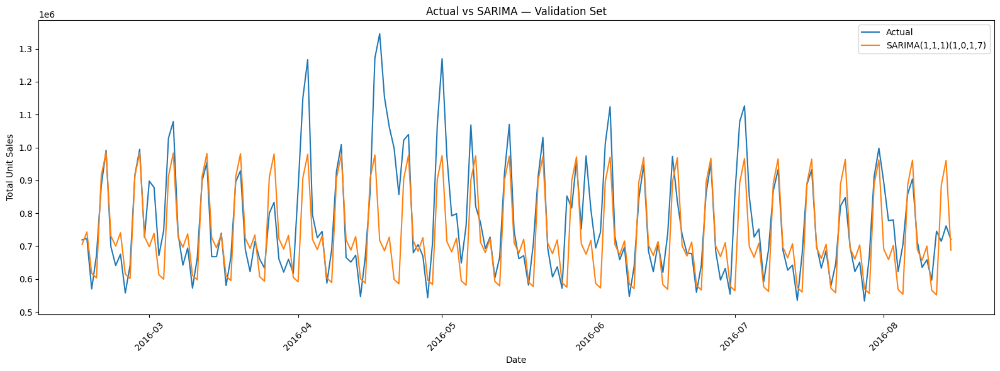

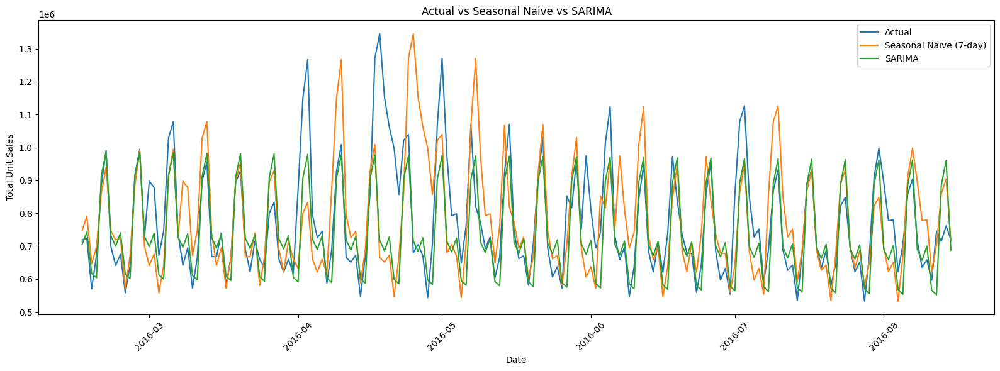


Saved:
/kaggle/working/sarima_results.csv
/kaggle/working/sarima_validation_predictions.csv


In [83]:
# ============================================================
# STEP 21 — SARIMA WITH 7-DAY SEASONALITY
# ============================================================

from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings

warnings.filterwarnings("ignore")


# ============================================================
# 1. TRAIN SARIMA
# ============================================================

print("=" * 70)
print("TRAINING SARIMA(1,1,1)(1,0,1,7)")
print("=" * 70)

sarima_model = SARIMAX(
    train_ts,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(
    disp=False
)

print(sarima_result.summary())


# ============================================================
# 2. FORECAST VALIDATION PERIOD
# ============================================================

sarima_predictions = sarima_result.forecast(
    steps=len(validation_ts)
)

sarima_predictions.index = validation_ts.index


print("\n" + "=" * 70)
print("SARIMA FORECAST")
print("=" * 70)

print("Forecast observations:",
      len(sarima_predictions))

display(
    sarima_predictions.head(10)
)


# ============================================================
# 3. EVALUATE SARIMA
# ============================================================

sarima_metrics = calculate_metrics(
    validation_ts,
    sarima_predictions,
    "SARIMA(1,1,1)(1,0,1,7)"
)

sarima_results = pd.DataFrame([
    sarima_metrics
])


print("\n" + "=" * 70)
print("SARIMA RESULTS — VALIDATION SET")
print("=" * 70)

display(
    sarima_results.round(3)
)


# ============================================================
# 4. COMPARE ALL CURRENT MODELS
# ============================================================

all_model_results = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results
    ],
    ignore_index=True
)

print("\n" + "=" * 70)
print("CURRENT MODEL COMPARISON")
print("=" * 70)

display(
    all_model_results.round(3)
)


# ============================================================
# 5. ACTUAL VS SARIMA
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions.values,
    label="SARIMA(1,1,1)(1,0,1,7)"
)

plt.title(
    "Actual vs SARIMA — Validation Set"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 6. ACTUAL VS SEASONAL NAIVE VS SARIMA
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    seasonal_naive_predictions.values,
    label="Seasonal Naive (7-day)"
)

plt.plot(
    validation_ts.index,
    sarima_predictions.values,
    label="SARIMA"
)

plt.title(
    "Actual vs Seasonal Naive vs SARIMA"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 7. SAVE RESULTS
# ============================================================

sarima_results.to_csv(
    "/kaggle/working/sarima_results.csv",
    index=False
)

sarima_predictions.to_csv(
    "/kaggle/working/sarima_validation_predictions.csv",
    header=["prediction"]
)

print("\nSaved:")
print("/kaggle/working/sarima_results.csv")
print("/kaggle/working/sarima_validation_predictions.csv")

TRAINING EXPONENTIAL SMOOTHING
                       ExponentialSmoothing Model Results                       
Dep. Variable:              total_sales   No. Observations:                 1141
Model:             ExponentialSmoothing   SSE                  9657752692181.510
Optimized:                         True   AIC                          26104.258
Trend:                         Additive   BIC                          26159.694
Seasonal:                      Additive   AICC                         26104.581
Seasonal Periods:                     7   Date:                 Thu, 17 Sep 2026
Box-Cox:                          False   Time:                         10:23:53
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level               0.2830083                alpha                

date
2016-02-16    699009.945678
2016-02-17    732652.767540
2016-02-18    610915.878351
2016-02-19    615725.317904
2016-02-20    914263.998378
2016-02-21    982844.936963
2016-02-22    733963.948973
2016-02-23    701513.321654
2016-02-24    735156.143516
2016-02-25    613419.254327
Freq: D, dtype: float64


EXPONENTIAL SMOOTHING RESULTS


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Exponential Smoothing,88279.886,119269.202,11.178,80.11,0



CURRENT MODEL COMPARISON


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Naive,130410.733,168915.085,16.084,60.773,0
1,Seasonal Naive (7-day),116352.289,165783.896,14.426,80.663,0
2,"ARIMA(2,1,2)",132584.086,166812.358,16.677,60.773,0
3,"SARIMA(1,1,1)(1,0,1,7)",81682.163,122035.230,9.834,82.873,0
4,Exponential Smoothing,88279.886,119269.202,11.178,80.110,0


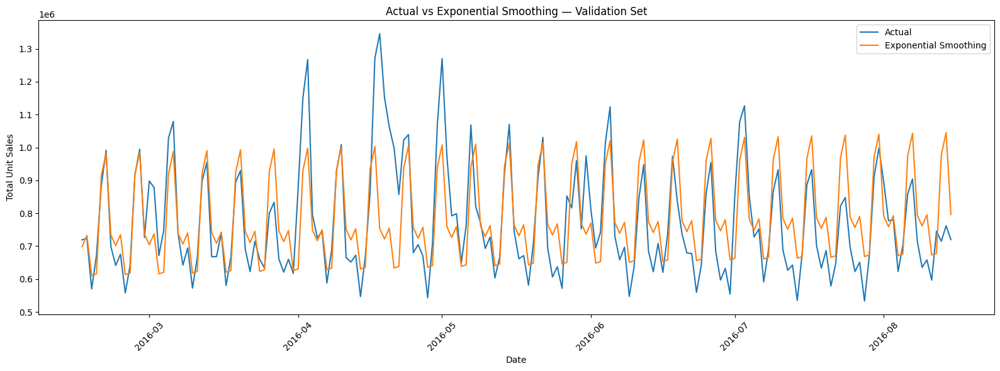

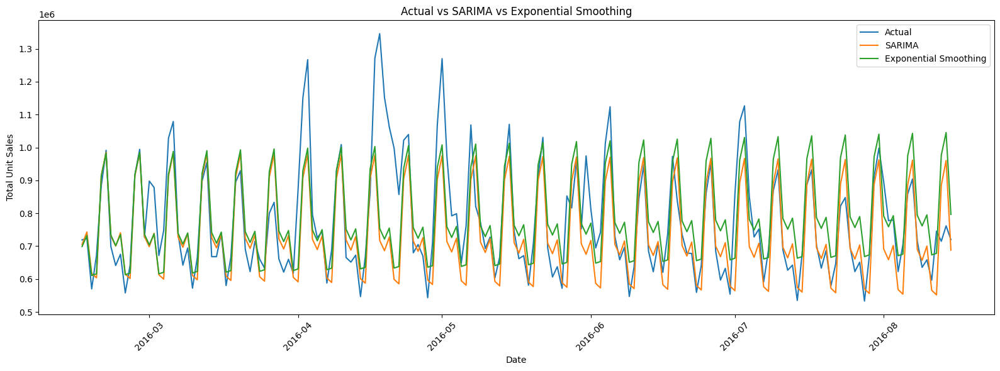


Saved:
/kaggle/working/exponential_smoothing_results.csv
/kaggle/working/exponential_smoothing_predictions.csv


In [84]:
# ============================================================
# STEP 22 — EXPONENTIAL SMOOTHING / HOLT-WINTERS
# ============================================================

from statsmodels.tsa.holtwinters import ExponentialSmoothing
import warnings

warnings.filterwarnings("ignore")


# ============================================================
# 1. TRAIN HOLT-WINTERS MODEL
# ============================================================

print("=" * 70)
print("TRAINING EXPONENTIAL SMOOTHING")
print("=" * 70)

exp_model = ExponentialSmoothing(
    train_ts,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

exp_result = exp_model.fit(
    optimized=True
)

print(exp_result.summary())


# ============================================================
# 2. FORECAST VALIDATION PERIOD
# ============================================================

exp_predictions = exp_result.forecast(
    len(validation_ts)
)

exp_predictions.index = validation_ts.index


print("\n" + "=" * 70)
print("EXPONENTIAL SMOOTHING FORECAST")
print("=" * 70)

print("Forecast observations:",
      len(exp_predictions))

display(
    exp_predictions.head(10)
)


# ============================================================
# 3. EVALUATE MODEL
# ============================================================

exp_metrics = calculate_metrics(
    validation_ts,
    exp_predictions,
    "Exponential Smoothing"
)

exp_results = pd.DataFrame([
    exp_metrics
])


print("\n" + "=" * 70)
print("EXPONENTIAL SMOOTHING RESULTS")
print("=" * 70)

display(
    exp_results.round(3)
)


# ============================================================
# 4. CURRENT MODEL COMPARISON
# ============================================================

all_model_results = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results,
        exp_results
    ],
    ignore_index=True
)

print("\n" + "=" * 70)
print("CURRENT MODEL COMPARISON")
print("=" * 70)

display(
    all_model_results.round(3)
)


# ============================================================
# 5. ACTUAL VS EXPONENTIAL SMOOTHING
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    exp_predictions.index,
    exp_predictions.values,
    label="Exponential Smoothing"
)

plt.title(
    "Actual vs Exponential Smoothing — Validation Set"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 6. ACTUAL VS SARIMA VS EXPONENTIAL SMOOTHING
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions.values,
    label="SARIMA"
)

plt.plot(
    exp_predictions.index,
    exp_predictions.values,
    label="Exponential Smoothing"
)

plt.title(
    "Actual vs SARIMA vs Exponential Smoothing"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 7. SAVE RESULTS
# ============================================================

exp_results.to_csv(
    "/kaggle/working/exponential_smoothing_results.csv",
    index=False
)

exp_predictions.to_csv(
    "/kaggle/working/exponential_smoothing_predictions.csv",
    header=["prediction"]
)

print("\nSaved:")
print(
    "/kaggle/working/exponential_smoothing_results.csv"
)

print(
    "/kaggle/working/exponential_smoothing_predictions.csv"
)

PROPHET TRAINING DATA
Shape: (1141, 2)


,ds,y
0,2013-01-01,2511.619
1,2013-01-02,496092.418
2,2013-01-03,361429.231
3,2013-01-04,354459.677
4,2013-01-05,477350.121



TRAINING PROPHET


10:24:19 - cmdstanpy - INFO - Chain [1] start processing
10:24:19 - cmdstanpy - INFO - Chain [1] done processing



Future dates:


...

,ds
177,2016-08-11
178,2016-08-12
179,2016-08-13
180,2016-08-14
181,2016-08-15



PROPHET RESULTS — VALIDATION SET


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Prophet,124194.632,152769.648,16.662,76.243,0



CURRENT MODEL COMPARISON


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Naive,130410.733,168915.085,16.084,60.773,0
1,Seasonal Naive (7-day),116352.289,165783.896,14.426,80.663,0
2,"ARIMA(2,1,2)",132584.086,166812.358,16.677,60.773,0
3,"SARIMA(1,1,1)(1,0,1,7)",81682.163,122035.230,9.834,82.873,0
4,Exponential Smoothing,88279.886,119269.202,11.178,80.110,0
5,Prophet,124194.632,152769.648,16.662,76.243,0


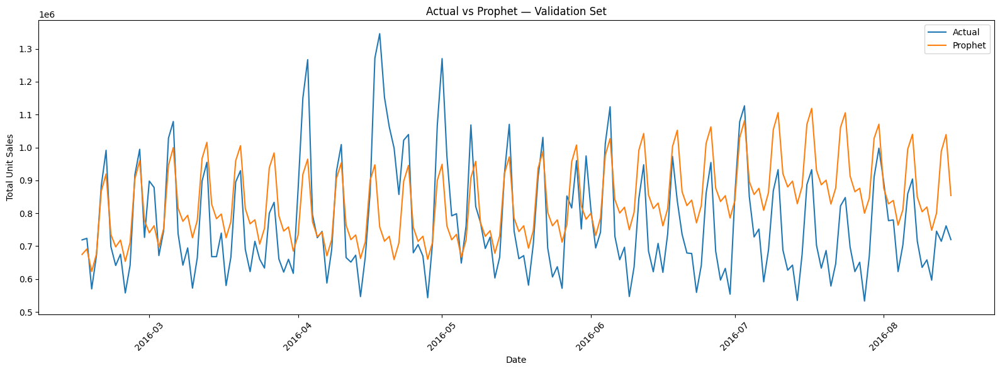

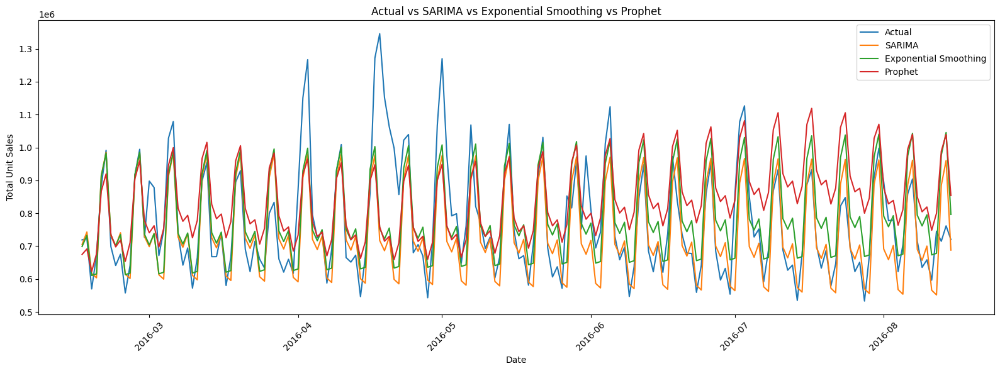

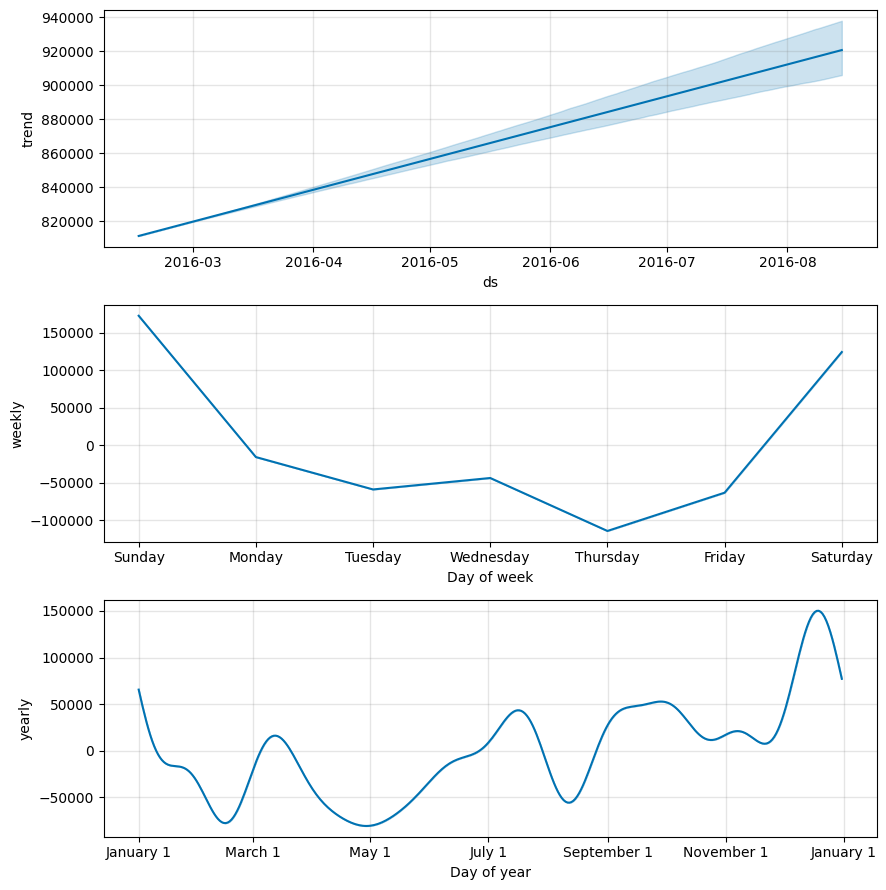


Saved:
/kaggle/working/prophet_results.csv
/kaggle/working/prophet_validation_predictions.csv


In [85]:
# ============================================================
# STEP 23 — PROPHET FORECASTING MODEL
# ============================================================

from prophet import Prophet
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")


# ============================================================
# 1. PREPARE DATA FOR PROPHET
# ============================================================

prophet_train = (
    train_ts
    .reset_index()
    .rename(
        columns={
            "date": "ds",
            "total_sales": "y"
        }
    )
)

print("=" * 70)
print("PROPHET TRAINING DATA")
print("=" * 70)

print("Shape:", prophet_train.shape)

display(prophet_train.head())


# ============================================================
# 2. CREATE PROPHET MODEL
# ============================================================

print("\n" + "=" * 70)
print("TRAINING PROPHET")
print("=" * 70)

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    changepoint_prior_scale=0.05
)


# ============================================================
# 3. TRAIN MODEL
# ============================================================

prophet_model.fit(prophet_train)


# ============================================================
# 4. CREATE FUTURE DATES
# ============================================================

future = prophet_model.make_future_dataframe(
    periods=len(validation_ts),
    freq="D",
    include_history=False
)

print("\nFuture dates:")
display(future.head())
display(future.tail())


# ============================================================
# 5. GENERATE FORECAST
# ============================================================

prophet_forecast = prophet_model.predict(
    future
)


# ============================================================
# 6. EXTRACT PREDICTIONS
# ============================================================

prophet_predictions = (
    prophet_forecast["yhat"]
    .copy()
)

prophet_predictions.index = validation_ts.index


# ============================================================
# 7. EVALUATE PROPHET
# ============================================================

prophet_metrics = calculate_metrics(
    validation_ts,
    prophet_predictions,
    "Prophet"
)

prophet_results = pd.DataFrame([
    prophet_metrics
])


print("\n" + "=" * 70)
print("PROPHET RESULTS — VALIDATION SET")
print("=" * 70)

display(
    prophet_results.round(3)
)


# ============================================================
# 8. CURRENT MODEL COMPARISON
# ============================================================

all_model_results = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results,
        exp_results,
        prophet_results
    ],
    ignore_index=True
)

print("\n" + "=" * 70)
print("CURRENT MODEL COMPARISON")
print("=" * 70)

display(
    all_model_results.round(3)
)


# ============================================================
# 9. ACTUAL VS PROPHET
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    prophet_predictions.index,
    prophet_predictions.values,
    label="Prophet"
)

plt.title(
    "Actual vs Prophet — Validation Set"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 10. ACTUAL VS ALL MAIN MODELS
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions.values,
    label="SARIMA"
)

plt.plot(
    exp_predictions.index,
    exp_predictions.values,
    label="Exponential Smoothing"
)

plt.plot(
    prophet_predictions.index,
    prophet_predictions.values,
    label="Prophet"
)

plt.title(
    "Actual vs SARIMA vs Exponential Smoothing vs Prophet"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 11. PROPHET FORECAST COMPONENTS
# ============================================================

fig1 = prophet_model.plot_components(
    prophet_model.predict(future)
)

plt.show()


# ============================================================
# 12. SAVE RESULTS
# ============================================================

prophet_results.to_csv(
    "/kaggle/working/prophet_results.csv",
    index=False
)

prophet_predictions.to_csv(
    "/kaggle/working/prophet_validation_predictions.csv",
    header=["prediction"]
)

print("\nSaved:")
print("/kaggle/working/prophet_results.csv")
print("/kaggle/working/prophet_validation_predictions.csv")

LSTM DATA PREPARATION
Training observations: 1141
Lookback: 30
X_train shape: (1111, 30, 1)
y_train shape: (1111,)

BUILDING LSTM MODEL


2026-09-17 10:25:17.306545: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)


TRAINING LSTM
Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 0.0355 - val_loss: 0.0274
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0186 - val_loss: 0.0306
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0172 - val_loss: 0.0294
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0171 - val_loss: 0.0305
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0162 - val_loss: 0.0295
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0151 - val_loss: 0.0285
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0149 - val_loss: 0.0281
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0154 - val_loss: 0.0279
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0146 - val_loss: 0.0280


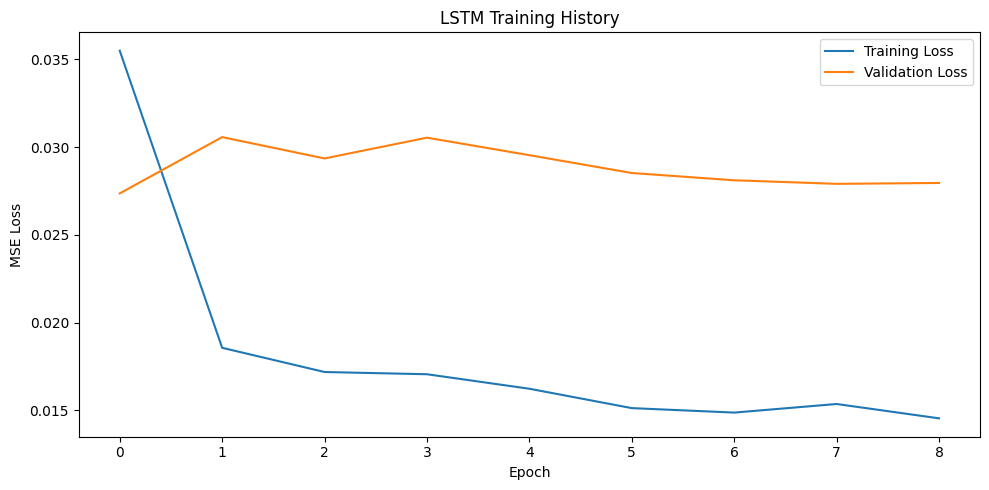


LSTM RESULTS — VALIDATION SET


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,LSTM,154280.955,177664.195,21.172,59.669,0



ALL MODEL COMPARISON


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Naive,130410.733,168915.085,16.084,60.773,0
1,Seasonal Naive (7-day),116352.289,165783.896,14.426,80.663,0
2,"ARIMA(2,1,2)",132584.086,166812.358,16.677,60.773,0
3,"SARIMA(1,1,1)(1,0,1,7)",81682.163,122035.230,9.834,82.873,0
4,Exponential Smoothing,88279.886,119269.202,11.178,80.110,0
5,Prophet,124194.632,152769.648,16.662,76.243,0
6,LSTM,154280.955,177664.195,21.172,59.669,0



MODELS SORTED BY MAE


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,"SARIMA(1,1,1)(1,0,1,7)",81682.163,122035.230,9.834,82.873,0
1,Exponential Smoothing,88279.886,119269.202,11.178,80.110,0
2,Seasonal Naive (7-day),116352.289,165783.896,14.426,80.663,0
3,Prophet,124194.632,152769.648,16.662,76.243,0
4,Naive,130410.733,168915.085,16.084,60.773,0
5,"ARIMA(2,1,2)",132584.086,166812.358,16.677,60.773,0
6,LSTM,154280.955,177664.195,21.172,59.669,0


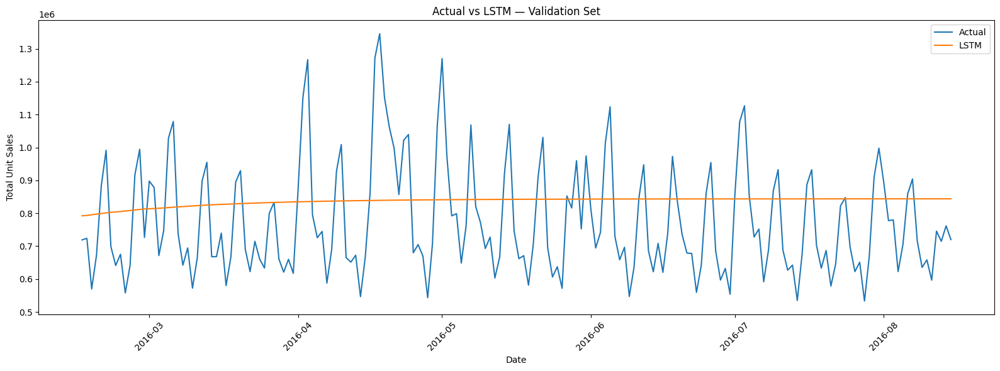

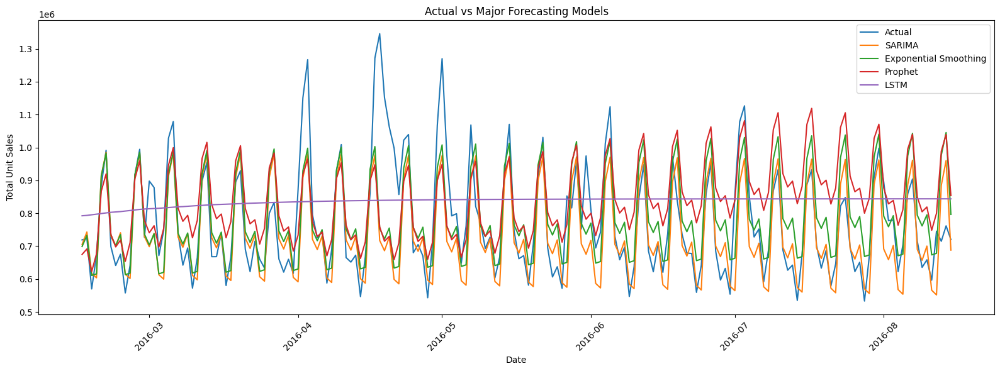


Saved:
/kaggle/working/lstm_results.csv
/kaggle/working/lstm_validation_predictions.csv
/kaggle/working/lstm_demand_model.keras


In [86]:
# ============================================================
# STEP 24 — LSTM FORECASTING MODEL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")


# ============================================================
# 1. PREPARE TRAINING DATA
# ============================================================

train_values = train_ts.values.reshape(-1, 1)

print("=" * 70)
print("LSTM DATA PREPARATION")
print("=" * 70)

print("Training observations:", len(train_values))


# ============================================================
# 2. SCALE TRAINING DATA
# ============================================================

scaler = MinMaxScaler(
    feature_range=(0, 1)
)

train_scaled = scaler.fit_transform(
    train_values
)


# ============================================================
# 3. CREATE SEQUENCES
# ============================================================

lookback = 30

X_train = []
y_train = []

for i in range(
    lookback,
    len(train_scaled)
):
    
    X_train.append(
        train_scaled[
            i - lookback:i,
            0
        ]
    )
    
    y_train.append(
        train_scaled[i, 0]
    )

X_train = np.array(X_train)
y_train = np.array(y_train)


# LSTM expects:
# samples × time_steps × features

X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

print("Lookback:", lookback)
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)


# ============================================================
# 4. BUILD LSTM MODEL
# ============================================================

print("\n" + "=" * 70)
print("BUILDING LSTM MODEL")
print("=" * 70)

lstm_model = Sequential([
    
    LSTM(
        64,
        return_sequences=True,
        input_shape=(lookback, 1)
    ),
    
    Dropout(0.2),
    
    LSTM(
        32,
        return_sequences=False
    ),
    
    Dropout(0.2),
    
    Dense(16, activation="relu"),
    
    Dense(1)
])


lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

lstm_model.summary()


# ============================================================
# 5. TRAIN LSTM
# ============================================================

print("\n" + "=" * 70)
print("TRAINING LSTM")
print("=" * 70)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)


# ============================================================
# 6. PLOT TRAINING HISTORY
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 7. RECURSIVE FORECASTING
# ============================================================

# Start with the final 30 training observations
# and recursively predict the validation period.

last_sequence = train_scaled[
    -lookback:
].flatten().tolist()

lstm_predictions_scaled = []

for _ in range(len(validation_ts)):
    
    input_sequence = np.array(
        last_sequence[-lookback:]
    )
    
    input_sequence = input_sequence.reshape(
        1,
        lookback,
        1
    )
    
    next_prediction = (
        lstm_model
        .predict(
            input_sequence,
            verbose=0
        )[0, 0]
    )
    
    lstm_predictions_scaled.append(
        next_prediction
    )
    
    # Add prediction to sequence
    last_sequence.append(
        next_prediction
    )


# ============================================================
# 8. CONVERT BACK TO ORIGINAL SCALE
# ============================================================

lstm_predictions = scaler.inverse_transform(
    np.array(
        lstm_predictions_scaled
    ).reshape(-1, 1)
).flatten()

lstm_predictions = pd.Series(
    lstm_predictions,
    index=validation_ts.index
)


# ============================================================
# 9. EVALUATE LSTM
# ============================================================

lstm_metrics = calculate_metrics(
    validation_ts,
    lstm_predictions,
    "LSTM"
)

lstm_results = pd.DataFrame([
    lstm_metrics
])


print("\n" + "=" * 70)
print("LSTM RESULTS — VALIDATION SET")
print("=" * 70)

display(
    lstm_results.round(3)
)


# ============================================================
# 10. FINAL MODEL COMPARISON
# ============================================================

all_model_results = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results,
        exp_results,
        prophet_results,
        lstm_results
    ],
    ignore_index=True
)

print("\n" + "=" * 70)
print("ALL MODEL COMPARISON")
print("=" * 70)

display(
    all_model_results.round(3)
)


# ============================================================
# 11. SORT BY MAE
# ============================================================

print("\n" + "=" * 70)
print("MODELS SORTED BY MAE")
print("=" * 70)

display(
    all_model_results
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(3)
)


# ============================================================
# 12. ACTUAL VS LSTM
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    lstm_predictions.index,
    lstm_predictions.values,
    label="LSTM"
)

plt.title(
    "Actual vs LSTM — Validation Set"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 13. ACTUAL VS ALL MAJOR MODELS
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions.values,
    label="SARIMA"
)

plt.plot(
    exp_predictions.index,
    exp_predictions.values,
    label="Exponential Smoothing"
)

plt.plot(
    prophet_predictions.index,
    prophet_predictions.values,
    label="Prophet"
)

plt.plot(
    lstm_predictions.index,
    lstm_predictions.values,
    label="LSTM"
)

plt.title(
    "Actual vs Major Forecasting Models"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 14. SAVE RESULTS
# ============================================================

lstm_results.to_csv(
    "/kaggle/working/lstm_results.csv",
    index=False
)

lstm_predictions.to_csv(
    "/kaggle/working/lstm_validation_predictions.csv",
    header=["prediction"]
)

lstm_model.save(
    "/kaggle/working/lstm_demand_model.keras"
)

print("\nSaved:")
print("/kaggle/working/lstm_results.csv")
print("/kaggle/working/lstm_validation_predictions.csv")
print("/kaggle/working/lstm_demand_model.keras")

SARIMA HYPERPARAMETER TUNING
Total combinations: 36
[1/36] SARIMA(0, 1, 0)x(0, 0, 0, 7)
[2/36] SARIMA(0, 1, 0)x(0, 0, 1, 7)
[3/36] SARIMA(0, 1, 0)x(1, 0, 0, 7)
[4/36] SARIMA(0, 1, 0)x(1, 0, 1, 7)
[5/36] SARIMA(0, 1, 1)x(0, 0, 0, 7)
[6/36] SARIMA(0, 1, 1)x(0, 0, 1, 7)
[7/36] SARIMA(0, 1, 1)x(1, 0, 0, 7)
[8/36] SARIMA(0, 1, 1)x(1, 0, 1, 7)
[9/36] SARIMA(0, 1, 2)x(0, 0, 0, 7)
[10/36] SARIMA(0, 1, 2)x(0, 0, 1, 7)
[11/36] SARIMA(0, 1, 2)x(1, 0, 0, 7)
[12/36] SARIMA(0, 1, 2)x(1, 0, 1, 7)
[13/36] SARIMA(1, 1, 0)x(0, 0, 0, 7)
[14/36] SARIMA(1, 1, 0)x(0, 0, 1, 7)
[15/36] SARIMA(1, 1, 0)x(1, 0, 0, 7)
[16/36] SARIMA(1, 1, 0)x(1, 0, 1, 7)
[17/36] SARIMA(1, 1, 1)x(0, 0, 0, 7)
[18/36] SARIMA(1, 1, 1)x(0, 0, 1, 7)
[19/36] SARIMA(1, 1, 1)x(1, 0, 0, 7)
[20/36] SARIMA(1, 1, 1)x(1, 0, 1, 7)
[21/36] SARIMA(1, 1, 2)x(0, 0, 0, 7)
[22/36] SARIMA(1, 1, 2)x(0, 0, 1, 7)
[23/36] SARIMA(1, 1, 2)x(1, 0, 0, 7)
[24/36] SARIMA(1, 1, 2)x(1, 0, 1, 7)
[25/36] SARIMA(2, 1, 0)x(0, 0, 0, 7)
[26/36] SARIMA(2, 1, 0)x(0, 0, 1

,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),AIC,Order,Seasonal Order
0,"SARIMA(2, 1, 2)x(1, 0, 1, 7)",81434.785,121683.450,9.800,82.873,29150.447,"(2, 1, 2)","(1, 0, 1, 7)"
1,"SARIMA(1, 1, 1)x(1, 0, 1, 7)",81682.163,122035.230,9.834,82.873,29460.581,"(1, 1, 1)","(1, 0, 1, 7)"
2,"SARIMA(0, 1, 2)x(1, 0, 1, 7)",81728.617,122411.109,9.828,82.873,29211.825,"(0, 1, 2)","(1, 0, 1, 7)"
3,"SARIMA(2, 1, 1)x(1, 0, 1, 7)",81775.657,122196.504,9.845,82.873,29389.131,"(2, 1, 1)","(1, 0, 1, 7)"
4,"SARIMA(1, 1, 2)x(1, 0, 1, 7)",82132.238,123104.817,9.876,81.768,29195.670,"(1, 1, 2)","(1, 0, 1, 7)"
5,"SARIMA(0, 1, 0)x(1, 0, 1, 7)",83859.706,117124.531,10.407,81.768,29447.784,"(0, 1, 0)","(1, 0, 1, 7)"
6,"SARIMA(0, 1, 1)x(1, 0, 1, 7)",84074.183,127584.973,10.043,80.110,29487.530,"(0, 1, 1)","(1, 0, 1, 7)"
7,"SARIMA(1, 1, 0)x(1, 0, 1, 7)",86203.397,129975.869,10.299,78.453,29589.597,"(1, 1, 0)","(1, 0, 1, 7)"
8,"SARIMA(2, 1, 0)x(1, 0, 1, 7)",103820.743,147579.247,12.473,74.033,29437.744,"(2, 1, 0)","(1, 0, 1, 7)"
9,"SARIMA(0, 1, 0)x(0, 0, 0, 7)",130410.733,168915.085,16.084,60.773,30437.894,"(0, 1, 0)","(0, 0, 0, 7)"



SARIMA MODELS SORTED BY RMSE


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),AIC,Order,Seasonal Order
0,"SARIMA(0, 1, 0)x(1, 0, 1, 7)",83859.706,117124.531,10.407,81.768,29447.784,"(0, 1, 0)","(1, 0, 1, 7)"
1,"SARIMA(2, 1, 2)x(1, 0, 1, 7)",81434.785,121683.450,9.800,82.873,29150.447,"(2, 1, 2)","(1, 0, 1, 7)"
2,"SARIMA(1, 1, 1)x(1, 0, 1, 7)",81682.163,122035.230,9.834,82.873,29460.581,"(1, 1, 1)","(1, 0, 1, 7)"
3,"SARIMA(2, 1, 1)x(1, 0, 1, 7)",81775.657,122196.504,9.845,82.873,29389.131,"(2, 1, 1)","(1, 0, 1, 7)"
4,"SARIMA(0, 1, 2)x(1, 0, 1, 7)",81728.617,122411.109,9.828,82.873,29211.825,"(0, 1, 2)","(1, 0, 1, 7)"
5,"SARIMA(1, 1, 2)x(1, 0, 1, 7)",82132.238,123104.817,9.876,81.768,29195.670,"(1, 1, 2)","(1, 0, 1, 7)"
6,"SARIMA(0, 1, 1)x(1, 0, 1, 7)",84074.183,127584.973,10.043,80.110,29487.530,"(0, 1, 1)","(1, 0, 1, 7)"
7,"SARIMA(1, 1, 0)x(1, 0, 1, 7)",86203.397,129975.869,10.299,78.453,29589.597,"(1, 1, 0)","(1, 0, 1, 7)"
8,"SARIMA(2, 1, 0)x(1, 0, 1, 7)",103820.743,147579.247,12.473,74.033,29437.744,"(2, 1, 0)","(1, 0, 1, 7)"
9,"SARIMA(1, 1, 2)x(1, 0, 0, 7)",133796.974,161879.333,17.446,62.431,29323.262,"(1, 1, 2)","(1, 0, 0, 7)"



SARIMA MODELS SORTED BY MAPE


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),AIC,Order,Seasonal Order
0,"SARIMA(2, 1, 2)x(1, 0, 1, 7)",81434.785,121683.450,9.800,82.873,29150.447,"(2, 1, 2)","(1, 0, 1, 7)"
1,"SARIMA(0, 1, 2)x(1, 0, 1, 7)",81728.617,122411.109,9.828,82.873,29211.825,"(0, 1, 2)","(1, 0, 1, 7)"
2,"SARIMA(1, 1, 1)x(1, 0, 1, 7)",81682.163,122035.230,9.834,82.873,29460.581,"(1, 1, 1)","(1, 0, 1, 7)"
3,"SARIMA(2, 1, 1)x(1, 0, 1, 7)",81775.657,122196.504,9.845,82.873,29389.131,"(2, 1, 1)","(1, 0, 1, 7)"
4,"SARIMA(1, 1, 2)x(1, 0, 1, 7)",82132.238,123104.817,9.876,81.768,29195.670,"(1, 1, 2)","(1, 0, 1, 7)"
5,"SARIMA(0, 1, 1)x(1, 0, 1, 7)",84074.183,127584.973,10.043,80.110,29487.530,"(0, 1, 1)","(1, 0, 1, 7)"
6,"SARIMA(1, 1, 0)x(1, 0, 1, 7)",86203.397,129975.869,10.299,78.453,29589.597,"(1, 1, 0)","(1, 0, 1, 7)"
7,"SARIMA(0, 1, 0)x(1, 0, 1, 7)",83859.706,117124.531,10.407,81.768,29447.784,"(0, 1, 0)","(1, 0, 1, 7)"
8,"SARIMA(2, 1, 0)x(1, 0, 1, 7)",103820.743,147579.247,12.473,74.033,29437.744,"(2, 1, 0)","(1, 0, 1, 7)"
9,"SARIMA(0, 1, 0)x(0, 0, 0, 7)",130410.733,168915.085,16.084,60.773,30437.894,"(0, 1, 0)","(0, 0, 0, 7)"



BEST SARIMA MODEL
Order: (2, 1, 2)
Seasonal Order: (1, 0, 1, 7)
MAE: 81434.785
RMSE: 121683.45
MAPE: 9.8

TUNED SARIMA VALIDATION RESULTS


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Tuned SARIMA,81434.785,121683.45,9.8,82.873,0



TUNING IMPROVEMENT
Original SARIMA MAE: 81682.163
Tuned SARIMA MAE: 81434.785
MAE improvement (%): 0.3


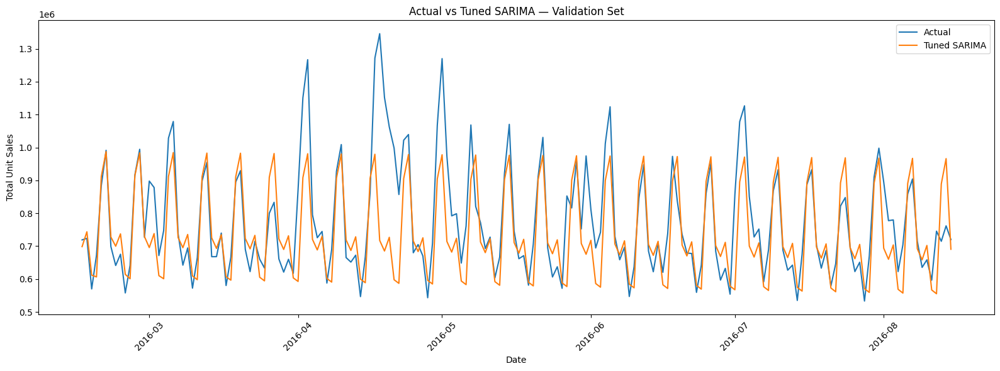


Saved:
/kaggle/working/sarima_tuning_results.csv
/kaggle/working/tuned_sarima_validation_predictions.csv


In [87]:
# ============================================================
# STEP 25 — SARIMA HYPERPARAMETER TUNING
# ============================================================

import itertools
import warnings
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")


# ============================================================
# 1. DEFINE SARIMA PARAMETER GRID
# ============================================================

# Non-seasonal parameters
p_values = [0, 1, 2]
d_values = [1]
q_values = [0, 1, 2]

# Seasonal parameters
P_values = [0, 1]
D_values = [0]
Q_values = [0, 1]

seasonal_period = 7


# ============================================================
# 2. GENERATE PARAMETER COMBINATIONS
# ============================================================

parameter_combinations = list(
    itertools.product(
        p_values,
        d_values,
        q_values,
        P_values,
        D_values,
        Q_values
    )
)

print("=" * 70)
print("SARIMA HYPERPARAMETER TUNING")
print("=" * 70)

print(
    "Total combinations:",
    len(parameter_combinations)
)


# ============================================================
# 3. GRID SEARCH
# ============================================================

tuning_results = []

for i, params in enumerate(parameter_combinations, start=1):

    p, d, q, P, D, Q = params

    order = (p, d, q)

    seasonal_order = (
        P,
        D,
        Q,
        seasonal_period
    )

    print(
        f"[{i}/{len(parameter_combinations)}] "
        f"SARIMA{order}x{seasonal_order}"
    )

    try:

        model = SARIMAX(
            train_ts,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        result = model.fit(
            disp=False
        )

        predictions = result.forecast(
            steps=len(validation_ts)
        )

        predictions.index = validation_ts.index

        metrics = calculate_metrics(
            validation_ts,
            predictions,
            f"SARIMA{order}x{seasonal_order}"
        )

        metrics["AIC"] = result.aic
        metrics["Order"] = str(order)
        metrics["Seasonal Order"] = str(
            seasonal_order
        )

        tuning_results.append(metrics)

    except Exception as e:

        print(
            "   Failed:",
            str(e)[:100]
        )


# ============================================================
# 4. CREATE RESULTS TABLE
# ============================================================

tuning_results_df = pd.DataFrame(
    tuning_results
)


# ============================================================
# 5. SORT BY MAE
# ============================================================

tuning_results_by_mae = (
    tuning_results_df
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("SARIMA MODELS SORTED BY MAE")
print("=" * 70)

display(
    tuning_results_by_mae[
        [
            "Model",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)",
            "AIC",
            "Order",
            "Seasonal Order"
        ]
    ].round(3)
)


# ============================================================
# 6. SORT BY RMSE
# ============================================================

print("\n" + "=" * 70)
print("SARIMA MODELS SORTED BY RMSE")
print("=" * 70)

display(
    tuning_results_df
    .sort_values("RMSE")
    .reset_index(drop=True)[
        [
            "Model",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)",
            "AIC",
            "Order",
            "Seasonal Order"
        ]
    ].round(3)
)


# ============================================================
# 7. SORT BY MAPE
# ============================================================

print("\n" + "=" * 70)
print("SARIMA MODELS SORTED BY MAPE")
print("=" * 70)

display(
    tuning_results_df
    .sort_values("MAPE (%)")
    .reset_index(drop=True)[
        [
            "Model",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)",
            "AIC",
            "Order",
            "Seasonal Order"
        ]
    ].round(3)
)


# ============================================================
# 8. SELECT BEST MODEL BY MAE
# ============================================================

best_sarima_row = (
    tuning_results_by_mae.iloc[0]
)

best_order = eval(
    best_sarima_row["Order"]
)

best_seasonal_order = eval(
    best_sarima_row["Seasonal Order"]
)

print("\n" + "=" * 70)
print("BEST SARIMA MODEL")
print("=" * 70)

print(
    "Order:",
    best_order
)

print(
    "Seasonal Order:",
    best_seasonal_order
)

print(
    "MAE:",
    round(best_sarima_row["MAE"], 3)
)

print(
    "RMSE:",
    round(best_sarima_row["RMSE"], 3)
)

print(
    "MAPE:",
    round(best_sarima_row["MAPE (%)"], 3)
)


# ============================================================
# 9. TRAIN THE BEST MODEL AGAIN
# ============================================================

best_sarima_model = SARIMAX(
    train_ts,
    order=best_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

best_sarima_result = (
    best_sarima_model.fit(
        disp=False
    )
)


# ============================================================
# 10. GENERATE BEST MODEL VALIDATION FORECAST
# ============================================================

best_sarima_predictions = (
    best_sarima_result
    .forecast(
        steps=len(validation_ts)
    )
)

best_sarima_predictions.index = (
    validation_ts.index
)


# ============================================================
# 11. FINAL TUNED MODEL METRICS
# ============================================================

best_sarima_metrics = calculate_metrics(
    validation_ts,
    best_sarima_predictions,
    "Tuned SARIMA"
)

best_sarima_metrics_df = pd.DataFrame([
    best_sarima_metrics
])

print("\n" + "=" * 70)
print("TUNED SARIMA VALIDATION RESULTS")
print("=" * 70)

display(
    best_sarima_metrics_df.round(3)
)


# ============================================================
# 12. ORIGINAL vs TUNED SARIMA
# ============================================================

original_sarima_mae = (
    sarima_results["MAE"].iloc[0]
)

tuned_sarima_mae = (
    best_sarima_metrics_df["MAE"].iloc[0]
)

improvement = (
    (original_sarima_mae - tuned_sarima_mae)
    / original_sarima_mae
) * 100

print("\n" + "=" * 70)
print("TUNING IMPROVEMENT")
print("=" * 70)

print(
    "Original SARIMA MAE:",
    round(original_sarima_mae, 3)
)

print(
    "Tuned SARIMA MAE:",
    round(tuned_sarima_mae, 3)
)

print(
    "MAE improvement (%):",
    round(improvement, 2)
)


# ============================================================
# 13. PLOT TUNED SARIMA
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    best_sarima_predictions.index,
    best_sarima_predictions.values,
    label="Tuned SARIMA"
)

plt.title(
    "Actual vs Tuned SARIMA — Validation Set"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 14. SAVE TUNING RESULTS
# ============================================================

tuning_results_df.to_csv(
    "/kaggle/working/sarima_tuning_results.csv",
    index=False
)

best_sarima_predictions.to_csv(
    "/kaggle/working/tuned_sarima_validation_predictions.csv",
    header=["prediction"]
)

print("\nSaved:")
print("/kaggle/working/sarima_tuning_results.csv")
print(
    "/kaggle/working/"
    "tuned_sarima_validation_predictions.csv"
)

BACKTEST FOLD 1
Training:
2013-01-01 00:00:00 to 2014-12-31 00:00:00
Forecast:
2015-01-01 00:00:00 to 2015-03-31 00:00:00
Training observations: 730
Forecast observations: 90
BACKTEST FOLD 2
Training:
2013-01-01 00:00:00 to 2015-03-31 00:00:00
Forecast:
2015-04-01 00:00:00 to 2015-06-29 00:00:00
Training observations: 820
Forecast observations: 90
BACKTEST FOLD 3
Training:
2013-01-01 00:00:00 to 2015-06-29 00:00:00
Forecast:
2015-06-30 00:00:00 to 2015-09-27 00:00:00
Training observations: 910
Forecast observations: 90
BACKTEST FOLD 4
Training:
2013-01-01 00:00:00 to 2015-09-27 00:00:00
Forecast:
2015-09-28 00:00:00 to 2015-12-26 00:00:00
Training observations: 1000
Forecast observations: 90

BACKTEST RESULTS BY FOLD


,Fold,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%)
0,1,SARIMA Fold 1,394733.989,407198.568,129.893,50.562
1,1,Seasonal Naive Fold 1,70884.910,108477.250,15.416,73.034
2,2,SARIMA Fold 2,174921.867,219133.275,27.193,65.169
3,2,Seasonal Naive Fold 2,77299.303,104701.929,12.496,78.652
4,3,SARIMA Fold 3,64562.740,82748.088,8.694,86.517
5,3,Seasonal Naive Fold 3,83830.178,115596.834,10.823,88.764
6,4,SARIMA Fold 4,95576.337,146793.442,10.715,77.528
7,4,Seasonal Naive Fold 4,118306.912,174856.887,13.171,77.528



AVERAGE BACKTEST PERFORMANCE


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%)
0,SARIMA Fold 1,394733.989,407198.568,129.893,50.562
1,SARIMA Fold 2,174921.867,219133.275,27.193,65.169
2,SARIMA Fold 3,64562.740,82748.088,8.694,86.517
3,SARIMA Fold 4,95576.337,146793.442,10.715,77.528
4,Seasonal Naive Fold 1,70884.910,108477.250,15.416,73.034
5,Seasonal Naive Fold 2,77299.303,104701.929,12.496,78.652
6,Seasonal Naive Fold 3,83830.178,115596.834,10.823,88.764
7,Seasonal Naive Fold 4,118306.912,174856.887,13.171,77.528



MEDIAN BACKTEST PERFORMANCE


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%)
0,SARIMA Fold 1,394733.989,407198.568,129.893,50.562
1,SARIMA Fold 2,174921.867,219133.275,27.193,65.169
2,SARIMA Fold 3,64562.740,82748.088,8.694,86.517
3,SARIMA Fold 4,95576.337,146793.442,10.715,77.528
4,Seasonal Naive Fold 1,70884.910,108477.250,15.416,73.034
5,Seasonal Naive Fold 2,77299.303,104701.929,12.496,78.652
6,Seasonal Naive Fold 3,83830.178,115596.834,10.823,88.764
7,Seasonal Naive Fold 4,118306.912,174856.887,13.171,77.528


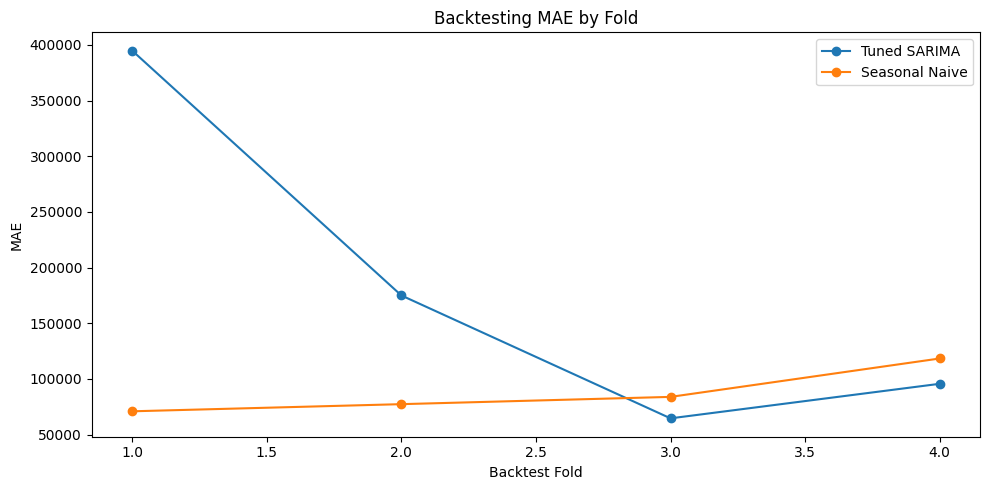

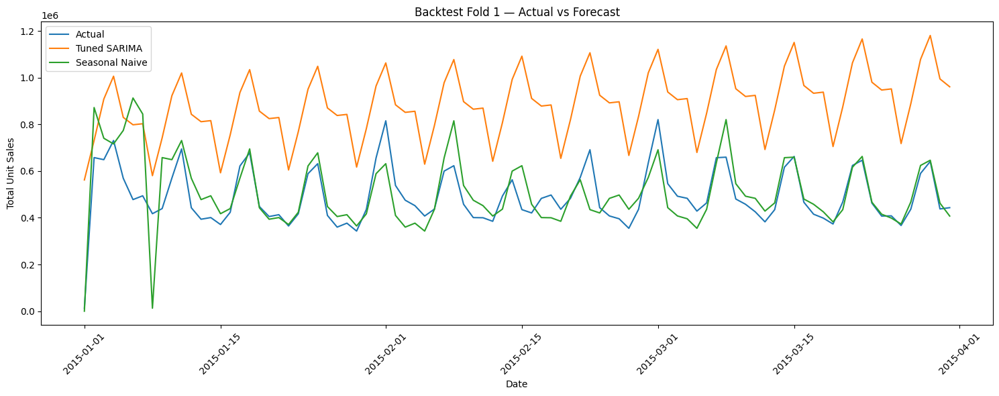


Saved:
/kaggle/working/backtest_results.csv
/kaggle/working/backtest_average_results.csv
/kaggle/working/backtest_predictions.csv


In [88]:
# ============================================================
# STEP 26 — EXPANDING-WINDOW ROLLING BACKTESTING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings

warnings.filterwarnings("ignore")


# ============================================================
# 1. BACKTEST SETTINGS
# ============================================================

BACKTEST_HORIZON = 90
MIN_TRAIN_SIZE = 730
STEP_SIZE = 90

# Tuned model obtained in Step 25
BACKTEST_ORDER = (2, 1, 2)
BACKTEST_SEASONAL_ORDER = (1, 0, 1, 7)


# ============================================================
# 2. STORE RESULTS
# ============================================================

backtest_results = []
backtest_predictions = []


# ============================================================
# 3. CREATE EXPANDING-WINDOW FOLDS
# ============================================================

fold_number = 1
train_size = MIN_TRAIN_SIZE

while train_size + BACKTEST_HORIZON <= len(train_ts):

    fold_train = train_ts.iloc[:train_size]

    fold_actual = train_ts.iloc[
        train_size:
        train_size + BACKTEST_HORIZON
    ]

    print("=" * 70)
    print(f"BACKTEST FOLD {fold_number}")
    print("=" * 70)

    print("Training:")
    print(
        fold_train.index.min(),
        "to",
        fold_train.index.max()
    )

    print("Forecast:")
    print(
        fold_actual.index.min(),
        "to",
        fold_actual.index.max()
    )

    print("Training observations:", len(fold_train))
    print("Forecast observations:", len(fold_actual))


    # --------------------------------------------------------
    # Train SARIMA
    # --------------------------------------------------------

    sarima_model = SARIMAX(
        fold_train,
        order=BACKTEST_ORDER,
        seasonal_order=BACKTEST_SEASONAL_ORDER,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    sarima_result = sarima_model.fit(
        disp=False
    )


    # --------------------------------------------------------
    # Forecast
    # --------------------------------------------------------

    sarima_pred = sarima_result.forecast(
        steps=BACKTEST_HORIZON
    )

    sarima_pred.index = fold_actual.index


    # --------------------------------------------------------
    # Seasonal Naive baseline
    # --------------------------------------------------------

    combined_fold = pd.concat([
        fold_train,
        fold_actual
    ])

    seasonal_naive_pred = (
        combined_fold
        .shift(7)
        .loc[fold_actual.index]
    )


    # --------------------------------------------------------
    # Calculate metrics
    # --------------------------------------------------------

    sarima_metrics = calculate_metrics(
        fold_actual,
        sarima_pred,
        f"SARIMA Fold {fold_number}"
    )

    seasonal_naive_metrics = calculate_metrics(
        fold_actual,
        seasonal_naive_pred,
        f"Seasonal Naive Fold {fold_number}"
    )

    sarima_metrics["Fold"] = fold_number
    seasonal_naive_metrics["Fold"] = fold_number

    sarima_metrics["Forecast Start"] = (
        fold_actual.index.min()
    )

    seasonal_naive_metrics["Forecast Start"] = (
        fold_actual.index.min()
    )


    backtest_results.append(
        sarima_metrics
    )

    backtest_results.append(
        seasonal_naive_metrics
    )


    # --------------------------------------------------------
    # Save predictions
    # --------------------------------------------------------

    fold_predictions = pd.DataFrame({
        "date": fold_actual.index,
        "actual": fold_actual.values,
        "sarima_prediction": sarima_pred.values,
        "seasonal_naive_prediction":
            seasonal_naive_pred.values,
        "fold": fold_number
    })

    backtest_predictions.append(
        fold_predictions
    )


    fold_number += 1
    train_size += STEP_SIZE


# ============================================================
# 4. COMBINE BACKTEST RESULTS
# ============================================================

backtest_results_df = pd.DataFrame(
    backtest_results
)

backtest_predictions_df = pd.concat(
    backtest_predictions,
    ignore_index=True
)


# ============================================================
# 5. DISPLAY FOLD RESULTS
# ============================================================

print("\n" + "=" * 70)
print("BACKTEST RESULTS BY FOLD")
print("=" * 70)

display(
    backtest_results_df[
        [
            "Fold",
            "Model",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ].round(3)
)


# ============================================================
# 6. AVERAGE BACKTEST PERFORMANCE
# ============================================================

average_backtest = (
    backtest_results_df
    .groupby("Model")[
        [
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ]
    .mean()
    .reset_index()
)

print("\n" + "=" * 70)
print("AVERAGE BACKTEST PERFORMANCE")
print("=" * 70)

display(
    average_backtest.round(3)
)


# ============================================================
# 7. MEDIAN BACKTEST PERFORMANCE
# ============================================================

median_backtest = (
    backtest_results_df
    .groupby("Model")[
        [
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ]
    .median()
    .reset_index()
)

print("\n" + "=" * 70)
print("MEDIAN BACKTEST PERFORMANCE")
print("=" * 70)

display(
    median_backtest.round(3)
)


# ============================================================
# 8. PLOT BACKTEST FOLD ERRORS
# ============================================================

sarima_fold_results = (
    backtest_results_df[
        backtest_results_df["Model"].str.startswith("SARIMA")
    ]
    .copy()
)

seasonal_fold_results = (
    backtest_results_df[
        backtest_results_df["Model"].str.startswith("Seasonal Naive")
    ]
    .copy()
)


plt.figure(figsize=(10, 5))

plt.plot(
    sarima_fold_results["Fold"],
    sarima_fold_results["MAE"],
    marker="o",
    label="Tuned SARIMA"
)

plt.plot(
    seasonal_fold_results["Fold"],
    seasonal_fold_results["MAE"],
    marker="o",
    label="Seasonal Naive"
)

plt.title("Backtesting MAE by Fold")
plt.xlabel("Backtest Fold")
plt.ylabel("MAE")

plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 9. PLOT ONE BACKTEST FOLD
# ============================================================

first_fold = (
    backtest_predictions_df[
        backtest_predictions_df["fold"] == 1
    ]
)

plt.figure(figsize=(15, 6))

plt.plot(
    first_fold["date"],
    first_fold["actual"],
    label="Actual"
)

plt.plot(
    first_fold["date"],
    first_fold["sarima_prediction"],
    label="Tuned SARIMA"
)

plt.plot(
    first_fold["date"],
    first_fold["seasonal_naive_prediction"],
    label="Seasonal Naive"
)

plt.title("Backtest Fold 1 — Actual vs Forecast")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 10. SAVE BACKTEST RESULTS
# ============================================================

backtest_results_df.to_csv(
    "/kaggle/working/backtest_results.csv",
    index=False
)

average_backtest.to_csv(
    "/kaggle/working/backtest_average_results.csv",
    index=False
)

backtest_predictions_df.to_csv(
    "/kaggle/working/backtest_predictions.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/backtest_results.csv")
print("/kaggle/working/backtest_average_results.csv")
print("/kaggle/working/backtest_predictions.csv")

In [89]:
# ============================================================
# STEP 26A — CORRECT BACKTEST SUMMARY
# ============================================================

# ------------------------------------------------------------
# 1. Create a clean model category
# ------------------------------------------------------------

backtest_results_df["Model Type"] = (
    backtest_results_df["Model"]
    .str.replace(
        r" Fold \d+",
        "",
        regex=True
    )
)


# ============================================================
# 2. AVERAGE PERFORMANCE ACROSS FOLDS
# ============================================================

correct_average_backtest = (
    backtest_results_df
    .groupby("Model Type")[
        [
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ]
    .agg(["mean", "std"])
    .reset_index()
)

print("=" * 70)
print("CORRECT AVERAGE BACKTEST PERFORMANCE")
print("=" * 70)

display(
    correct_average_backtest.round(3)
)


# ============================================================
# 3. MEDIAN PERFORMANCE ACROSS FOLDS
# ============================================================

correct_median_backtest = (
    backtest_results_df
    .groupby("Model Type")[
        [
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ]
    .median()
    .reset_index()
)

print("\n" + "=" * 70)
print("CORRECT MEDIAN BACKTEST PERFORMANCE")
print("=" * 70)

display(
    correct_median_backtest.round(3)
)


# ============================================================
# 4. PERFORMANCE BY FOLD
# ============================================================

fold_comparison = (
    backtest_results_df[
        [
            "Fold",
            "Model Type",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ]
    .sort_values(
        ["Fold", "Model Type"]
    )
)

print("\n" + "=" * 70)
print("PERFORMANCE BY FOLD")
print("=" * 70)

display(
    fold_comparison.round(3)
)


# ============================================================
# 5. COUNT HOW MANY FOLDS SARIMA BEATS SEASONAL NAIVE
# ============================================================

sarima_fold = (
    backtest_results_df[
        backtest_results_df["Model Type"]
        == "SARIMA"
    ][
        [
            "Fold",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ]
    .set_index("Fold")
)

seasonal_fold = (
    backtest_results_df[
        backtest_results_df["Model Type"]
        == "Seasonal Naive"
    ][
        [
            "Fold",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ]
    .set_index("Fold")
)


sarima_beats_mae = (
    sarima_fold["MAE"]
    < seasonal_fold["MAE"]
)

sarima_beats_rmse = (
    sarima_fold["RMSE"]
    < seasonal_fold["RMSE"]
)

sarima_beats_mape = (
    sarima_fold["MAPE (%)"]
    < seasonal_fold["MAPE (%)"]
)


print("\n" + "=" * 70)
print("SARIMA VS SEASONAL NAIVE — FOLD WIN COUNT")
print("=" * 70)

print(
    "SARIMA better MAE:",
    sarima_beats_mae.sum(),
    "out of",
    len(sarima_beats_mae)
)

print(
    "SARIMA better RMSE:",
    sarima_beats_rmse.sum(),
    "out of",
    len(sarima_beats_rmse)
)

print(
    "SARIMA better MAPE:",
    sarima_beats_mape.sum(),
    "out of",
    len(sarima_beats_mape)
)


# ============================================================
# 6. POOLED BACKTEST METRICS
# ============================================================

pooled_mae = {}
pooled_rmse = {}
pooled_mape = {}
pooled_directional = {}

for model_type in ["SARIMA", "Seasonal Naive"]:

    subset = backtest_predictions_df.copy()

    if model_type == "SARIMA":

        actual = subset["actual"]
        predicted = subset["sarima_prediction"]

    else:

        actual = subset["actual"]
        predicted = subset[
            "seasonal_naive_prediction"
        ]


    actual = pd.Series(actual).reset_index(drop=True)
    predicted = pd.Series(predicted).reset_index(drop=True)


    pooled_mae[model_type] = mean_absolute_error(
        actual,
        predicted
    )

    pooled_rmse[model_type] = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )


    non_zero = actual != 0

    pooled_mape[model_type] = (
        np.mean(
            np.abs(
                (
                    actual[non_zero]
                    - predicted[non_zero]
                )
                / actual[non_zero]
            )
        )
        * 100
    )


    actual_direction = np.sign(
        actual.diff()
    )

    predicted_direction = np.sign(
        predicted - actual.shift(1)
    )

    valid_direction = (
        actual_direction.notna()
        &
        predicted_direction.notna()
    )

    pooled_directional[model_type] = (
        np.mean(
            actual_direction[valid_direction]
            ==
            predicted_direction[valid_direction]
        )
        * 100
    )


pooled_results = pd.DataFrame({
    "Model": [
        "SARIMA",
        "Seasonal Naive"
    ],
    "MAE": [
        pooled_mae["SARIMA"],
        pooled_mae["Seasonal Naive"]
    ],
    "RMSE": [
        pooled_rmse["SARIMA"],
        pooled_rmse["Seasonal Naive"]
    ],
    "MAPE (%)": [
        pooled_mape["SARIMA"],
        pooled_mape["Seasonal Naive"]
    ],
    "Directional Accuracy (%)": [
        pooled_directional["SARIMA"],
        pooled_directional["Seasonal Naive"]
    ]
})


print("\n" + "=" * 70)
print("POOLED BACKTEST PERFORMANCE")
print("=" * 70)

display(
    pooled_results.round(3)
)


# ============================================================
# 7. SAVE CORRECTED RESULTS
# ============================================================

correct_average_backtest.to_csv(
    "/kaggle/working/"
    "correct_average_backtest_results.csv",
    index=False
)

correct_median_backtest.to_csv(
    "/kaggle/working/"
    "correct_median_backtest_results.csv",
    index=False
)

pooled_results.to_csv(
    "/kaggle/working/"
    "pooled_backtest_results.csv",
    index=False
)

print("\nSaved corrected backtest summaries.")

CORRECT AVERAGE BACKTEST PERFORMANCE


Model Type         MAE                    RMSE             MAPE (%)  \
                         mean         std        mean         std     mean   
0          SARIMA  182448.733  148958.165  213968.343  140351.724   44.124   
1  Seasonal Naive   87580.326   21155.165  125908.225   32943.599   12.976   

          Directional Accuracy (%)          
      std                     mean     std  
0  57.777                   69.944  15.606  
1   1.903                   79.494   6.639


CORRECT MEDIAN BACKTEST PERFORMANCE


,Model Type,MAE,RMSE,MAPE (%),Directional Accuracy (%)
0,SARIMA,135249.102,182963.359,18.954,71.348
1,Seasonal Naive,80564.741,112037.042,12.833,78.090



PERFORMANCE BY FOLD


,Fold,Model Type,MAE,RMSE,MAPE (%),Directional Accuracy (%)
0,1,SARIMA,394733.989,407198.568,129.893,50.562
1,1,Seasonal Naive,70884.910,108477.250,15.416,73.034
2,2,SARIMA,174921.867,219133.275,27.193,65.169
3,2,Seasonal Naive,77299.303,104701.929,12.496,78.652
4,3,SARIMA,64562.740,82748.088,8.694,86.517
5,3,Seasonal Naive,83830.178,115596.834,10.823,88.764
6,4,SARIMA,95576.337,146793.442,10.715,77.528
7,4,Seasonal Naive,118306.912,174856.887,13.171,77.528



SARIMA VS SEASONAL NAIVE — FOLD WIN COUNT
SARIMA better MAE: 2 out of 4
SARIMA better RMSE: 2 out of 4
SARIMA better MAPE: 2 out of 4

POOLED BACKTEST PERFORMANCE


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%)
0,SARIMA,182448.733,246082.114,44.217,69.638
1,Seasonal Naive,87580.326,129100.122,12.976,79.387



Saved corrected backtest summaries.


FINAL TEST EVALUATION
Training period:
2013-01-01 00:00:00 to 2016-08-15 00:00:00

Test period:
2016-08-16 00:00:00 to 2017-08-15 00:00:00

Training observations: 1323
Test observations: 365

FINAL TEST RESULTS


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Tuned SARIMA,102726.907,159075.85,31.356,79.945,1
1,Seasonal Naive,107350.712,167139.97,12.055,81.319,1



VALIDATION VS TEST


,Model,Validation MAE,Test MAE,Validation RMSE,Test RMSE,Validation MAPE (%),Test MAPE (%),Validation Direction (%),Test Direction (%)
0,Tuned SARIMA,81434.785,102726.907,121683.450,159075.85,9.800,31.356,82.873,79.945
1,Seasonal Naive,116352.289,107350.712,165783.896,167139.97,14.426,12.055,80.663,81.319


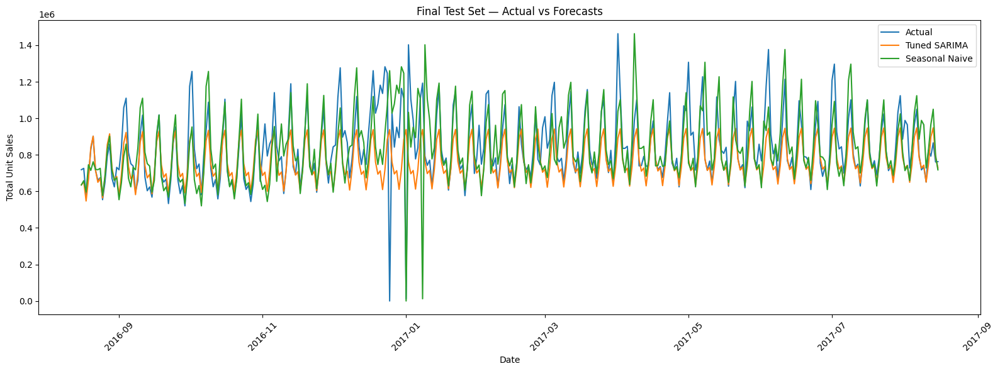


Saved:
/kaggle/working/final_test_results.csv
/kaggle/working/validation_vs_test_comparison.csv
/kaggle/working/final_sarima_test_predictions.csv


In [90]:
# ============================================================
# STEP 27 — FINAL TEST-SET EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX


# ============================================================
# 1. TRAIN TUNED SARIMA ON TRAIN + VALIDATION
# ============================================================

# We have already used validation for model tuning.
# Now combine train + validation to give the selected
# SARIMA model all historical information before the
# untouched test period.

pre_test_series = pd.concat([
    train_ts,
    validation_ts
])

print("=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

print("Training period:")
print(
    pre_test_series.index.min(),
    "to",
    pre_test_series.index.max()
)

print("\nTest period:")
print(
    test_ts.index.min(),
    "to",
    test_ts.index.max()
)

print("\nTraining observations:",
      len(pre_test_series))

print("Test observations:",
      len(test_ts))


# ============================================================
# 2. FIT TUNED SARIMA
# ============================================================

final_test_model = SARIMAX(
    pre_test_series,
    order=(2, 1, 2),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_test_result = final_test_model.fit(
    disp=False
)


# ============================================================
# 3. FORECAST TEST PERIOD
# ============================================================

test_predictions = final_test_result.forecast(
    steps=len(test_ts)
)

test_predictions.index = test_ts.index


# ============================================================
# 4. SEASONAL NAIVE TEST FORECAST
# ============================================================

combined_pretest = pd.concat([
    pre_test_series,
    test_ts
])

seasonal_naive_test_predictions = (
    combined_pretest
    .shift(7)
    .loc[test_ts.index]
)


# ============================================================
# 5. EVALUATE TUNED SARIMA
# ============================================================

final_sarima_test_metrics = calculate_metrics(
    test_ts,
    test_predictions,
    "Tuned SARIMA"
)


# ============================================================
# 6. EVALUATE SEASONAL NAIVE
# ============================================================

final_seasonal_naive_test_metrics = calculate_metrics(
    test_ts,
    seasonal_naive_test_predictions,
    "Seasonal Naive"
)


# ============================================================
# 7. TEST RESULTS TABLE
# ============================================================

final_test_results = pd.DataFrame([
    final_sarima_test_metrics,
    final_seasonal_naive_test_metrics
])


print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

display(
    final_test_results.round(3)
)


# ============================================================
# 8. COMPARE WITH VALIDATION RESULTS
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Tuned SARIMA",
        "Seasonal Naive"
    ],

    "Validation MAE": [
        best_sarima_metrics_df["MAE"].iloc[0],
        baseline_results[
            baseline_results["Model"]
            == "Seasonal Naive (7-day)"
        ]["MAE"].iloc[0]
    ],

    "Test MAE": [
        final_sarima_test_metrics["MAE"],
        final_seasonal_naive_test_metrics["MAE"]
    ],

    "Validation RMSE": [
        best_sarima_metrics_df["RMSE"].iloc[0],
        baseline_results[
            baseline_results["Model"]
            == "Seasonal Naive (7-day)"
        ]["RMSE"].iloc[0]
    ],

    "Test RMSE": [
        final_sarima_test_metrics["RMSE"],
        final_seasonal_naive_test_metrics["RMSE"]
    ],

    "Validation MAPE (%)": [
        best_sarima_metrics_df["MAPE (%)"].iloc[0],
        baseline_results[
            baseline_results["Model"]
            == "Seasonal Naive (7-day)"
        ]["MAPE (%)"].iloc[0]
    ],

    "Test MAPE (%)": [
        final_sarima_test_metrics["MAPE (%)"],
        final_seasonal_naive_test_metrics["MAPE (%)"]
    ],

    "Validation Direction (%)": [
        best_sarima_metrics_df[
            "Directional Accuracy (%)"
        ].iloc[0],

        baseline_results[
            baseline_results["Model"]
            == "Seasonal Naive (7-day)"
        ]["Directional Accuracy (%)"].iloc[0]
    ],

    "Test Direction (%)": [
        final_sarima_test_metrics[
            "Directional Accuracy (%)"
        ],

        final_seasonal_naive_test_metrics[
            "Directional Accuracy (%)"
        ]
    ]
})

print("\n" + "=" * 70)
print("VALIDATION VS TEST")
print("=" * 70)

display(
    comparison.round(3)
)


# ============================================================
# 9. PLOT TEST FORECAST
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    test_ts.index,
    test_ts.values,
    label="Actual"
)

plt.plot(
    test_predictions.index,
    test_predictions.values,
    label="Tuned SARIMA"
)

plt.plot(
    seasonal_naive_test_predictions.index,
    seasonal_naive_test_predictions.values,
    label="Seasonal Naive"
)

plt.title(
    "Final Test Set — Actual vs Forecasts"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 10. SAVE FINAL TEST RESULTS
# ============================================================

final_test_results.to_csv(
    "/kaggle/working/final_test_results.csv",
    index=False
)

comparison.to_csv(
    "/kaggle/working/validation_vs_test_comparison.csv",
    index=False
)

test_predictions.to_csv(
    "/kaggle/working/final_sarima_test_predictions.csv",
    header=["prediction"]
)

print("\nSaved:")
print("/kaggle/working/final_test_results.csv")
print("/kaggle/working/validation_vs_test_comparison.csv")
print("/kaggle/working/final_sarima_test_predictions.csv")

FINAL FORECAST MODEL
Historical start: 2013-01-01 00:00:00
Historical end: 2017-08-15 00:00:00
Historical observations: 1688

FINAL SARIMA MODEL
Order: (2, 1, 2)
Seasonal Order: (1, 0, 1, 7)

Model fitted successfully.

FIRST 10 FORECAST DAYS


,forecast,lower_95,upper_95,inventory_forecast,lower_95_inventory,upper_95_inventory,days_ahead,forecast_month
date,,,,,,,,
2017-08-16,769385.11,513671.08,1025099.14,769385.11,513671.08,1025099.14,1,2017-08
2017-08-17,628086.70,354134.28,902039.12,628086.70,354134.28,902039.12,2,2017-08
2017-08-18,764458.46,484774.22,1044142.71,764458.46,484774.22,1044142.71,3,2017-08
2017-08-19,974133.74,690980.53,1257286.95,974133.74,690980.53,1257286.95,4,2017-08
2017-08-20,1032790.93,746669.39,1318912.47,1032790.93,746669.39,1318912.47,5,2017-08
2017-08-21,776596.24,487672.19,1065520.30,776596.24,487672.19,1065520.30,6,2017-08
2017-08-22,721105.87,429435.66,1012776.08,721105.87,429435.66,1012776.08,7,2017-08
2017-08-23,756315.97,459553.82,1053078.12,756315.97,459553.82,1053078.12,8,2017-08
2017-08-24,622482.19,322243.28,922721.10,622482.19,322243.28,922721.10,9,2017-08



LAST 10 FORECAST DAYS


,forecast,lower_95,upper_95,inventory_forecast,lower_95_inventory,upper_95_inventory,days_ahead,forecast_month
date,,,,,,,,
2018-08-06,652152.15,-1398516.23,2702820.53,652152.15,0.0,2702820.53,356,2018-08
2018-08-07,592304.12,-1464612.46,2649220.70,592304.12,0.0,2649220.70,357,2018-08
2018-08-08,630291.62,-1434163.17,2694746.42,630291.62,0.0,2694746.42,358,2018-08
2018-08-09,485913.25,-1585234.48,2557060.99,485913.25,0.0,2557060.99,359,2018-08
2018-08-10,635608.71,-1442001.02,2713218.43,635608.71,0.0,2713218.43,360,2018-08
2018-08-11,862764.89,-1221226.98,2946756.77,862764.89,0.0,2946756.77,361,2018-08
2018-08-12,926323.87,-1164015.60,3016663.34,926323.87,0.0,3016663.34,362,2018-08
2018-08-13,649566.10,-1447097.04,2746229.24,649566.10,0.0,2746229.24,363,2018-08
2018-08-14,589627.21,-1513339.55,2692593.98,589627.21,0.0,2692593.98,364,2018-08



6-MONTH FORECAST
Start: 2017-08-16 00:00:00
End: 2018-02-13 00:00:00
Average daily forecast: 777744.98
Total forecast demand: 141549586.18

12-MONTH FORECAST
Start: 2017-08-16 00:00:00
End: 2018-08-15 00:00:00
Average daily forecast: 745640.59
Total forecast demand: 272158815.58

MONTHLY FORECAST


,date,forecast_units,average_daily_forecast,lower_95_units,upper_95_units
0,2017-08-31,12675668.25,792229.27,7930273.68,17421062.82
1,2017-09-30,24066524.73,802217.49,12753924.02,35379125.44
2,2017-10-31,24533587.20,791406.04,9306649.79,39760524.61
3,2017-11-30,23084655.47,769488.52,4793799.88,41556141.53
4,2017-12-31,24132437.68,778465.73,2284511.77,47377135.32
5,2018-01-31,23273319.83,750752.25,490135.46,51032403.91
6,2018-02-28,20887412.36,745979.01,0.00,50074817.58
7,2018-03-31,22741790.94,733606.16,0.00,59859106.61
8,2018-04-30,21953498.50,731783.28,0.00,62912341.96
9,2018-05-31,21799756.99,703217.97,0.00,69577434.87


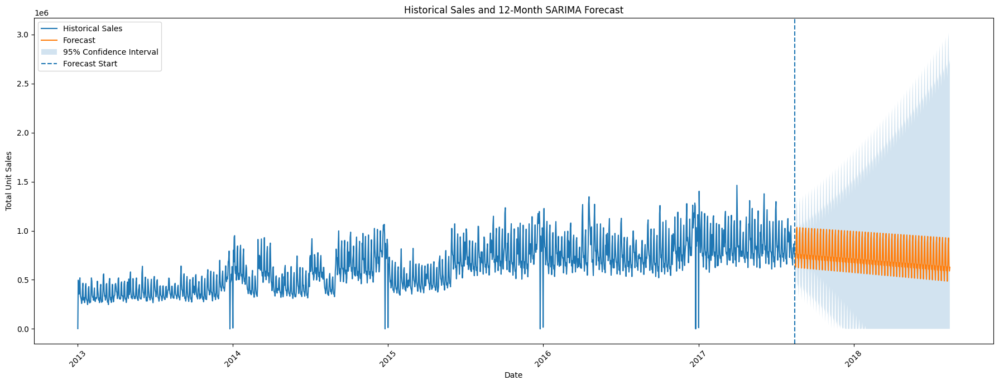

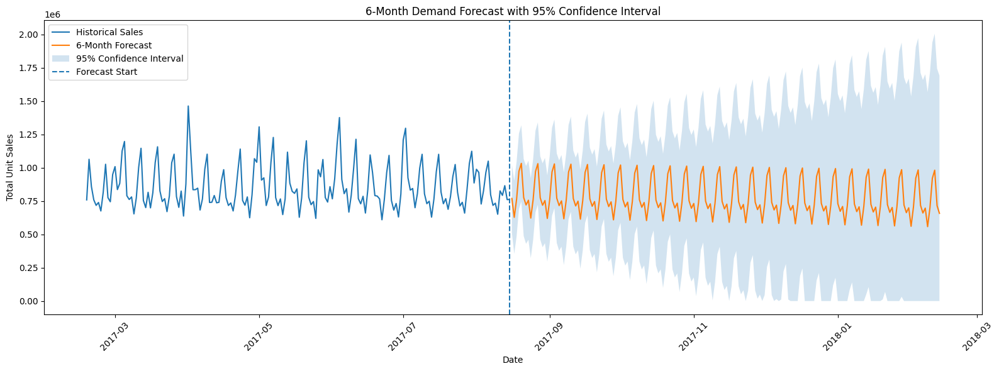

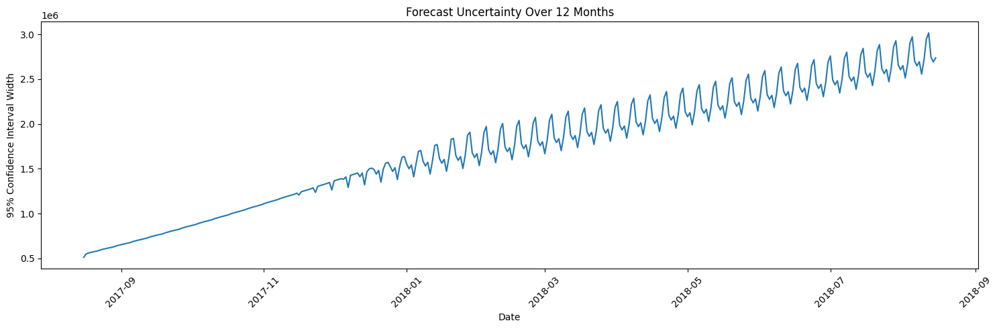


FILES SAVED
/kaggle/working/final_12_month_forecast.csv
/kaggle/working/final_6_month_forecast.csv
/kaggle/working/monthly_forecast_summary.csv


In [91]:
# ============================================================
# STEP 28 — FINAL 6-MONTH AND 12-MONTH FORECAST
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX


# ============================================================
# 1. FINAL HISTORICAL SERIES
# ============================================================

# Use ALL available historical data
# from 2013-01-01 through 2017-08-15.

final_series = (
    forecast_df
    .set_index("date")["total_sales"]
    .sort_index()
    .asfreq("D")
)

print("=" * 70)
print("FINAL FORECAST MODEL")
print("=" * 70)

print("Historical start:",
      final_series.index.min())

print("Historical end:",
      final_series.index.max())

print("Historical observations:",
      len(final_series))


# ============================================================
# 2. TRAIN FINAL TUNED SARIMA
# ============================================================

final_model = SARIMAX(
    final_series,

    order=(2, 1, 2),

    seasonal_order=(1, 0, 1, 7),

    enforce_stationarity=False,

    enforce_invertibility=False
)

final_result = final_model.fit(
    disp=False
)

print("\n" + "=" * 70)
print("FINAL SARIMA MODEL")
print("=" * 70)

print("Order:",
      (2, 1, 2))

print("Seasonal Order:",
      (1, 0, 1, 7))

print("\nModel fitted successfully.")


# ============================================================
# 3. CREATE 12-MONTH FORECAST
# ============================================================

FORECAST_DAYS = 365

final_forecast_result = (
    final_result.get_forecast(
        steps=FORECAST_DAYS
    )
)


# ============================================================
# 4. EXTRACT POINT FORECAST
# ============================================================

forecast_mean = (
    final_forecast_result.predicted_mean
)

forecast_mean.name = "forecast"


# ============================================================
# 5. EXTRACT 95% CONFIDENCE INTERVAL
# ============================================================

confidence_intervals = (
    final_forecast_result
    .conf_int(alpha=0.05)
)

confidence_intervals.columns = [
    "lower_95",
    "upper_95"
]


# ============================================================
# 6. CREATE FINAL FORECAST DATAFRAME
# ============================================================

forecast_output = pd.concat(
    [
        forecast_mean,
        confidence_intervals
    ],
    axis=1
)

forecast_output.index.name = "date"

# Demand cannot be negative from a business perspective.
# Keep the statistical SARIMA forecast unchanged,
# but create an inventory-use forecast clipped at zero.

forecast_output["inventory_forecast"] = (
    forecast_output["forecast"]
    .clip(lower=0)
)

forecast_output["lower_95_inventory"] = (
    forecast_output["lower_95"]
    .clip(lower=0)
)

forecast_output["upper_95_inventory"] = (
    forecast_output["upper_95"]
    .clip(lower=0)
)


# ============================================================
# 7. ADD FORECAST HORIZON
# ============================================================

forecast_output["days_ahead"] = (
    np.arange(1, FORECAST_DAYS + 1)
)

forecast_output["forecast_month"] = (
    forecast_output.index.to_period("M")
    .astype(str)
)


# ============================================================
# 8. DISPLAY FIRST 10 FORECAST DAYS
# ============================================================

print("\n" + "=" * 70)
print("FIRST 10 FORECAST DAYS")
print("=" * 70)

display(
    forecast_output.head(10).round(2)
)


# ============================================================
# 9. DISPLAY LAST 10 FORECAST DAYS
# ============================================================

print("\n" + "=" * 70)
print("LAST 10 FORECAST DAYS")
print("=" * 70)

display(
    forecast_output.tail(10).round(2)
)


# ============================================================
# 10. 6-MONTH FORECAST
# ============================================================

forecast_6m = forecast_output.iloc[:182].copy()

print("\n" + "=" * 70)
print("6-MONTH FORECAST")
print("=" * 70)

print("Start:",
      forecast_6m.index.min())

print("End:",
      forecast_6m.index.max())

print("Average daily forecast:",
      round(
          forecast_6m["inventory_forecast"].mean(),
          2
      ))

print("Total forecast demand:",
      round(
          forecast_6m["inventory_forecast"].sum(),
          2
      ))


# ============================================================
# 11. 12-MONTH FORECAST
# ============================================================

forecast_12m = forecast_output.copy()

print("\n" + "=" * 70)
print("12-MONTH FORECAST")
print("=" * 70)

print("Start:",
      forecast_12m.index.min())

print("End:",
      forecast_12m.index.max())

print("Average daily forecast:",
      round(
          forecast_12m["inventory_forecast"].mean(),
          2
      ))

print("Total forecast demand:",
      round(
          forecast_12m["inventory_forecast"].sum(),
          2
      ))


# ============================================================
# 12. MONTHLY FORECAST SUMMARY
# ============================================================

monthly_forecast = (
    forecast_output
    .resample("ME")
    .agg(
        forecast_units=(
            "inventory_forecast",
            "sum"
        ),
        average_daily_forecast=(
            "inventory_forecast",
            "mean"
        ),
        lower_95_units=(
            "lower_95_inventory",
            "sum"
        ),
        upper_95_units=(
            "upper_95_inventory",
            "sum"
        )
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("MONTHLY FORECAST")
print("=" * 70)

display(
    monthly_forecast.round(2)
)


# ============================================================
# 13. FULL HISTORICAL + FORECAST VISUALIZATION
# ============================================================

plt.figure(figsize=(18, 7))

# Historical
plt.plot(
    final_series.index,
    final_series.values,
    label="Historical Sales"
)

# Forecast
plt.plot(
    forecast_output.index,
    forecast_output["inventory_forecast"],
    label="Forecast"
)

# Confidence interval
plt.fill_between(
    forecast_output.index,
    forecast_output["lower_95_inventory"],
    forecast_output["upper_95_inventory"],
    alpha=0.2,
    label="95% Confidence Interval"
)

# Forecast boundary
plt.axvline(
    final_series.index.max(),
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    "Historical Sales and 12-Month SARIMA Forecast"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 14. 6-MONTH FORECAST VISUALIZATION
# ============================================================

plt.figure(figsize=(16, 6))

# Last 180 historical days
recent_history = final_series.tail(180)

plt.plot(
    recent_history.index,
    recent_history.values,
    label="Historical Sales"
)

plt.plot(
    forecast_6m.index,
    forecast_6m["inventory_forecast"],
    label="6-Month Forecast"
)

plt.fill_between(
    forecast_6m.index,
    forecast_6m["lower_95_inventory"],
    forecast_6m["upper_95_inventory"],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.axvline(
    final_series.index.max(),
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    "6-Month Demand Forecast with 95% Confidence Interval"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 15. FORECAST UNCERTAINTY
# ============================================================

forecast_output["interval_width"] = (
    forecast_output["upper_95_inventory"]
    -
    forecast_output["lower_95_inventory"]
)

plt.figure(figsize=(15, 5))

plt.plot(
    forecast_output.index,
    forecast_output["interval_width"]
)

plt.title(
    "Forecast Uncertainty Over 12 Months"
)

plt.xlabel("Date")
plt.ylabel("95% Confidence Interval Width")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 16. SAVE FORECAST RESULTS
# ============================================================

forecast_output.to_csv(
    "/kaggle/working/final_12_month_forecast.csv"
)

forecast_6m.to_csv(
    "/kaggle/working/final_6_month_forecast.csv"
)

monthly_forecast.to_csv(
    "/kaggle/working/monthly_forecast_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print(
    "/kaggle/working/final_12_month_forecast.csv"
)

print(
    "/kaggle/working/final_6_month_forecast.csv"
)

print(
    "/kaggle/working/monthly_forecast_summary.csv"
)

INVENTORY PLANNING — AGGREGATE DEMAND


,Planning Horizon,Days,Expected Demand,Lower Demand Bound,Upper Demand Bound,Safety Buffer,Recommended Planning Stock
0,7_days,7,5666557.06,3707337.35,7625776.77,1959219.71,7625776.77
1,14_days,14,11301930.85,7200075.45,15403786.25,4101855.40,15403786.25
2,30_days,30,23886813.40,14261483.17,33512143.63,9625330.23,33512143.63



TOP 3 HIGH-DEMAND FORECAST MONTHS


,date,forecast_units,average_daily_forecast,forecast_share
2,2017-10-31,24533587.20,791406.04,9.01
4,2017-12-31,24132437.68,778465.73,8.87
1,2017-09-30,24066524.73,802217.49,8.84



BOTTOM 3 FORECAST MONTHS


,date,forecast_units,average_daily_forecast,forecast_share
12,2018-08-31,10205612.67,680374.18,3.75
0,2017-08-31,12675668.25,792229.27,4.66
6,2018-02-28,20887412.36,745979.01,7.67



6-MONTH VS 12-MONTH DEMAND SUMMARY


,Period,Total Expected Demand,Average Daily Demand,Minimum Daily Forecast,Maximum Daily Forecast
0,6 Months,1.415496e+08,777744.98,558220.89,1032790.93
1,12 Months,2.721588e+08,745640.59,485913.25,1032790.93


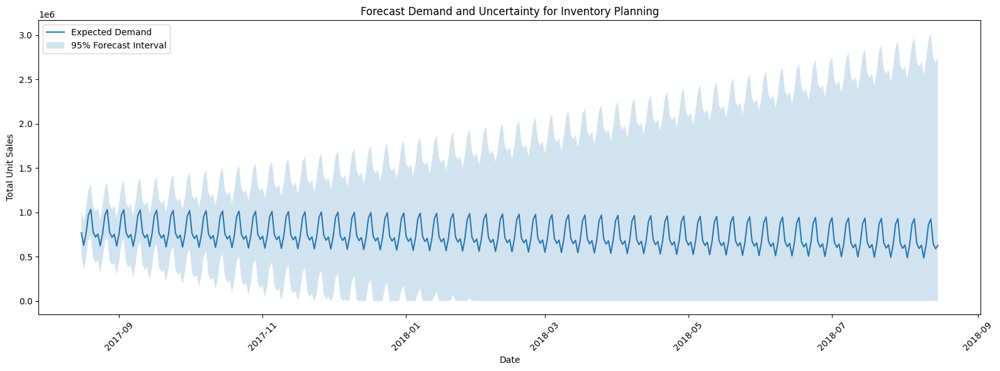

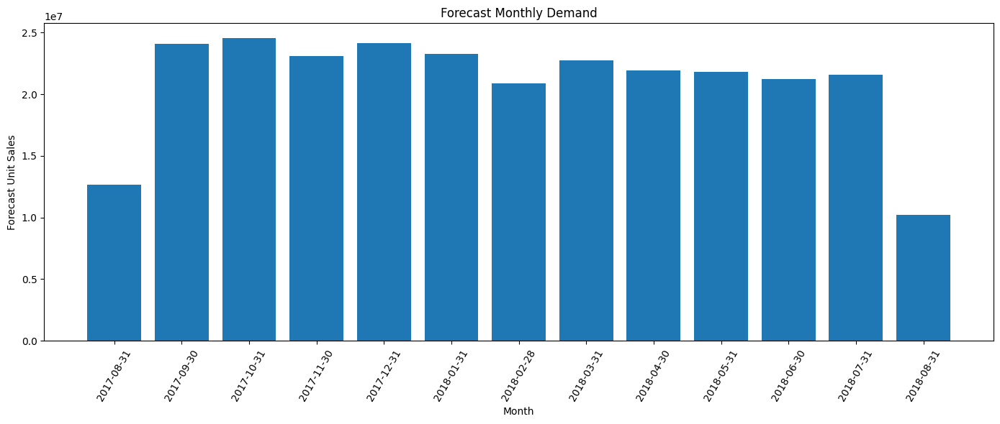


BUSINESS RECOMMENDATIONS

1. Inventory Planning
   Use the forecast as the baseline demand plan and maintain
   additional buffer stock during periods with wider uncertainty.

2. Short-Term Replenishment
   The 7-day and 14-day planning horizons can support frequent
   replenishment decisions where supplier lead times are short.

3. Longer Lead Times
   For suppliers with approximately 30-day lead times, use the
   30-day planning estimate together with the forecast uncertainty
   buffer rather than relying only on point forecasts.

4. Seasonal Planning
   Increase procurement and warehouse capacity ahead of months
   with higher forecast demand.

5. Uncertainty Management
   The confidence interval widens farther into the future.
   Therefore, long-range procurement decisions should be reviewed
   periodically and updated with newly observed sales.

6. Product-Level Planning
   These results represent aggregate demand. For operational SKU
   inventory decisions, the same forecasting 

In [92]:
# ============================================================
# STEP 29 — INVENTORY / SUPPLY CHAIN RECOMMENDATIONS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. CREATE DAILY INVENTORY PLANNING TABLE
# ============================================================

inventory_df = forecast_output.copy()

inventory_df["forecast"] = (
    inventory_df["forecast"].clip(lower=0)
)

inventory_df["lower_95"] = (
    inventory_df["lower_95"].clip(lower=0)
)

inventory_df["upper_95"] = (
    inventory_df["upper_95"].clip(lower=0)
)


# ------------------------------------------------------------
# Forecast uncertainty
# ------------------------------------------------------------

inventory_df["uncertainty_range"] = (
    inventory_df["upper_95"]
    -
    inventory_df["lower_95"]
)


inventory_df["uncertainty_pct"] = (
    inventory_df["uncertainty_range"]
    /
    inventory_df["forecast"].replace(0, np.nan)
) * 100


# ============================================================
# 2. SELECT PLANNING HORIZONS
# ============================================================

planning_horizons = {
    "7_days": 7,
    "14_days": 14,
    "30_days": 30
}


planning_results = []


# ============================================================
# 3. CALCULATE INVENTORY PLANNING LEVELS
# ============================================================

for horizon_name, days in planning_horizons.items():

    horizon_data = inventory_df.iloc[:days]

    expected_demand = (
        horizon_data["forecast"].sum()
    )

    conservative_demand = (
        horizon_data["upper_95"].sum()
    )

    lower_demand = (
        horizon_data["lower_95"].sum()
    )

    safety_buffer = (
        conservative_demand
        -
        expected_demand
    )

    planning_results.append({

        "Planning Horizon":
            horizon_name,

        "Days":
            days,

        "Expected Demand":
            expected_demand,

        "Lower Demand Bound":
            lower_demand,

        "Upper Demand Bound":
            conservative_demand,

        "Safety Buffer":
            safety_buffer,

        "Recommended Planning Stock":
            conservative_demand
    })


inventory_planning = pd.DataFrame(
    planning_results
)


# ============================================================
# 4. MONTHLY FORECAST ANALYSIS
# ============================================================

monthly_inventory = monthly_forecast.copy()

monthly_inventory["forecast_share"] = (
    monthly_inventory["forecast_units"]
    /
    monthly_inventory["forecast_units"].sum()
    * 100
)

monthly_inventory["uncertainty_width"] = (
    monthly_inventory["upper_95_units"]
    -
    monthly_inventory["lower_95_units"]
)


# ============================================================
# 5. IDENTIFY HIGH AND LOW FORECAST MONTHS
# ============================================================

top_months = (
    monthly_inventory
    .nlargest(
        3,
        "forecast_units"
    )
)

low_months = (
    monthly_inventory
    .nsmallest(
        3,
        "forecast_units"
    )
)


# ============================================================
# 6. PRINT INVENTORY PLANNING RESULTS
# ============================================================

print("=" * 70)
print("INVENTORY PLANNING — AGGREGATE DEMAND")
print("=" * 70)

display(
    inventory_planning.round(2)
)


print("\n" + "=" * 70)
print("TOP 3 HIGH-DEMAND FORECAST MONTHS")
print("=" * 70)

display(
    top_months[
        [
            "date",
            "forecast_units",
            "average_daily_forecast",
            "forecast_share"
        ]
    ].round(2)
)


print("\n" + "=" * 70)
print("BOTTOM 3 FORECAST MONTHS")
print("=" * 70)

display(
    low_months[
        [
            "date",
            "forecast_units",
            "average_daily_forecast",
            "forecast_share"
        ]
    ].round(2)
)


# ============================================================
# 7. 6-MONTH vs 12-MONTH PLANNING SUMMARY
# ============================================================

six_month_summary = {
    "Period": "6 Months",
    "Total Expected Demand":
        forecast_6m["forecast"].sum(),
    "Average Daily Demand":
        forecast_6m["forecast"].mean(),
    "Minimum Daily Forecast":
        forecast_6m["forecast"].min(),
    "Maximum Daily Forecast":
        forecast_6m["forecast"].max()
}

twelve_month_summary = {
    "Period": "12 Months",
    "Total Expected Demand":
        forecast_12m["forecast"].sum(),
    "Average Daily Demand":
        forecast_12m["forecast"].mean(),
    "Minimum Daily Forecast":
        forecast_12m["forecast"].min(),
    "Maximum Daily Forecast":
        forecast_12m["forecast"].max()
}

planning_summary = pd.DataFrame([
    six_month_summary,
    twelve_month_summary
])

print("\n" + "=" * 70)
print("6-MONTH VS 12-MONTH DEMAND SUMMARY")
print("=" * 70)

display(
    planning_summary.round(2)
)


# ============================================================
# 8. FORECAST UNCERTAINTY VISUALIZATION
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    inventory_df.index,
    inventory_df["forecast"],
    label="Expected Demand"
)

plt.fill_between(
    inventory_df.index,
    inventory_df["lower_95"],
    inventory_df["upper_95"],
    alpha=0.2,
    label="95% Forecast Interval"
)

plt.title(
    "Forecast Demand and Uncertainty for Inventory Planning"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 9. MONTHLY DEMAND VISUALIZATION
# ============================================================

plt.figure(figsize=(14, 6))

plt.bar(
    monthly_inventory["date"].astype(str),
    monthly_inventory["forecast_units"]
)

plt.title(
    "Forecast Monthly Demand"
)

plt.xlabel("Month")
plt.ylabel("Forecast Unit Sales")

plt.xticks(
    rotation=60
)

plt.tight_layout()
plt.show()


# ============================================================
# 10. GENERATE BUSINESS RECOMMENDATIONS
# ============================================================

print("\n" + "=" * 70)
print("BUSINESS RECOMMENDATIONS")
print("=" * 70)

print("""
1. Inventory Planning
   Use the forecast as the baseline demand plan and maintain
   additional buffer stock during periods with wider uncertainty.

2. Short-Term Replenishment
   The 7-day and 14-day planning horizons can support frequent
   replenishment decisions where supplier lead times are short.

3. Longer Lead Times
   For suppliers with approximately 30-day lead times, use the
   30-day planning estimate together with the forecast uncertainty
   buffer rather than relying only on point forecasts.

4. Seasonal Planning
   Increase procurement and warehouse capacity ahead of months
   with higher forecast demand.

5. Uncertainty Management
   The confidence interval widens farther into the future.
   Therefore, long-range procurement decisions should be reviewed
   periodically and updated with newly observed sales.

6. Product-Level Planning
   These results represent aggregate demand. For operational SKU
   inventory decisions, the same forecasting workflow should next
   be applied at product/store level.

7. Safety Stock
   Treat the upper forecast bound as a conservative planning
   scenario rather than guaranteed demand.

8. Reforecasting
   Refresh the forecast regularly as new sales observations become
   available rather than treating the 12-month forecast as fixed.
""")


# ============================================================
# 11. SAVE INVENTORY PLANNING OUTPUTS
# ============================================================

inventory_planning.to_csv(
    "/kaggle/working/inventory_planning.csv",
    index=False
)

monthly_inventory.to_csv(
    "/kaggle/working/monthly_inventory_forecast.csv",
    index=False
)

planning_summary.to_csv(
    "/kaggle/working/planning_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print("/kaggle/working/inventory_planning.csv")
print("/kaggle/working/monthly_inventory_forecast.csv")
print("/kaggle/working/planning_summary.csv")

STEP 30 — FINDING TOP 5 PRODUCTS

Top 5 products:


,item_nbr,historical_sales,family,class,perishable
0,1503844,6264199.76,PRODUCE,2022,1
1,1047679,5512875.00,BEVERAGES,1120,0
2,1473474,4990322.65,PRODUCE,2014,1
3,364606,4416426.00,GROCERY I,1014,0
4,819932,4410943.00,BEVERAGES,1122,0



EXTRACTING DAILY SALES FOR TOP 5 PRODUCTS
Rows extracted: 7044


,date,item_nbr,unit_sales
0,2013-01-01,364606,5.0
1,2013-01-01,1047679,32.0
2,2013-01-02,364606,4645.0
3,2013-01-02,819932,1923.0
4,2013-01-02,1047679,3102.0



PRODUCT TIME SERIES
Shape: (1688, 5)


item_nbr,364606,819932,1047679,1473474,1503844
date,,,,,
2013-01-01,5.0,0.0,32.0,0.0,0.0
2013-01-02,4645.0,1923.0,3102.0,0.0,0.0
2013-01-03,3618.0,960.0,2565.0,0.0,0.0
2013-01-04,2827.0,1770.0,2682.0,0.0,0.0
2013-01-05,3947.0,3648.0,3608.0,0.0,0.0



PRODUCT: 1503844
Training observations: 1323
Test observations: 365
SARIMA MAE: 1681.45
Seasonal Naive MAE: 946.73

PRODUCT: 1047679
Training observations: 1323
Test observations: 365
SARIMA MAE: 1321.0
Seasonal Naive MAE: 595.91

PRODUCT: 1473474
Training observations: 1323
Test observations: 365
SARIMA MAE: 1916.19
Seasonal Naive MAE: 486.62

PRODUCT: 364606
Training observations: 1323
Test observations: 365
SARIMA MAE: 363.49
Seasonal Naive MAE: 420.38

PRODUCT: 819932
Training observations: 1323
Test observations: 365
SARIMA MAE: 660.52
Seasonal Naive MAE: 834.26

PRODUCT-LEVEL MODEL ACCURACY


,item_nbr,family,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%)
0,1503844,PRODUCE,SARIMA - 1503844,1681.449,2118.274,35.019,62.637
1,1503844,PRODUCE,Seasonal Naive - 1503844,946.733,1427.652,17.724,83.791
2,1047679,BEVERAGES,SARIMA - 1047679,1320.997,1517.829,54.504,62.363
3,1047679,BEVERAGES,Seasonal Naive - 1047679,595.912,960.802,18.057,70.604
4,1473474,PRODUCE,SARIMA - 1473474,1916.193,2220.776,49.772,45.055
5,1473474,PRODUCE,Seasonal Naive - 1473474,486.625,751.623,9.992,90.934
6,364606,GROCERY I,SARIMA - 364606,363.493,551.201,50.455,72.253
7,364606,GROCERY I,Seasonal Naive - 364606,420.384,672.658,17.526,70.330
8,819932,BEVERAGES,SARIMA - 819932,660.520,1005.062,38.615,67.308
9,819932,BEVERAGES,Seasonal Naive - 819932,834.260,1312.867,36.741,62.088



PRODUCT-LEVEL COMPARISON


Directional Accuracy (%)                                    \
Model                      SARIMA - 1047679 SARIMA - 1473474 SARIMA - 1503844   
item_nbr family                                                                 
364606   GROCERY I                      NaN              NaN              NaN   
819932   BEVERAGES                      NaN              NaN              NaN   
1047679  BEVERAGES                   62.363              NaN              NaN   
1473474  PRODUCE                        NaN           45.055              NaN   
1503844  PRODUCE                        NaN              NaN           62.637   

                                                                             \
Model              SARIMA - 364606 SARIMA - 819932 Seasonal Naive - 1047679   
item_nbr family                                                               
364606   GROCERY I          72.253             NaN                      NaN   
819932   BEVERAGES             NaN          67.308                      NaN   
1047679  BEVERAGES             NaN             NaN                   70.604   
1473474  PRODUCE               NaN             NaN                      NaN   
1503844  PRODUCE               NaN             NaN                      NaN   

                                                                      \
Model              Seasonal Naive - 1473474 Seasonal Naive - 1503844   
item_nbr family                                                        
364606   GROCERY I                      NaN                      NaN   
819932   BEVERAGES                      NaN                      NaN   
1047679  BEVERAGES                      NaN                      NaN   
1473474  PRODUCE                     90.934                      NaN   
1503844  PRODUCE                        NaN                   83.791   

                                                                    ...  \
Model              Seasonal Naive - 364606 Seasonal Naive - 819932  ...   
item_nbr family                                                     ...   
364606   GROCERY I                   70.33                     NaN  ...   
819932   BEVERAGES                     NaN                  62.088  ...   
1047679  BEVERAGES                     NaN                     NaN  ...   
1473474  PRODUCE                       NaN                     NaN  ...   
1503844  PRODUCE                       NaN                     NaN  ...   

                               RMSE                                    \
Model              SARIMA - 1047679 SARIMA - 1473474 SARIMA - 1503844   
item_nbr family                                                         
364606   GROCERY I              NaN              NaN              NaN   
819932   BEVERAGES              NaN              NaN              NaN   
1047679  BEVERAGES         1517.829              NaN              NaN   
1473474  PRODUCE                NaN         2220.776              NaN   
1503844  PRODUCE                NaN              NaN         2118.274   

                                                                             \
Model              SARIMA - 364606 SARIMA - 819932 Seasonal Naive - 1047679   
item_nbr family                                                               
364606   GROCERY I         551.201             NaN                      NaN   
819932   BEVERAGES             NaN        1005.062                      NaN   
1047679  BEVERAGES             NaN             NaN                  960.802   
1473474  PRODUCE               NaN             NaN                      NaN   
1503844  PRODUCE               NaN             NaN                      NaN   

                                                                      \
Model              Seasonal Naive - 1473474 Seasonal Naive - 1503844   
item_nbr family                                                        
364606   GROCERY I                      NaN                      NaN   
819932   BEVERAGES                      NaN          

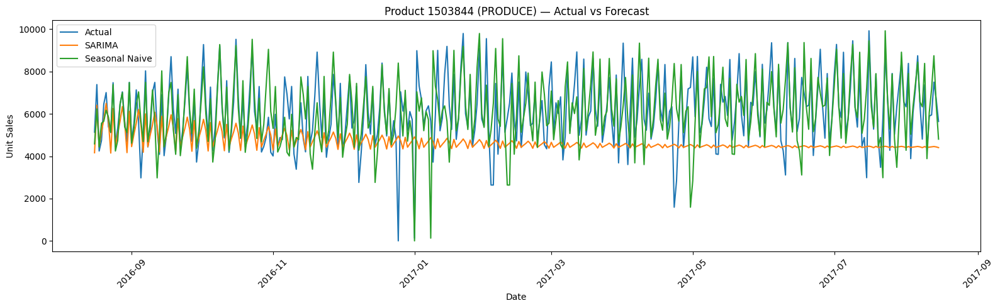

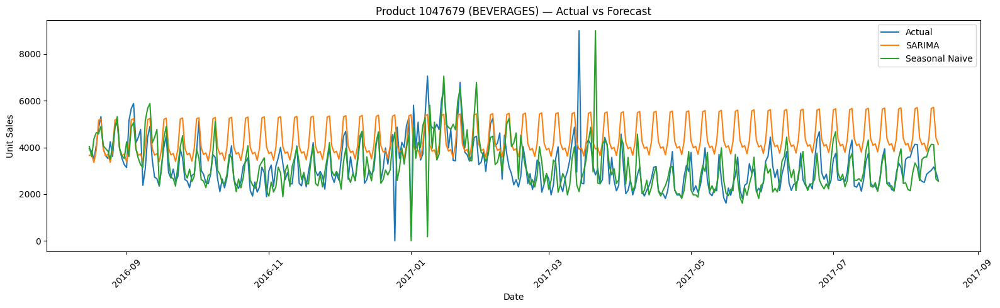

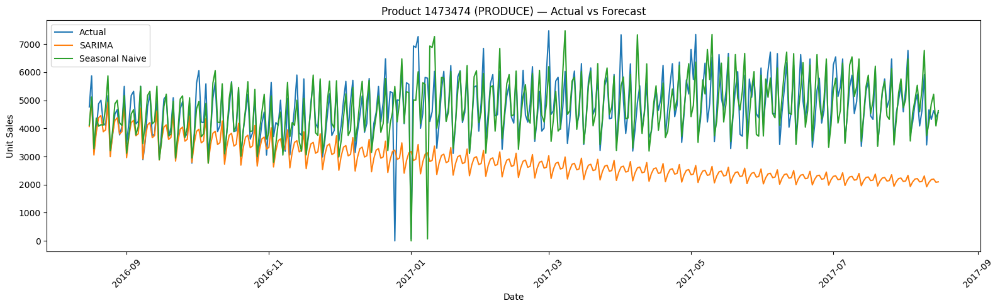

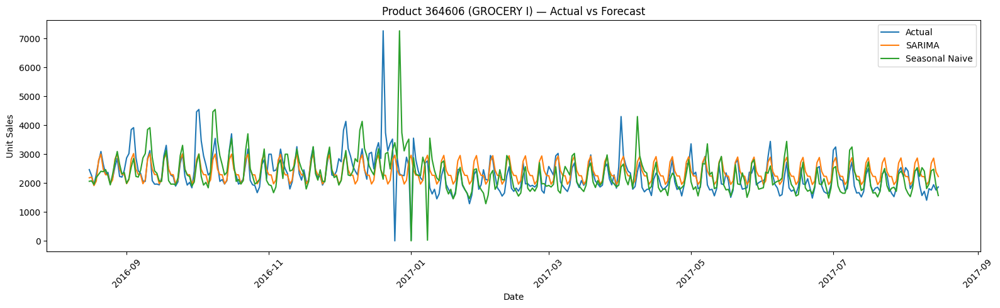

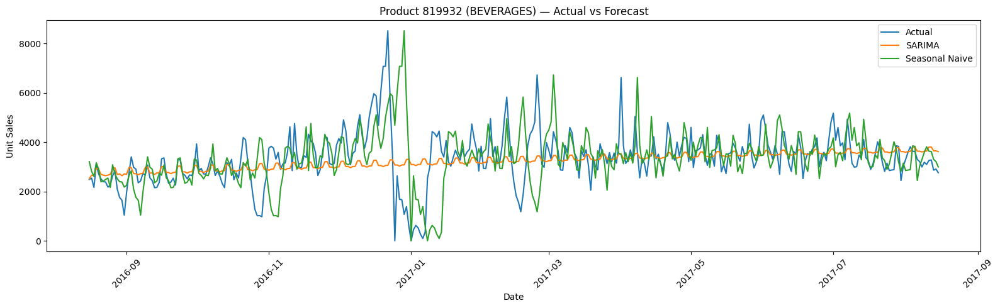


PRODUCT MODEL WIN/LOSS


,item_nbr,SARIMA_MAE,Seasonal_Naive_MAE,SARIMA_better
0,1503844,1681.449,946.733,False
1,1047679,1320.997,595.912,False
2,1473474,1916.193,486.625,False
3,364606,363.493,420.384,True
4,819932,660.520,834.260,True



SARIMA better for 2 of 5 products.

FILES SAVED
/kaggle/working/top_5_products.csv
/kaggle/working/top_5_product_daily_sales.csv
/kaggle/working/product_level_accuracy.csv
/kaggle/working/product_model_comparison.csv


In [93]:
# ============================================================
# STEP 30 — PRODUCT-LEVEL FORECASTING AND ACCURACY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")


# ============================================================
# 1. FIND TOP 5 PRODUCTS BY HISTORICAL SALES
# ============================================================

print("=" * 70)
print("STEP 30 — FINDING TOP 5 PRODUCTS")
print("=" * 70)

product_sales_parts = []

train_reader = pd.read_csv(
    train_path,
    usecols=["item_nbr", "unit_sales"],
    chunksize=250000
)

for chunk in train_reader:

    product_totals = (
        chunk
        .groupby("item_nbr")["unit_sales"]
        .sum()
    )

    product_sales_parts.append(
        product_totals
    )


product_sales = (
    pd.concat(product_sales_parts)
    .groupby(level=0)
    .sum()
    .sort_values(ascending=False)
)


top_5_products = (
    product_sales
    .head(5)
    .reset_index()
)

top_5_products.columns = [
    "item_nbr",
    "historical_sales"
]


# Add product information
top_5_products = top_5_products.merge(
    items[
        [
            "item_nbr",
            "family",
            "class",
            "perishable"
        ]
    ],
    on="item_nbr",
    how="left"
)


print("\nTop 5 products:")
display(
    top_5_products.round(2)
)


# ============================================================
# 2. EXTRACT DAILY SALES FOR TOP 5 PRODUCTS
# ============================================================

top_product_ids = (
    top_5_products["item_nbr"]
    .tolist()
)

print("\n" + "=" * 70)
print("EXTRACTING DAILY SALES FOR TOP 5 PRODUCTS")
print("=" * 70)

product_daily_parts = []

train_reader = pd.read_csv(
    train_path,
    usecols=[
        "date",
        "item_nbr",
        "unit_sales"
    ],
    chunksize=250000
)

for chunk in train_reader:

    # Keep only top products
    filtered = chunk[
        chunk["item_nbr"].isin(top_product_ids)
    ].copy()

    if len(filtered) == 0:
        continue

    filtered["date"] = pd.to_datetime(
        filtered["date"]
    )

    grouped = (
        filtered
        .groupby(
            ["date", "item_nbr"]
        )["unit_sales"]
        .sum()
        .reset_index()
    )

    product_daily_parts.append(
        grouped
    )


product_daily = pd.concat(
    product_daily_parts,
    ignore_index=True
)

# Combine any duplicate date/product records
product_daily = (
    product_daily
    .groupby(
        ["date", "item_nbr"]
    )["unit_sales"]
    .sum()
    .reset_index()
)


print("Rows extracted:", len(product_daily))

display(
    product_daily.head()
)


# ============================================================
# 3. CREATE COMPLETE DAILY PRODUCT SERIES
# ============================================================

full_dates = pd.date_range(
    start=forecast_df["date"].min(),
    end=forecast_df["date"].max(),
    freq="D"
)

product_series = (
    product_daily
    .pivot(
        index="date",
        columns="item_nbr",
        values="unit_sales"
    )
    .reindex(full_dates)
)


product_series.index.name = "date"


# IMPORTANT:
# Favorita does not explicitly store every zero-sales
# product/date combination.
#
# Here we use zero for an unrecorded top-product/date
# observation so that the product series can be modeled
# at daily frequency.
#
# This is an assumption and should be documented in
# the final report.

product_series = product_series.fillna(0)


print("\n" + "=" * 70)
print("PRODUCT TIME SERIES")
print("=" * 70)

print("Shape:", product_series.shape)

display(
    product_series.head()
)


# ============================================================
# 4. PRODUCT-LEVEL TEST PERIOD
# ============================================================

product_accuracy_results = []

product_predictions = {}


TEST_START = pd.Timestamp("2016-08-16")
TEST_END = pd.Timestamp("2017-08-15")


# ============================================================
# 5. FORECAST EACH TOP PRODUCT
# ============================================================

for item_id in top_product_ids:

    print("\n" + "=" * 70)
    print("PRODUCT:", item_id)
    print("=" * 70)

    product_ts = (
        product_series[item_id]
        .asfreq("D")
    )

    product_train = product_ts.loc[
        product_ts.index < TEST_START
    ]

    product_test = product_ts.loc[
        (product_ts.index >= TEST_START) &
        (product_ts.index <= TEST_END)
    ]


    print(
        "Training observations:",
        len(product_train)
    )

    print(
        "Test observations:",
        len(product_test)
    )


    # --------------------------------------------------------
    # Seasonal Naive
    # --------------------------------------------------------

    combined_product = pd.concat([
        product_train,
        product_test
    ])

    seasonal_naive_pred = (
        combined_product
        .shift(7)
        .loc[product_test.index]
        .clip(lower=0)
    )


    # --------------------------------------------------------
    # Tuned SARIMA
    # --------------------------------------------------------

    try:

        product_model = SARIMAX(
            product_train,
            order=(2, 1, 2),
            seasonal_order=(1, 0, 1, 7),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        product_result = product_model.fit(
            disp=False
        )

        sarima_pred = (
            product_result
            .forecast(
                steps=len(product_test)
            )
        )

        sarima_pred.index = (
            product_test.index
        )

        # Demand cannot be negative
        sarima_pred = sarima_pred.clip(
            lower=0
        )


        # ----------------------------------------------------
        # Calculate metrics
        # ----------------------------------------------------

        sarima_metrics = calculate_metrics(
            product_test,
            sarima_pred,
            f"SARIMA - {item_id}"
        )

        seasonal_metrics = calculate_metrics(
            product_test,
            seasonal_naive_pred,
            f"Seasonal Naive - {item_id}"
        )


        # Add product metadata
        product_family = (
            top_5_products
            .loc[
                top_5_products["item_nbr"] == item_id,
                "family"
            ]
            .iloc[0]
        )


        for result in [
            sarima_metrics,
            seasonal_metrics
        ]:

            result["item_nbr"] = item_id
            result["family"] = product_family


        product_accuracy_results.extend([
            sarima_metrics,
            seasonal_metrics
        ])


        product_predictions[item_id] = {
            "actual": product_test,
            "sarima": sarima_pred,
            "seasonal_naive":
                seasonal_naive_pred
        }


        print("SARIMA MAE:",
              round(sarima_metrics["MAE"], 2))

        print("Seasonal Naive MAE:",
              round(seasonal_metrics["MAE"], 2))


    except Exception as e:

        print(
            "SARIMA failed for product:",
            item_id
        )

        print(
            "Error:",
            str(e)[:200]
        )


# ============================================================
# 6. PRODUCT ACCURACY TABLE
# ============================================================

product_accuracy = pd.DataFrame(
    product_accuracy_results
)


print("\n" + "=" * 70)
print("PRODUCT-LEVEL MODEL ACCURACY")
print("=" * 70)

display(
    product_accuracy[
        [
            "item_nbr",
            "family",
            "Model",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ].round(3)
)


# ============================================================
# 7. PRODUCT COMPARISON — SARIMA VS SEASONAL NAIVE
# ============================================================

product_comparison = (
    product_accuracy
    .pivot_table(
        index=[
            "item_nbr",
            "family"
        ],
        columns="Model",
        values=[
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    )
)


print("\n" + "=" * 70)
print("PRODUCT-LEVEL COMPARISON")
print("=" * 70)

display(
    product_comparison.round(3)
)


# ============================================================
# 8. ACTUAL VS PREDICTED — EACH PRODUCT
# ============================================================

for item_id in top_product_ids:

    if item_id not in product_predictions:
        continue

    result = product_predictions[item_id]

    plt.figure(figsize=(16, 5))

    plt.plot(
        result["actual"].index,
        result["actual"].values,
        label="Actual"
    )

    plt.plot(
        result["sarima"].index,
        result["sarima"].values,
        label="SARIMA"
    )

    plt.plot(
        result["seasonal_naive"].index,
        result["seasonal_naive"].values,
        label="Seasonal Naive"
    )

    family = (
        top_5_products
        .loc[
            top_5_products["item_nbr"] == item_id,
            "family"
        ]
        .iloc[0]
    )

    plt.title(
        f"Product {item_id} ({family}) — "
        f"Actual vs Forecast"
    )

    plt.xlabel("Date")
    plt.ylabel("Unit Sales")

    plt.legend()

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


# ============================================================
# 9. FIND PRODUCTS WHERE SARIMA BEATS SEASONAL NAIVE
# ============================================================

sarima_product_mae = (
    product_accuracy[
        product_accuracy["Model"]
        .str.startswith("SARIMA")
    ][
        [
            "item_nbr",
            "MAE"
        ]
    ]
    .rename(
        columns={
            "MAE":
                "SARIMA_MAE"
        }
    )
)

naive_product_mae = (
    product_accuracy[
        product_accuracy["Model"]
        .str.startswith("Seasonal Naive")
    ][
        [
            "item_nbr",
            "MAE"
        ]
    ]
    .rename(
        columns={
            "MAE":
                "Seasonal_Naive_MAE"
        }
    )
)

product_model_comparison = (
    sarima_product_mae
    .merge(
        naive_product_mae,
        on="item_nbr",
        how="inner"
    )
)

product_model_comparison[
    "SARIMA_better"
] = (
    product_model_comparison[
        "SARIMA_MAE"
    ]
    <
    product_model_comparison[
        "Seasonal_Naive_MAE"
    ]
)


print("\n" + "=" * 70)
print("PRODUCT MODEL WIN/LOSS")
print("=" * 70)

display(
    product_model_comparison.round(3)
)


print(
    "\nSARIMA better for",
    product_model_comparison["SARIMA_better"].sum(),
    "of",
    len(product_model_comparison),
    "products."
)


# ============================================================
# 10. SAVE PRODUCT-LEVEL OUTPUTS
# ============================================================

top_5_products.to_csv(
    "/kaggle/working/top_5_products.csv",
    index=False
)

product_daily.to_csv(
    "/kaggle/working/top_5_product_daily_sales.csv",
    index=False
)

product_accuracy.to_csv(
    "/kaggle/working/product_level_accuracy.csv",
    index=False
)

product_model_comparison.to_csv(
    "/kaggle/working/product_model_comparison.csv",
    index=False
)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print("/kaggle/working/top_5_products.csv")
print("/kaggle/working/top_5_product_daily_sales.csv")
print("/kaggle/working/product_level_accuracy.csv")
print("/kaggle/working/product_model_comparison.csv")

FINAL MODEL COMPARISON — VALIDATION


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%)
0,"SARIMA(1,1,1)(1,0,1,7)",81682.163,122035.230,9.834,82.873
1,Exponential Smoothing,88279.886,119269.202,11.178,80.110
2,Seasonal Naive (7-day),116352.289,165783.896,14.426,80.663
3,Prophet,124194.632,152769.648,16.662,76.243
4,Naive,130410.733,168915.085,16.084,60.773
5,"ARIMA(2,1,2)",132584.086,166812.358,16.677,60.773
6,LSTM,154280.955,177664.195,21.172,59.669



FINAL TEST RESULTS


,Model,MAE,RMSE,MAPE (%),Directional Accuracy (%),MAPE Zero Exclusions
0,Tuned SARIMA,102726.907,159075.85,31.356,79.945,1
1,Seasonal Naive,107350.712,167139.97,12.055,81.319,1



PRODUCT-LEVEL ACCURACY


...


INVENTORY PLANNING SUMMARY


,Planning Horizon,Days,Expected Demand,Lower Demand Bound,Upper Demand Bound,Safety Buffer,Recommended Planning Stock
0,7_days,7,5666557.06,3707337.35,7625776.77,1959219.71,7625776.77
1,14_days,14,11301930.85,7200075.45,15403786.25,4101855.40,15403786.25
2,30_days,30,23886813.40,14261483.17,33512143.63,9625330.23,33512143.63



TOP 5 PRODUCTS BY HISTORICAL DEMAND


,item_nbr,historical_sales,family,class,perishable
0,1503844,6264199.76,PRODUCE,2022,1
1,1047679,5512875.00,BEVERAGES,1120,0
2,1473474,4990322.65,PRODUCE,2014,1
3,364606,4416426.00,GROCERY I,1014,0
4,819932,4410943.00,BEVERAGES,1122,0



BEST VALIDATION MODEL BY MAE
Model: SARIMA(1,1,1)(1,0,1,7)
MAE: 81682.163

BEST TEST MODEL BY MAE
Model: Tuned SARIMA
MAE: 102726.907
RMSE: 159075.85
MAPE: 31.356
Directional Accuracy: 79.945


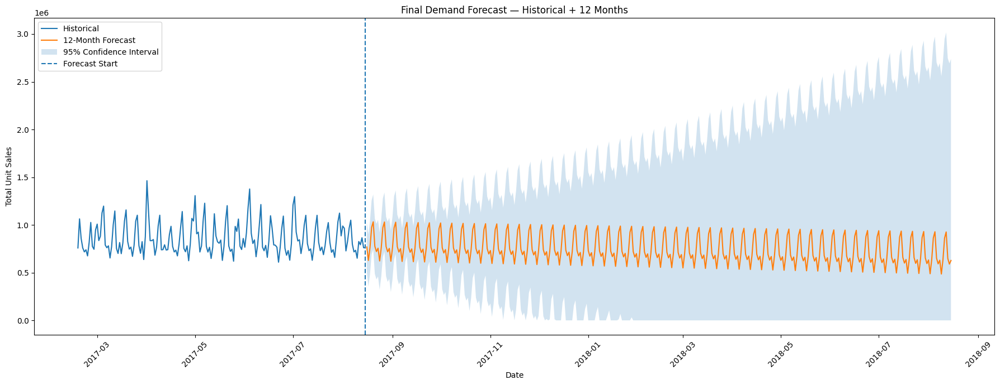

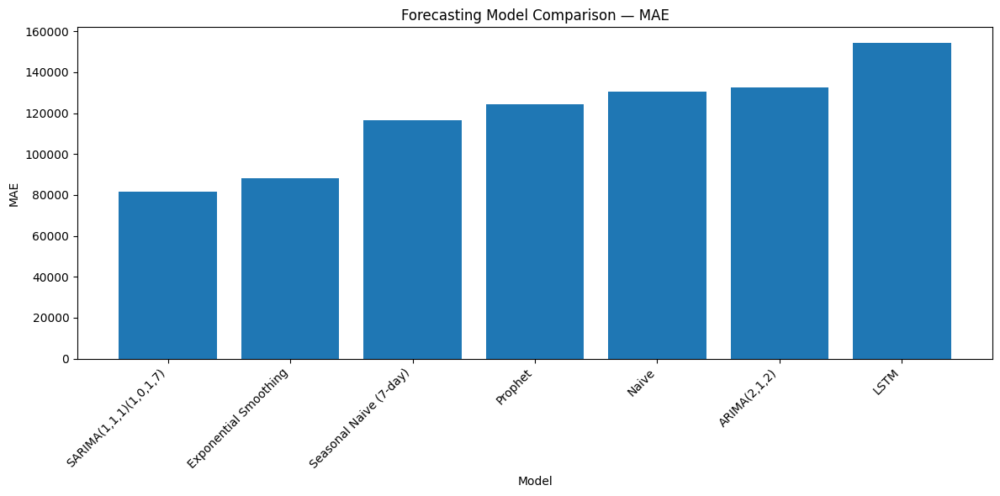


FINAL REPORT FILES SAVED
/kaggle/working/final_model_comparison.csv
/kaggle/working/final_test_model_results.csv
/kaggle/working/final_product_accuracy.csv
/kaggle/working/product_model_win_summary.csv
/kaggle/working/final_forecast_summary.csv
/kaggle/working/final_inventory_planning.csv


In [94]:
# ============================================================
# STEP 31 — FINAL PROJECT REPORT TABLES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. FINAL MODEL COMPARISON
# ============================================================

final_model_comparison = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results,
        exp_results,
        prophet_results,
        lstm_results
    ],
    ignore_index=True
)

final_model_comparison = (
    final_model_comparison[
        [
            "Model",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ]
    .sort_values("MAE")
    .reset_index(drop=True)
)


print("=" * 70)
print("FINAL MODEL COMPARISON — VALIDATION")
print("=" * 70)

display(
    final_model_comparison.round(3)
)


# ============================================================
# 2. FINAL TEST RESULTS
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

display(
    final_test_results.round(3)
)


# ============================================================
# 3. PRODUCT-LEVEL ACCURACY
# ============================================================

product_accuracy_summary = (
    product_accuracy[
        [
            "item_nbr",
            "family",
            "Model",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ]
    .sort_values(
        ["item_nbr", "MAE"]
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 70)
print("PRODUCT-LEVEL ACCURACY")
print("=" * 70)

display(
    product_accuracy_summary.round(3)
)


# ============================================================
# 4. PRODUCT MODEL WIN COUNT
# ============================================================

product_win_summary = pd.DataFrame({
    "Comparison": [
        "SARIMA better than Seasonal Naive"
    ],
    "Products Won": [
        product_model_comparison[
            "SARIMA_better"
        ].sum()
    ],
    "Products Evaluated": [
        len(product_model_comparison)
    ]
})

product_win_summary["Win Rate (%)"] = (
    product_win_summary["Products Won"]
    /
    product_win_summary["Products Evaluated"]
    * 100
)


print("\n" + "=" * 70)
print("PRODUCT-LEVEL MODEL WIN RATE")
print("=" * 70)

display(
    product_win_summary.round(2)
)


# ============================================================
# 5. FORECAST SUMMARY
# ============================================================

forecast_summary = pd.DataFrame({

    "Horizon": [
        "6 Months",
        "12 Months"
    ],

    "Start Date": [
        forecast_6m.index.min(),
        forecast_12m.index.min()
    ],

    "End Date": [
        forecast_6m.index.max(),
        forecast_12m.index.max()
    ],

    "Total Forecast Demand": [
        forecast_6m["forecast"].sum(),
        forecast_12m["forecast"].sum()
    ],

    "Average Daily Demand": [
        forecast_6m["forecast"].mean(),
        forecast_12m["forecast"].mean()
    ]
})


print("\n" + "=" * 70)
print("FINAL FORECAST SUMMARY")
print("=" * 70)

display(
    forecast_summary.round(2)
)


# ============================================================
# 6. INVENTORY SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("INVENTORY PLANNING SUMMARY")
print("=" * 70)

display(
    inventory_planning.round(2)
)


# ============================================================
# 7. TOP PRODUCTS
# ============================================================

print("\n" + "=" * 70)
print("TOP 5 PRODUCTS BY HISTORICAL DEMAND")
print("=" * 70)

display(
    top_5_products.round(2)
)


# ============================================================
# 8. BEST VALIDATION MODEL
# ============================================================

best_validation_model = (
    final_model_comparison
    .iloc[0]["Model"]
)

best_validation_mae = (
    final_model_comparison
    .iloc[0]["MAE"]
)

print("\n" + "=" * 70)
print("BEST VALIDATION MODEL BY MAE")
print("=" * 70)

print(
    "Model:",
    best_validation_model
)

print(
    "MAE:",
    round(best_validation_mae, 3)
)


# ============================================================
# 9. FINAL TEST MODEL COMPARISON
# ============================================================

best_test_by_mae = (
    final_test_results
    .sort_values("MAE")
    .iloc[0]
)

print("\n" + "=" * 70)
print("BEST TEST MODEL BY MAE")
print("=" * 70)

print(
    "Model:",
    best_test_by_mae["Model"]
)

print(
    "MAE:",
    round(best_test_by_mae["MAE"], 3)
)

print(
    "RMSE:",
    round(best_test_by_mae["RMSE"], 3)
)

print(
    "MAPE:",
    round(best_test_by_mae["MAPE (%)"], 3)
)

print(
    "Directional Accuracy:",
    round(
        best_test_by_mae[
            "Directional Accuracy (%)"
        ],
        3
    )
)


# ============================================================
# 10. FINAL FORECAST PLOT
# ============================================================

plt.figure(figsize=(18, 7))

recent_history = final_series.tail(180)

plt.plot(
    recent_history.index,
    recent_history.values,
    label="Historical"
)

plt.plot(
    forecast_output.index,
    forecast_output["forecast"],
    label="12-Month Forecast"
)

plt.fill_between(
    forecast_output.index,
    forecast_output["lower_95_inventory"],
    forecast_output["upper_95_inventory"],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.axvline(
    final_series.index.max(),
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    "Final Demand Forecast — Historical + 12 Months"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 11. MODEL MAE COMPARISON
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["MAE"]
)

plt.title(
    "Forecasting Model Comparison — MAE"
)

plt.xlabel("Model")
plt.ylabel("MAE")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. SAVE FINAL REPORT TABLES
# ============================================================

final_model_comparison.to_csv(
    "/kaggle/working/final_model_comparison.csv",
    index=False
)

final_test_results.to_csv(
    "/kaggle/working/final_test_model_results.csv",
    index=False
)

product_accuracy_summary.to_csv(
    "/kaggle/working/final_product_accuracy.csv",
    index=False
)

product_win_summary.to_csv(
    "/kaggle/working/product_model_win_summary.csv",
    index=False
)

forecast_summary.to_csv(
    "/kaggle/working/final_forecast_summary.csv",
    index=False
)

inventory_planning.to_csv(
    "/kaggle/working/final_inventory_planning.csv",
    index=False
)

print("\n" + "=" * 70)
print("FINAL REPORT FILES SAVED")
print("=" * 70)

print("/kaggle/working/final_model_comparison.csv")
print("/kaggle/working/final_test_model_results.csv")
print("/kaggle/working/final_product_accuracy.csv")
print("/kaggle/working/product_model_win_summary.csv")
print("/kaggle/working/final_forecast_summary.csv")
print("/kaggle/working/final_inventory_planning.csv")

In [96]:
# ============================================================
# STEP 33 — FINAL DELIVERABLES REPORT
# ============================================================
#
# Creates ONE Markdown report containing:
#
# 1. Project overview
# 2. Dataset and methodology
# 3. EDA findings
# 4. Stationarity + ACF/PACF
# 5. Model comparison
# 6. Hyperparameter tuning
# 7. Backtesting
# 8. Final test evaluation
# 9. Actual vs predicted plot placeholders
# 10. Product-level accuracy metrics
# 11. Confidence interval plot placeholders
# 12. 6/12-month forecasts
# 13. Inventory recommendations
# 14. Business recommendations
# 15. Limitations
# 16. Conclusion
#
# Output:
# /kaggle/working/Favorita_Demand_Forecasting_Report.md
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np


# ============================================================
# 1. HELPER FUNCTION
# ============================================================

def md_table(df, index=False, round_digits=2):
    """
    Convert DataFrame to clean Markdown table.
    """
    temp = df.copy()

    # Round numeric columns
    for col in temp.select_dtypes(
        include=["float64", "float32", "int64", "int32"]
    ).columns:

        temp[col] = temp[col].round(round_digits)

    try:
        return temp.to_markdown(
            index=index
        )
    except Exception:
        return temp.to_string(
            index=index
        )


# ============================================================
# 2. REPORT PATH
# ============================================================

report_path = Path(
    "/kaggle/working/"
    "Favorita_Demand_Forecasting_Report.md"
)


# ============================================================
# 3. SAFELY PREPARE AVAILABLE RESULTS
# ============================================================

# Validation model comparison
validation_results = final_model_comparison.copy()

# Final test results
test_results = final_test_results.copy()

# Product-level accuracy
product_results = product_accuracy_summary.copy()

# Forecast summary
forecast_results = forecast_summary.copy()

# Inventory planning
inventory_results = inventory_planning.copy()

# Top products
top_products = top_5_products.copy()

# Monthly forecasts
monthly_results = monthly_forecast.copy()


# ============================================================
# 4. EXTRACT IMPORTANT VALUES
# ============================================================

try:

    tuned_sarima_validation = best_sarima_metrics_df.iloc[0]

except Exception:

    tuned_sarima_validation = sarima_results.iloc[0]


try:

    test_sarima = test_results[
        test_results["Model"] == "Tuned SARIMA"
    ].iloc[0]

except Exception:

    test_sarima = test_results.iloc[0]


try:

    test_seasonal_naive = test_results[
        test_results["Model"] == "Seasonal Naive"
    ].iloc[0]

except Exception:

    test_seasonal_naive = None


# Forecast quantities
six_month_total = forecast_6m["forecast"].sum()
six_month_average = forecast_6m["forecast"].mean()

twelve_month_total = forecast_12m["forecast"].sum()
twelve_month_average = forecast_12m["forecast"].mean()


# Highest forecast month
highest_forecast_month = monthly_results.loc[
    monthly_results["forecast_units"].idxmax()
]


# Lowest forecast month
lowest_forecast_month = monthly_results.loc[
    monthly_results["forecast_units"].idxmin()
]


# Product-level SARIMA win count
try:

    product_sarima_wins = int(
        product_model_comparison[
            "SARIMA_better"
        ].sum()
    )

    product_total_evaluated = int(
        len(product_model_comparison)
    )

    product_win_rate = (
        product_sarima_wins
        /
        product_total_evaluated
        *
        100
    )

except Exception:

    product_sarima_wins = None
    product_total_evaluated = None
    product_win_rate = None


# ============================================================
# 5. BUILD REPORT
# ============================================================

report = f"""
# Favorita Grocery Sales Demand Forecasting

## Model Comparison, Forecasting Results, Accuracy Analysis, and Inventory Planning

---

# 1. Executive Summary

### Objective

The objective of this project is to forecast future product demand
for approximately 6–12 months using the Favorita Grocery Sales
Forecasting dataset.

The forecasts are intended to support:

- inventory planning
- supply-chain planning
- replenishment decisions
- seasonal procurement
- demand-risk assessment

The main aggregate forecasting series was constructed by
aggregating sales by date across stores and products.

### Historical Period

**2013-01-01 to 2017-08-15**

### Main Forecast Horizon

**6 months:** {forecast_6m.index.min().date()} to {forecast_6m.index.max().date()}

**12 months:** {forecast_12m.index.min().date()} to {forecast_12m.index.max().date()}

### Final Forecast Model

Tuned seasonal ARIMA:

**SARIMA(2,1,2)(1,0,1,7)**

### Important Evaluation Finding

The tuned SARIMA model produced the lowest MAE on the final
test period, while the 7-day Seasonal Naive model produced lower
MAPE and higher directional accuracy.

Therefore, no single model dominates every evaluation metric.

---

# 2. Dataset Overview

## Dataset

Favorita Grocery Sales Forecasting dataset from Kaggle.

### Main datasets used

- `train.csv`
- `items.csv`
- `stores.csv`
- `holidays_events.csv`

Additional Favorita datasets were available for extended feature
engineering.

## Dataset scale

### Product catalog

- 4,100 products
- 33 product families
- 337 product classes

### Stores

- 54 stores
- 22 cities
- 16 states
- 5 store types
- 17 store clusters

### Historical sales

The extracted training CSV was approximately 5 GB, so chunk-based
processing was used instead of loading the complete file into memory.

---

# 3. Data Preparation

The original sales data was recorded approximately at:

**Date × Store × Product**

level.

The aggregate forecasting dataset was created as:

**Date → Total Unit Sales**

This produced a daily time series covering the historical period.

## Missing calendar dates

Four dates were absent from the raw aggregate sales series:

- 2013-12-25
- 2014-12-25
- 2015-12-25
- 2016-12-25

These corresponded to Christmas (`Navidad`) national holidays in
the holiday dataset.

For the aggregate forecasting series, these dates were represented
as zero recorded demand and retained with a `structural_missing`
indicator.

## Negative sales

The raw data contained negative `unit_sales` observations,
consistent with returns in the competition data.

Number of negative raw observations identified:

**7,795**

These were not blindly removed before aggregation.

---

# 4. Exploratory Data Analysis

## Major EDA Findings

### Long-term trend

Average daily demand increased substantially across the historical
period.

### Monthly seasonality

December showed the highest average daily sales among the months.

### Weekly seasonality

Demand varied considerably by day of week.

The highest average daily demand occurred on:

**Sunday**

The lowest occurred on:

**Thursday**

### Holiday effect

Holiday and non-holiday demand showed different average sales
levels.

### Outliers

Five aggregate daily observations were flagged using the IQR
method.

These observations were retained because unusually high demand
can represent genuine business behavior rather than bad data.

---

# 5. EDA Visualizations

## Daily Sales Trend

[image - Daily Total Sales Over Time]

## Daily Sales Distribution

[image - Distribution of Daily Total Sales]

## Weekly Sales Trend

[image - Weekly Total Sales Over Time]

## Monthly Sales Trend

[image - Monthly Total Sales Over Time]

## Average Sales by Month

[image - Average Daily Sales by Month]

## Average Sales by Day of Week

[image - Average Daily Sales by Day of Week]

## Year × Month Seasonality

[image - Year by Month Sales Heatmap]

## Holiday vs Non-Holiday Demand

[image - Holiday vs Non-Holiday Sales]

---

# 6. Time-Based Feature Engineering

The final feature dataset included:

- year
- month
- quarter
- day
- day of week
- day name
- weekend indicator
- holiday indicator
- holiday count
- holiday type
- holiday description
- holiday locale

The dataset was saved as:

`daily_sales_features.csv`

---

# 7. Stationarity Analysis

The Augmented Dickey-Fuller test was performed.

## Original Series

ADF Statistic:

**-2.5721**

p-value:

**0.09891**

Conclusion:

The original series was treated as non-stationary at the 5%
significance level.

## First Difference

ADF Statistic:

**-11.3137**

p-value:

**1.22e-20**

Conclusion:

The first-differenced series was stationary.

## Seven-Day Difference

ADF Statistic:

**-12.7575**

p-value:

**8.28e-24**

Conclusion:

The 7-day differenced series was stationary.

---

# 8. ACF and PACF Analysis

The first-differenced ACF showed strong autocorrelation at lag 7.

### Important result

**ACF at lag 7 ≈ 0.646**

This provided evidence of weekly seasonality.

The forecasting models therefore used:

**Seasonal period = 7 days**

## ACF Plot

[image - ACF Plot]

## PACF Plot

[image - PACF Plot]

## Seasonal ACF Plot

[image - Seasonal ACF Plot]

## Seasonal PACF Plot

[image - Seasonal PACF Plot]

---

# 9. Train / Validation / Test Strategy

The data was split chronologically.

## Training

**2013-01-01 to 2016-02-15**

1,141 observations.

## Validation

**2016-02-16 to 2016-08-15**

182 observations.

## Test

**2016-08-16 to 2017-08-15**

365 observations.

No random shuffling was used.

This preserves the time-dependent nature of forecasting and avoids
future-information leakage.

---

# 10. Baseline Models

Two simple baselines were established:

### Naive

The next value is based on the latest observed value.

### Seasonal Naive

The forecast uses the value from 7 days earlier.

The Seasonal Naive baseline was particularly important because
weekly seasonality was detected in the EDA and ACF analysis.

---

# 11. Forecasting Models

The following models were implemented:

1. Naive
2. Seasonal Naive
3. ARIMA
4. SARIMA
5. Exponential Smoothing
6. Prophet
7. LSTM

Evaluation metrics:

- MAE
- RMSE
- MAPE
- Directional Accuracy

---

# 12. Model Comparison — Validation

{md_table(validation_results, index=False, round_digits=3)}

### Validation Interpretation

The initial SARIMA model:

**SARIMA(1,1,1)(1,0,1,7)**

produced the lowest validation MAE:

**{sarima_results["MAE"].iloc[0]:,.3f}**

The Exponential Smoothing model was also competitive.

The LSTM model produced higher error on this aggregate daily series
than the statistical seasonal models.

---

# 13. Hyperparameter Tuning

A SARIMA grid search containing:

**36 parameter combinations**

was performed.

The selected tuned model was:

**SARIMA(2,1,2)(1,0,1,7)**

## Tuned Validation Metrics

| Metric | Result |
|---|---:|
| MAE | {tuned_sarima_validation["MAE"]:,.3f} |
| RMSE | {tuned_sarima_validation["RMSE"]:,.3f} |
| MAPE | {tuned_sarima_validation["MAPE (%)"]:.3f}% |
| Directional Accuracy | {tuned_sarima_validation["Directional Accuracy (%)"]:.3f}% |

The tuning improvement in MAE was approximately:

**0.3%**

---

# 14. Backtesting

Expanding-window backtesting was performed using:

- 90-day forecast horizon
- 4 historical folds
- tuned SARIMA
- 7-day Seasonal Naive

## Pooled Backtesting Results

{md_table(
    pooled_results[
        [
            "Model",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ],
    index=False,
    round_digits=3
)}

### Backtesting Interpretation

The Seasonal Naive model was more consistent across the four
historical folds.

Tuned SARIMA performed better on:

**2 of 4 folds**

This demonstrates that model performance changes depending on the
historical period.

## Backtesting MAE

[image - Backtesting MAE by Fold]

## Backtesting Example

[image - Backtest Fold 1 Actual vs Forecast]

---

# 15. Final Test Evaluation

The final test period was:

**2016-08-16 to 2017-08-15**

{md_table(test_results, index=False, round_digits=3)}

## Test Interpretation

### Tuned SARIMA

- MAE: {test_sarima["MAE"]:,.3f}
- RMSE: {test_sarima["RMSE"]:,.3f}
- MAPE: {test_sarima["MAPE (%)"]:.3f}%
- Directional Accuracy: {test_sarima["Directional Accuracy (%)"]:.3f}%

### Seasonal Naive

"""

if test_seasonal_naive is not None:

    report += f"""
- MAE: {test_seasonal_naive["MAE"]:,.3f}
- RMSE: {test_seasonal_naive["RMSE"]:,.3f}
- MAPE: {test_seasonal_naive["MAPE (%)"]:.3f}%
- Directional Accuracy: {test_seasonal_naive["Directional Accuracy (%)"]:.3f}%
"""

report += f"""
The tuned SARIMA model achieved a lower MAE on the final test
period, while Seasonal Naive achieved lower MAPE and higher
directional accuracy.

This difference should be explicitly considered when interpreting
forecast accuracy for business use.

---

# 16. Final Actual vs Predicted Visualizations

## Validation — Seasonal Naive

[image - Actual vs Seasonal Naive — Validation]

## Validation — ARIMA

[image - Actual vs ARIMA — Validation]

## Validation — SARIMA

[image - Actual vs SARIMA — Validation]

## Validation — Exponential Smoothing

[image - Actual vs Exponential Smoothing — Validation]

## Validation — Prophet

[image - Actual vs Prophet — Validation]

## Validation — LSTM

[image - Actual vs LSTM — Validation]

## Validation — Main Model Comparison

[image - Actual vs SARIMA vs Exponential Smoothing vs Prophet vs LSTM]

## Final Test — Actual vs Tuned SARIMA

[image - Final Test Actual vs Tuned SARIMA]

## Final Test — Actual vs Seasonal Naive

[image - Final Test Actual vs Seasonal Naive]

---

# 17. Product-Level Accuracy

The product-level analysis evaluated five high-demand products.

{md_table(
    product_results[
        [
            "item_nbr",
            "family",
            "Model",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "Directional Accuracy (%)"
        ]
    ],
    index=False,
    round_digits=3
)}

## Product-Level Model Comparison

[image - Product-Level Model Accuracy Comparison]

### Product-Level Findings

SARIMA achieved lower MAE than Seasonal Naive for:

**{product_sarima_wins} of {product_total_evaluated} products**

Win rate:

**{product_win_rate:.1f}%**

The results show that the best forecasting method can vary by
product.

---

# 18. Product-Level Actual vs Predicted Plots

## Product 1

[image - Product 1 Actual vs Predicted]

## Product 2

[image - Product 2 Actual vs Predicted]

## Product 3

[image - Product 3 Actual vs Predicted]

## Product 4

[image - Product 4 Actual vs Predicted]

## Product 5

[image - Product 5 Actual vs Predicted]

---

# 19. Top Products by Historical Demand

{md_table(
    top_products,
    index=False,
    round_digits=2
)}

---

# 20. Final 6-Month Forecast

Forecast period:

**{forecast_6m.index.min().date()} to {forecast_6m.index.max().date()}**

Total forecast demand:

**{six_month_total:,.2f} units**

Average daily forecast:

**{six_month_average:,.2f} units**

## 6-Month Forecast Visualization

[image - 6-Month Demand Forecast with 95% Confidence Interval]

---

# 21. Final 12-Month Forecast

Forecast period:

**{forecast_12m.index.min().date()} to {forecast_12m.index.max().date()}**

Total forecast demand:

**{twelve_month_total:,.2f} units**

Average daily forecast:

**{twelve_month_average:,.2f} units**

## 12-Month Forecast Visualization

[image - 12-Month Demand Forecast with 95% Confidence Interval]

---

# 22. Monthly Forecast

{md_table(
    monthly_results[
        [
            "date",
            "forecast_units",
            "average_daily_forecast",
            "lower_95_units",
            "upper_95_units"
        ]
    ],
    index=False,
    round_digits=2
)}

## Monthly Forecast Plot

[image - Forecast Monthly Demand]

---

# 23. Forecast Confidence Intervals

The final SARIMA forecast includes 95% confidence intervals.

The intervals become wider as the forecast horizon increases,
indicating increased uncertainty for longer-range forecasts.

## Forecast with Confidence Interval

[image - Historical Sales and 12-Month Forecast]

## Six-Month Confidence Interval

[image - 6-Month Forecast Confidence Interval]

## Forecast Uncertainty

[image - Forecast Uncertainty Over 12 Months]

---

# 24. Highest and Lowest Forecast-Demand Months

### Highest Forecast Month

Date:

**{highest_forecast_month["date"]}**

Forecast demand:

**{highest_forecast_month["forecast_units"]:,.2f} units**

### Lowest Forecast Month

Date:

**{lowest_forecast_month["date"]}**

Forecast demand:

**{lowest_forecast_month["forecast_units"]:,.2f} units**

---

# 25. Inventory Planning

{md_table(
    inventory_results,
    index=False,
    round_digits=2
)}

## Inventory Planning Visualization

[image - Forecast Demand and Uncertainty for Inventory Planning]

---

# 26. Business Recommendations

## 1. Demand Planning

Use the forecasting model as the baseline demand plan and
regularly update it as new sales observations become available.

## 2. Weekly Replenishment

The strong weekly seasonal pattern supports replenishment
planning based on day-of-week demand differences.

## 3. Seasonal Procurement

Procurement and warehouse capacity should be reviewed ahead of
higher-demand forecast periods.

## 4. Safety Stock

The upper forecast confidence bound can be used as a conservative
planning scenario when estimating inventory buffers.

It should not be treated as guaranteed future demand.

## 5. Short-Term Replenishment

The 7-day and 14-day demand estimates can support short-term
inventory planning when supplier lead times are relatively short.

## 6. Longer Lead Times

For approximately 30-day supplier lead times, use the 30-day
forecast together with the uncertainty buffer.

## 7. Long-Range Planning

The uncertainty interval becomes wider as the forecast horizon
increases.

Therefore, long-range decisions should be periodically
re-forecast rather than locked in for the full 12 months.

## 8. Product-Level Planning

Operational inventory decisions should ultimately use
product-store-level forecasts rather than only aggregate demand.

## 9. Model Selection

The final analysis indicates that model selection should consider
multiple business metrics.

MAE, MAPE, RMSE, and directional accuracy can tell different
stories.

---

# 27. Project Limitations

### Aggregate Forecasting

The primary SARIMA experiment forecasts total aggregate demand,
not every product-store combination independently.

### Product-Level Coverage

Product-level evaluation was performed on five high-demand
products rather than all 4,100 products.

### External Variables

The final SARIMA model did not directly incorporate every available
external variable such as promotion status, oil prices, store
characteristics, and detailed holiday effects.

### Product-Level Missingness Assumption

When creating complete daily product-level series, unrecorded
product/date observations were represented as zero sales.

This is a modeling assumption and should be documented when
interpreting those results.

### Long-Term Forecast Uncertainty

Confidence intervals widen substantially farther into the future.

Therefore, the 12-month forecast should be interpreted as a
planning estimate rather than a precise prediction.

---

# 28. Recommended Future Improvements

Future versions of the project can improve accuracy by:

1. Forecasting at Store × Product level.
2. Adding promotion features.
3. Adding oil-price variables.
4. Incorporating detailed holiday/event variables.
5. Using lag and rolling-demand features.
6. Testing gradient boosting models.
7. Using multivariate LSTM models.
8. Testing LightGBM/XGBoost-style demand models.
9. Performing hierarchical forecasting across product and store
   levels.
10. Automating periodic reforecasting.

---

# 29. Final Conclusion

This project developed a complete time-series forecasting pipeline
for the Favorita grocery sales dataset.

The workflow included:

**Data ingestion**

→ **Data cleaning**

→ **Exploratory Data Analysis**

→ **Trend and seasonality analysis**

→ **Time-based feature engineering**

→ **Stationarity testing**

→ **Differencing**

→ **ACF/PACF analysis**

→ **Baseline forecasting**

→ **ARIMA**

→ **SARIMA**

→ **Exponential Smoothing**

→ **Prophet**

→ **LSTM**

→ **Hyperparameter tuning**

→ **Historical backtesting**

→ **Final test evaluation**

→ **6-month forecasting**

→ **12-month forecasting**

→ **Confidence intervals**

→ **Product-level accuracy**

→ **Inventory planning**

The aggregate analysis identified strong weekly seasonality and
substantial changes in demand over time.

The tuned SARIMA model achieved:

- Test MAE: **{test_sarima["MAE"]:,.2f}**
- Test RMSE: **{test_sarima["RMSE"]:,.2f}**
- Test MAPE: **{test_sarima["MAPE (%)"]:.2f}%**
- Test Directional Accuracy: **{test_sarima["Directional Accuracy (%)"]:.2f}%**

The final forecasting period covers approximately 6–12 months
after the end of the historical data.

These forecasts and their uncertainty intervals can support
aggregate demand planning, inventory buffering, replenishment
planning, and seasonal supply-chain preparation.

---

# 30. Deliverables Checklist

| Deliverable | Status |
|---|---|
| Jupyter Notebook | Completed — export notebook separately |
| Model Comparison Report | Included in this Markdown report |
| Actual vs Predicted Visualizations | Placeholders included |
| Accuracy Metrics by Product | Included |
| Business Recommendations | Included |
| Confidence Interval Plots | Placeholders included |
| 6-Month Forecast | Included |
| 12-Month Forecast | Included |
| Backtesting | Included |
| Hyperparameter Tuning | Included |
| Stationarity Analysis | Included |
| ACF/PACF Analysis | Included |

---

# 31. Generated Project Files

The notebook/exported project should include the following outputs:

- `daily_sales_features.csv`
- `final_forecasting_dataset.csv`
- `train_timeseries.csv`
- `validation_timeseries.csv`
- `test_timeseries.csv`
- `baseline_results.csv`
- `arima_results.csv`
- `sarima_results.csv`
- `exponential_smoothing_results.csv`
- `prophet_results.csv`
- `lstm_results.csv`
- `sarima_tuning_results.csv`
- `backtest_results.csv`
- `pooled_backtest_results.csv`
- `final_test_results.csv`
- `top_5_products.csv`
- `product_level_accuracy.csv`
- `final_6_month_forecast.csv`
- `final_12_month_forecast.csv`
- `monthly_forecast_summary.csv`
- `final_inventory_planning.csv`

---

# END OF REPORT
"""


# ============================================================
# 6. WRITE MARKDOWN FILE
# ============================================================

report_path.write_text(
    report,
    encoding="utf-8"
)


# ============================================================
# 7. FINAL OUTPUT
# ============================================================

print("=" * 80)
print("FINAL DELIVERABLES REPORT CREATED")
print("=" * 80)

print(f"\nFile:")
print(report_path)

print("\nThe Markdown report contains:")
print("✓ Project overview")
print("✓ Data preparation")
print("✓ EDA")
print("✓ Stationarity")
print("✓ ACF/PACF")
print("✓ Model comparison")
print("✓ Hyperparameter tuning")
print("✓ Backtesting")
print("✓ Final test evaluation")
print("✓ Actual vs predicted image placeholders")
print("✓ Product-level accuracy")
print("✓ Product-level image placeholders")
print("✓ 6-month forecast")
print("✓ 12-month forecast")
print("✓ Confidence interval image placeholders")
print("✓ Inventory planning")
print("✓ Business recommendations")
print("✓ Limitations")
print("✓ Conclusion")
print("✓ Deliverables checklist")

print("\nUse the placeholders such as:")
print("[image - 12-Month Demand Forecast with 95% Confidence Interval]")
print("to paste the corresponding notebook plots below them.")

FINAL DELIVERABLES REPORT CREATED

File:
/kaggle/working/Favorita_Demand_Forecasting_Report.md

The Markdown report contains:
✓ Project overview
✓ Data preparation
✓ EDA
✓ Stationarity
✓ ACF/PACF
✓ Model comparison
✓ Hyperparameter tuning
✓ Backtesting
✓ Final test evaluation
✓ Actual vs predicted image placeholders
✓ Product-level accuracy
✓ Product-level image placeholders
✓ 6-month forecast
✓ 12-month forecast
✓ Confidence interval image placeholders
✓ Inventory planning
✓ Business recommendations
✓ Limitations
✓ Conclusion
✓ Deliverables checklist

Use the placeholders such as:
[image - 12-Month Demand Forecast with 95% Confidence Interval]
to paste the corresponding notebook plots below them.


FINAL REPORT IMAGE GENERATION
Images will be saved to:
/kaggle/working/final_report_images



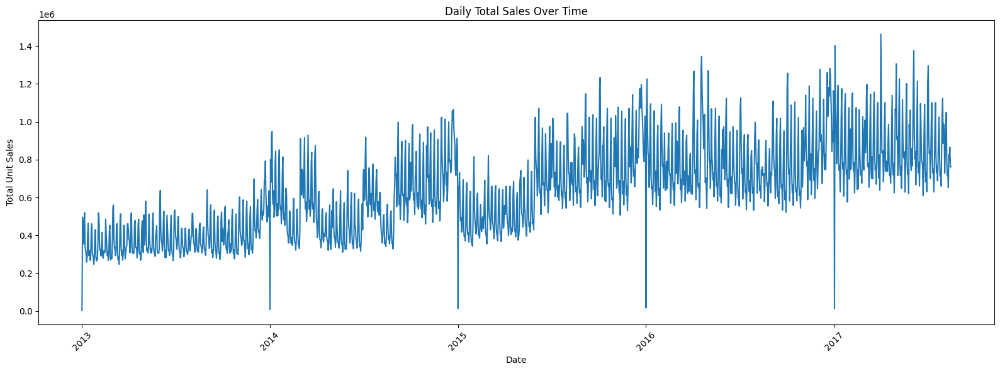

01. Daily Total Sales Over Time
   Saved: /kaggle/working/final_report_images/01_daily_sales_trend.png



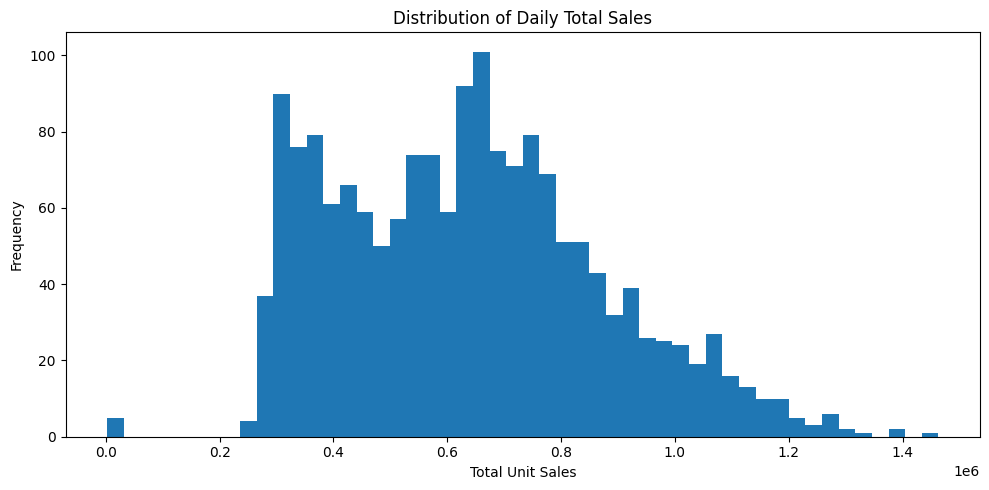

02. Distribution of Daily Total Sales
   Saved: /kaggle/working/final_report_images/02_daily_sales_distribution.png



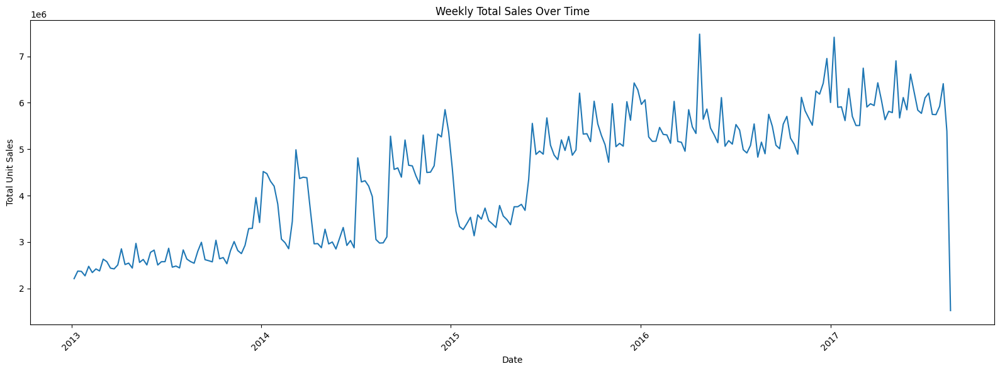

03. Weekly Total Sales Over Time
   Saved: /kaggle/working/final_report_images/03_weekly_sales_trend.png



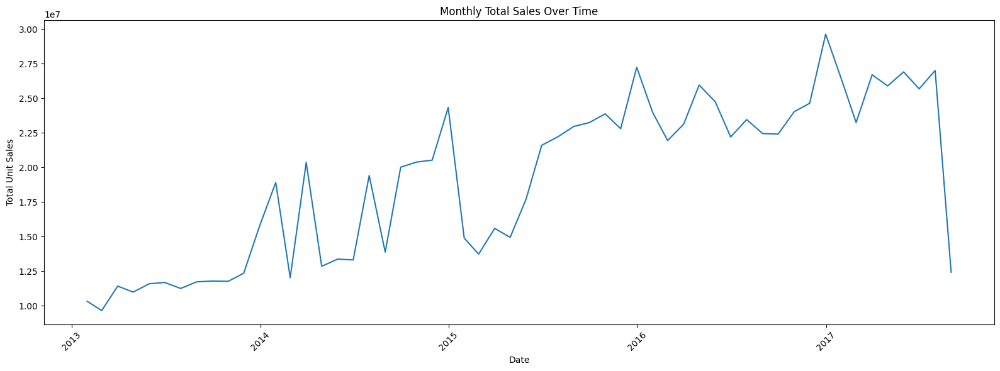

04. Monthly Total Sales Over Time
   Saved: /kaggle/working/final_report_images/04_monthly_sales_trend.png



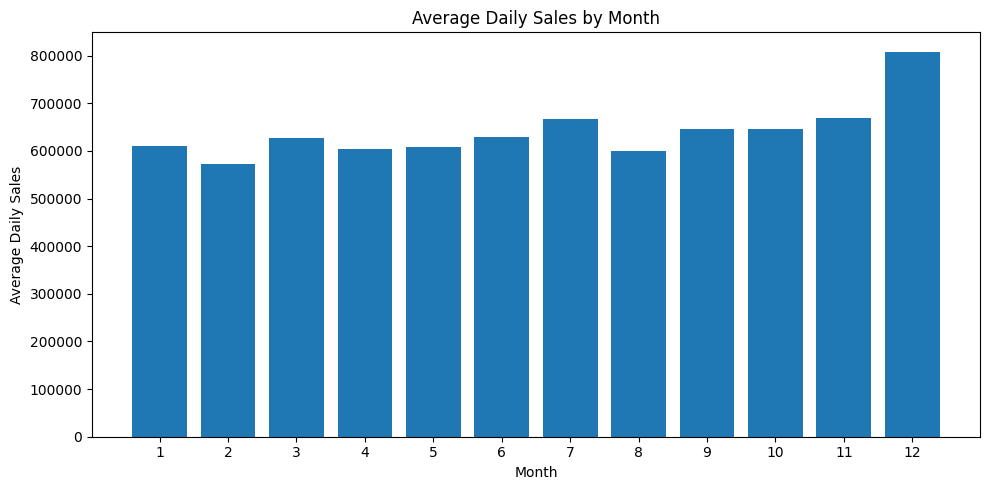

05. Average Daily Sales by Month
   Saved: /kaggle/working/final_report_images/05_average_sales_by_month.png



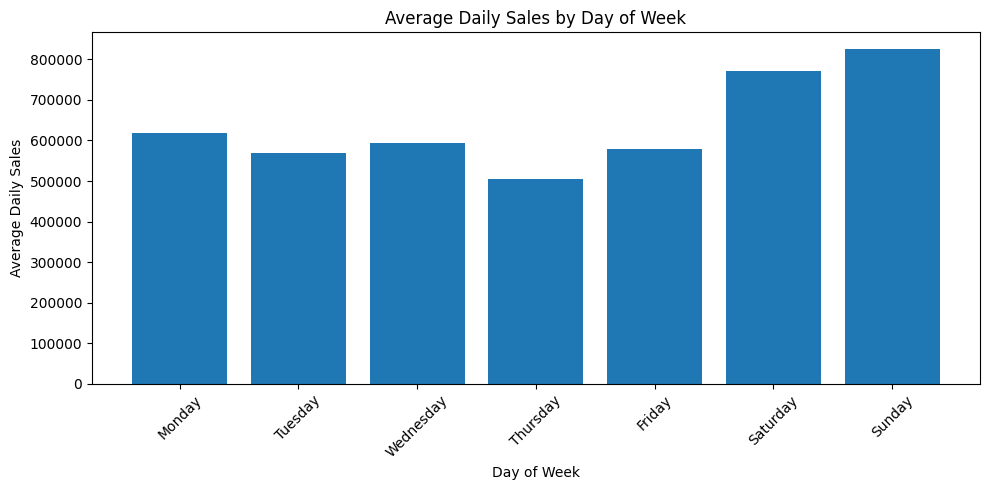

06. Average Daily Sales by Day of Week
   Saved: /kaggle/working/final_report_images/06_average_sales_by_day_of_week.png



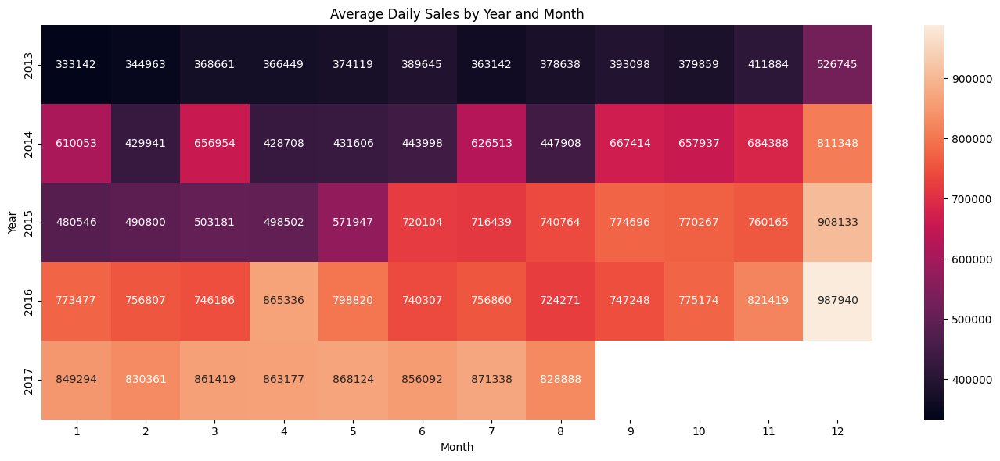

07. Year by Month Sales Heatmap
   Saved: /kaggle/working/final_report_images/07_year_month_sales_heatmap.png



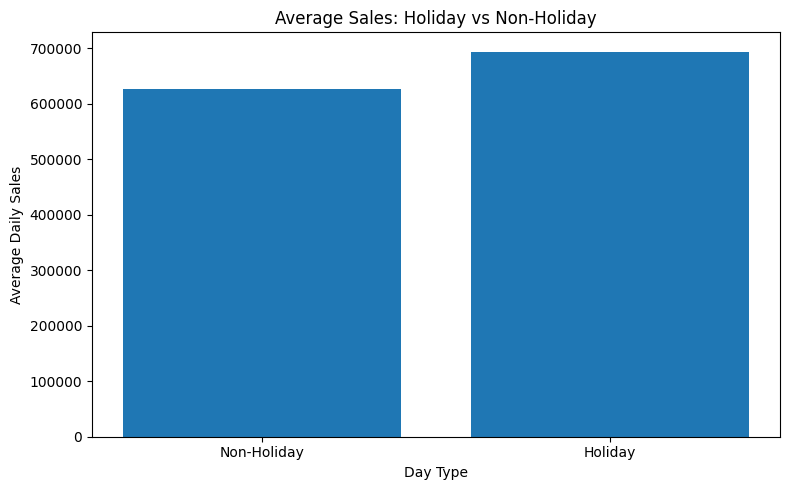

08. Holiday vs Non-Holiday Sales
   Saved: /kaggle/working/final_report_images/08_holiday_vs_nonholiday_sales.png



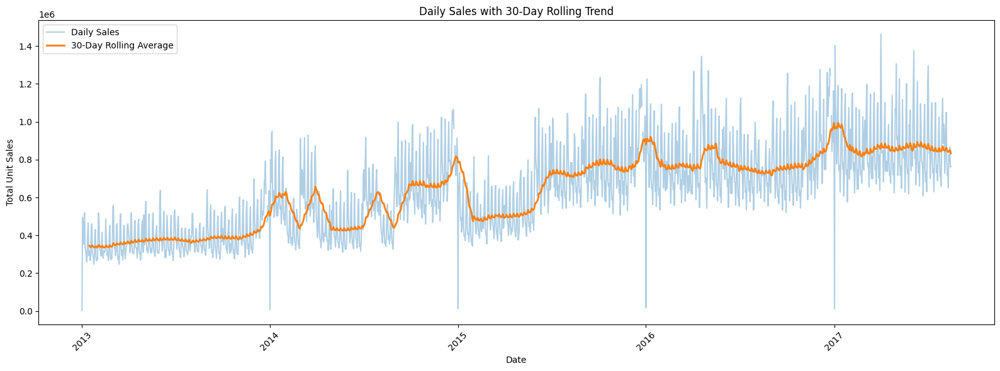

09. Daily Sales with 30-Day Rolling Trend
   Saved: /kaggle/working/final_report_images/09_daily_sales_30day_rolling.png



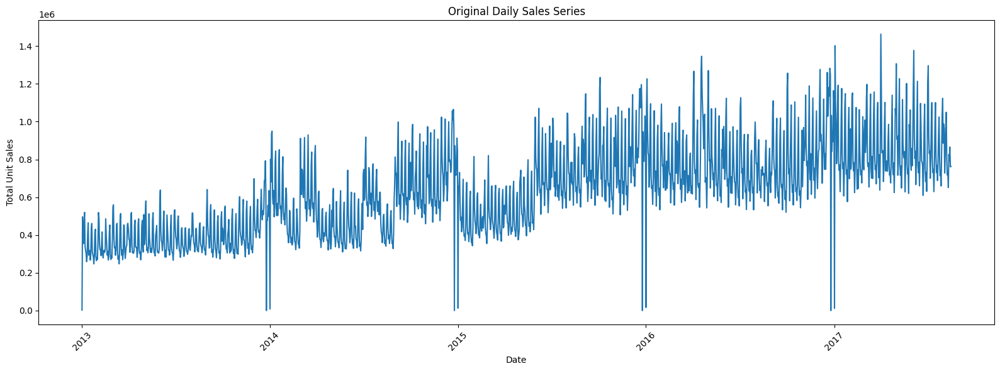

10. Original Daily Sales Series
   Saved: /kaggle/working/final_report_images/10_stationarity_original_series.png



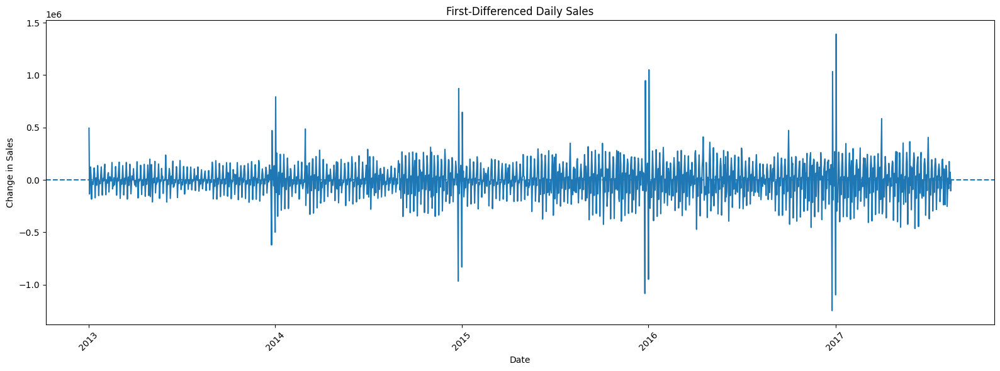

11. First-Differenced Daily Sales
   Saved: /kaggle/working/final_report_images/11_stationarity_first_difference.png



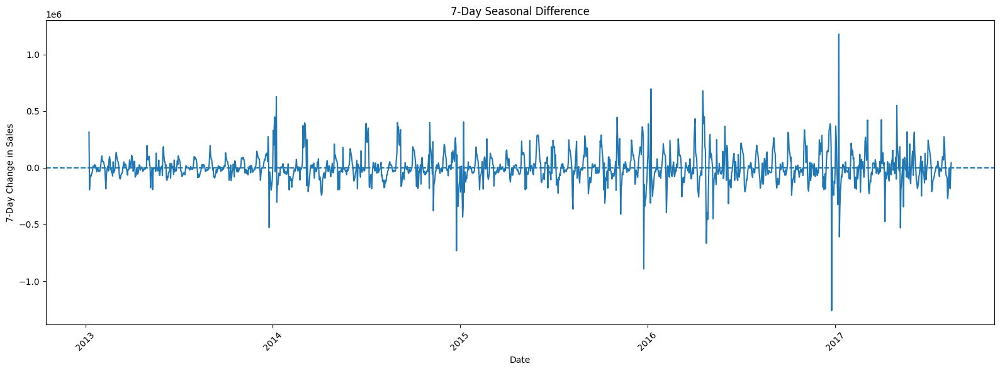

12. 7-Day Seasonal Difference
   Saved: /kaggle/working/final_report_images/12_stationarity_7day_difference.png



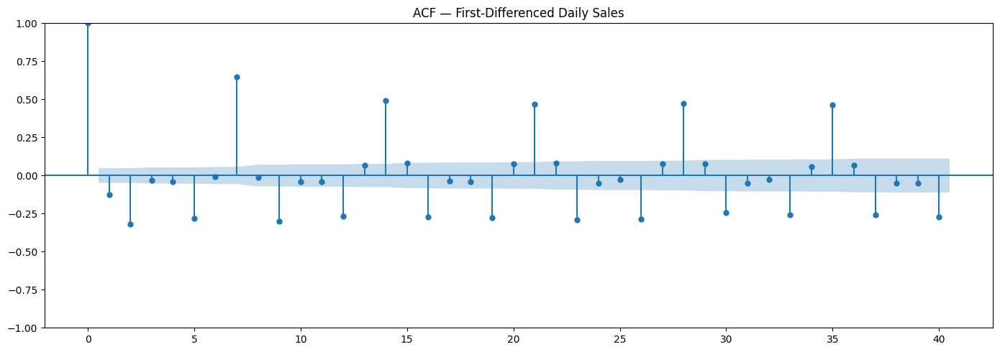

13. ACF Plot
   Saved: /kaggle/working/final_report_images/13_acf_first_difference.png



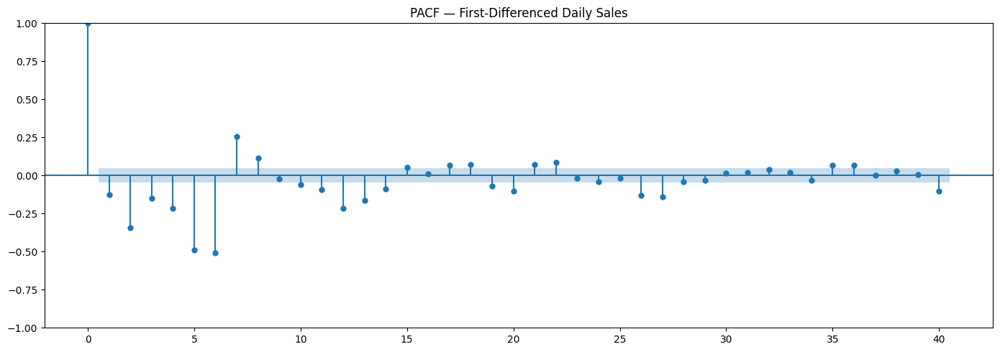

14. PACF Plot
   Saved: /kaggle/working/final_report_images/14_pacf_first_difference.png



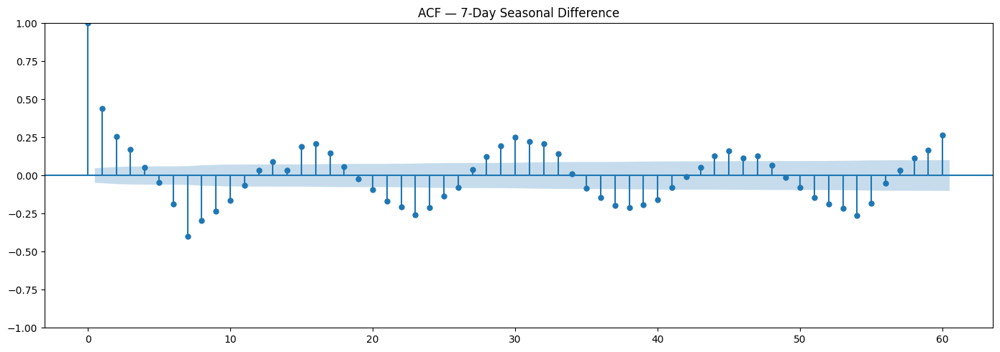

15. Seasonal ACF Plot
   Saved: /kaggle/working/final_report_images/15_acf_7day_difference.png



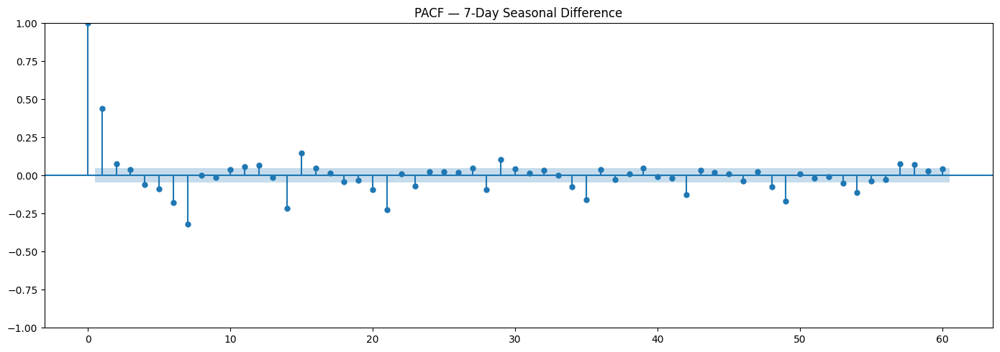

16. Seasonal PACF Plot
   Saved: /kaggle/working/final_report_images/16_pacf_7day_difference.png



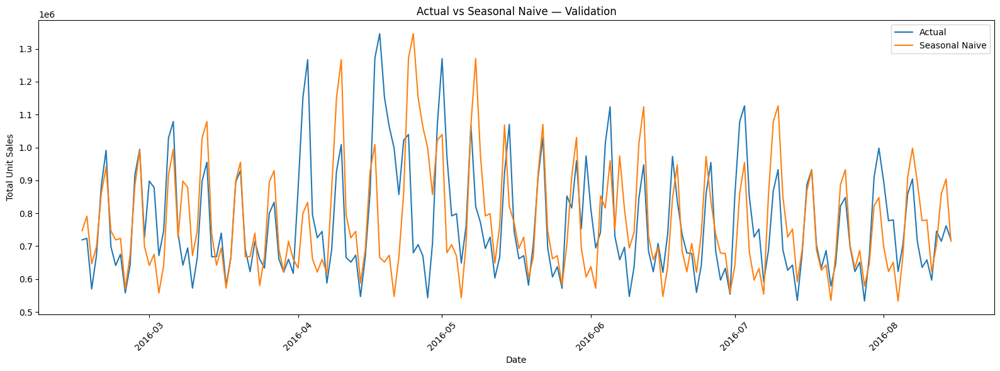

17. Actual vs Seasonal Naive — Validation
   Saved: /kaggle/working/final_report_images/17_validation_actual_vs_seasonal_naive.png



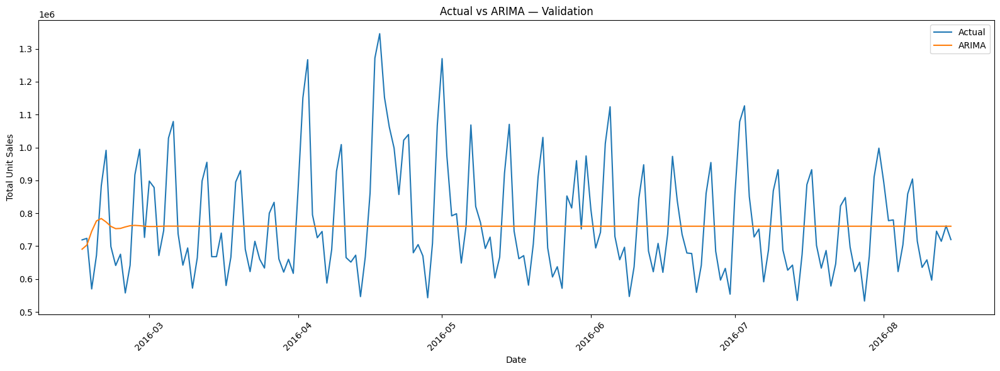

18. Actual vs ARIMA — Validation
   Saved: /kaggle/working/final_report_images/18_validation_actual_vs_arima.png



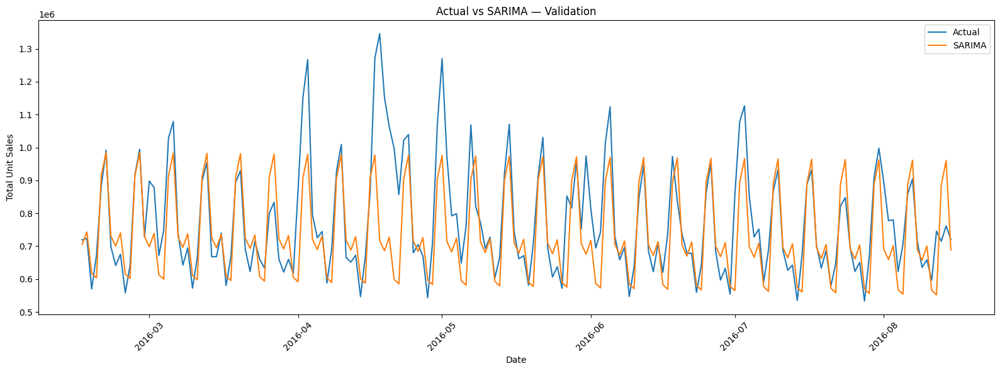

19. Actual vs SARIMA — Validation
   Saved: /kaggle/working/final_report_images/19_validation_actual_vs_sarima.png



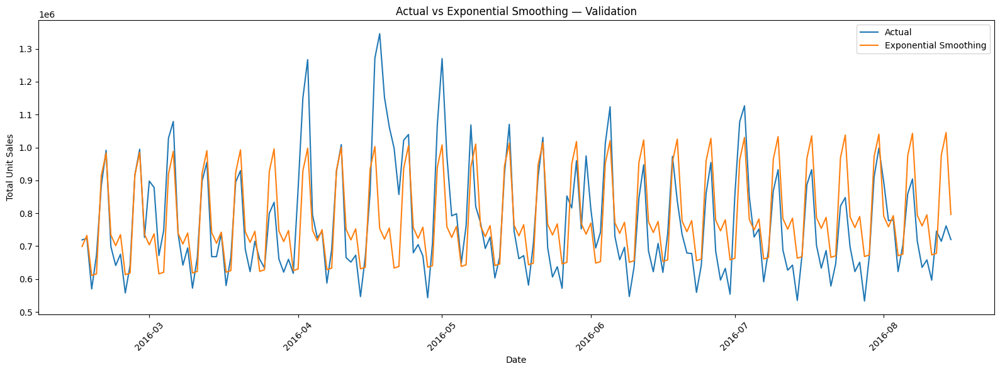

20. Actual vs Exponential Smoothing — Validation
   Saved: /kaggle/working/final_report_images/20_validation_actual_vs_exponential_smoothing.png



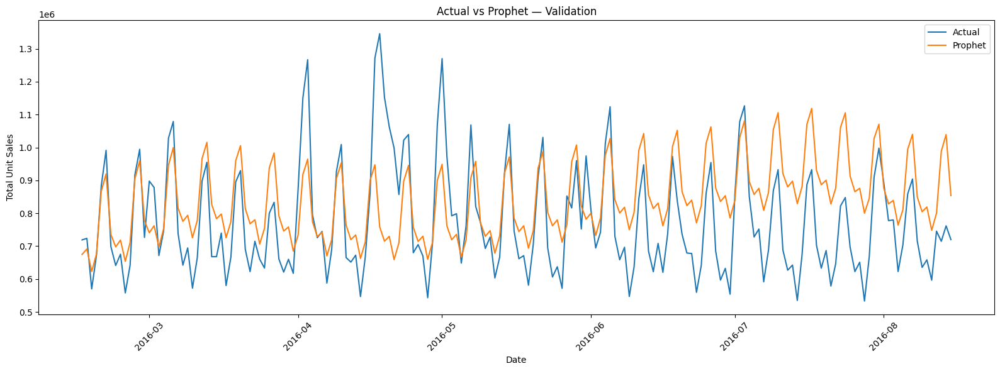

21. Actual vs Prophet — Validation
   Saved: /kaggle/working/final_report_images/21_validation_actual_vs_prophet.png



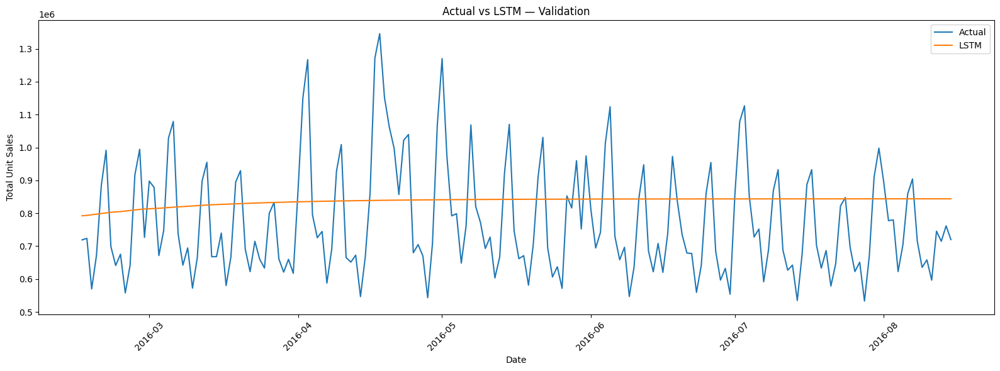

22. Actual vs LSTM — Validation
   Saved: /kaggle/working/final_report_images/22_validation_actual_vs_lstm.png



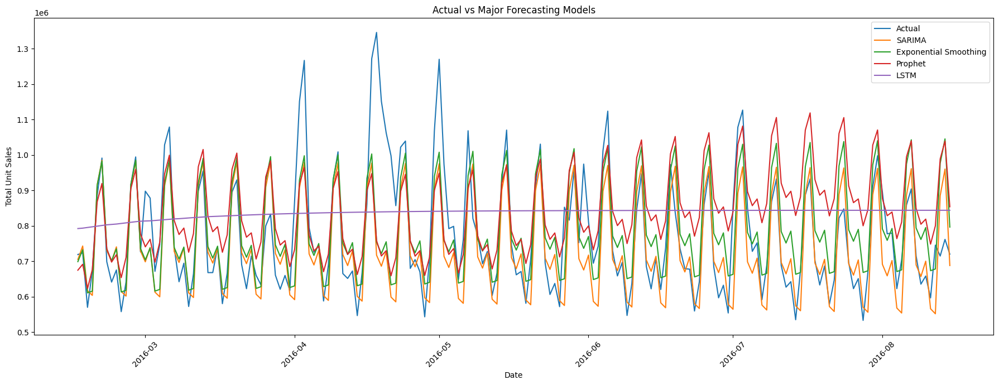

23. Actual vs SARIMA vs Exponential Smoothing vs Prophet vs LSTM
   Saved: /kaggle/working/final_report_images/23_validation_all_main_models.png



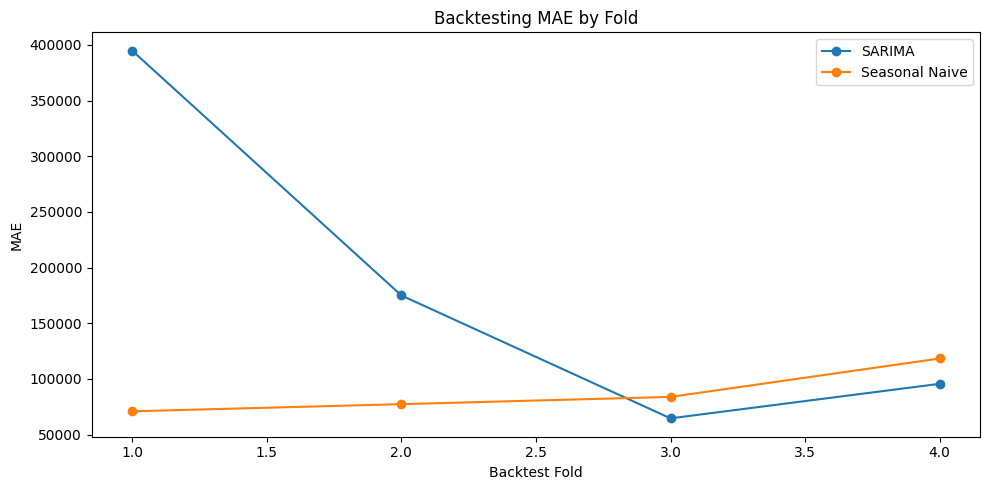

24. Backtesting MAE by Fold
   Saved: /kaggle/working/final_report_images/24_backtesting_mae_by_fold.png



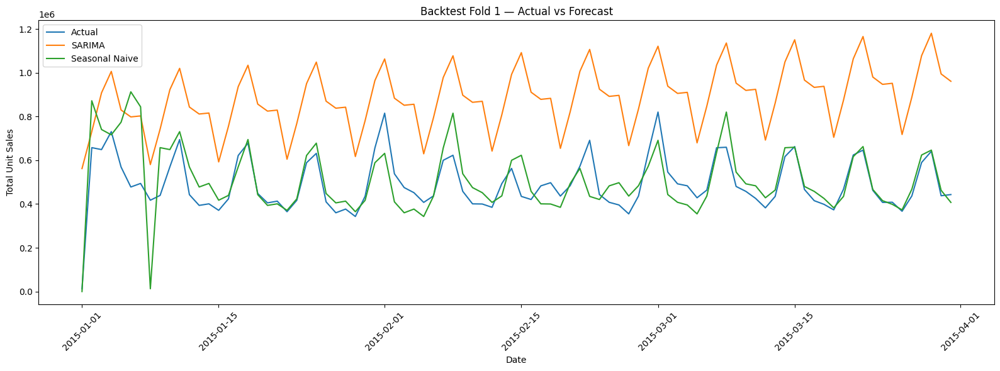

25. Backtest Fold 1 Actual vs Forecast
   Saved: /kaggle/working/final_report_images/25_backtest_fold1_actual_vs_forecast.png



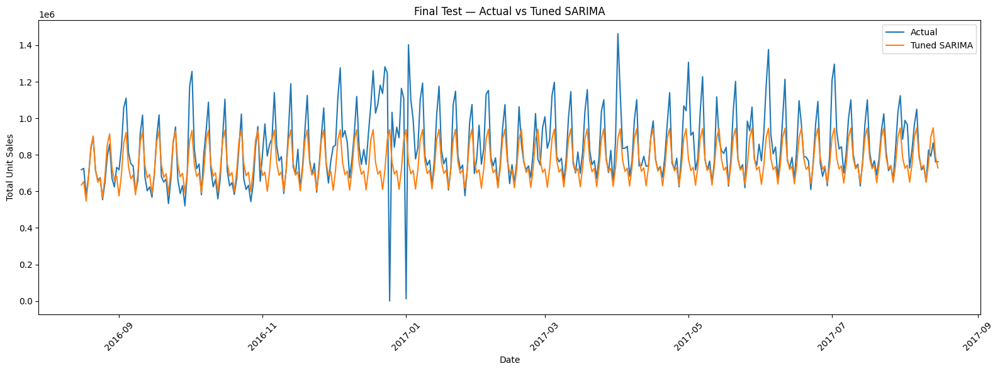

26. Final Test Actual vs Tuned SARIMA
   Saved: /kaggle/working/final_report_images/26_final_test_actual_vs_sarima.png



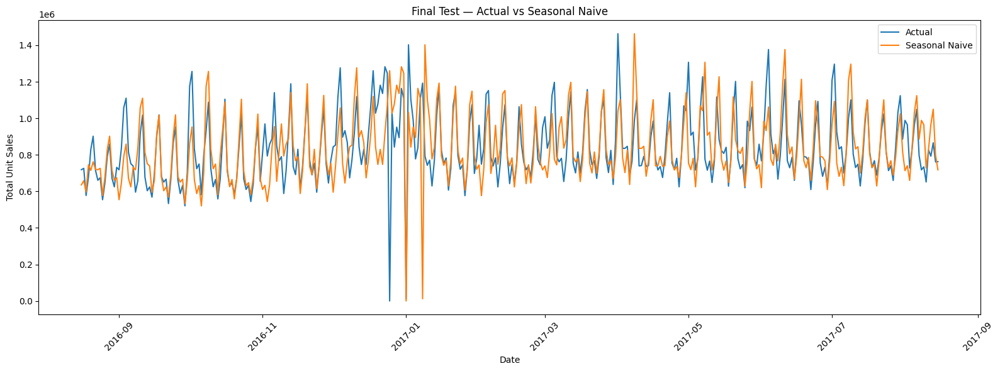

27. Final Test Actual vs Seasonal Naive
   Saved: /kaggle/working/final_report_images/27_final_test_actual_vs_seasonal_naive.png



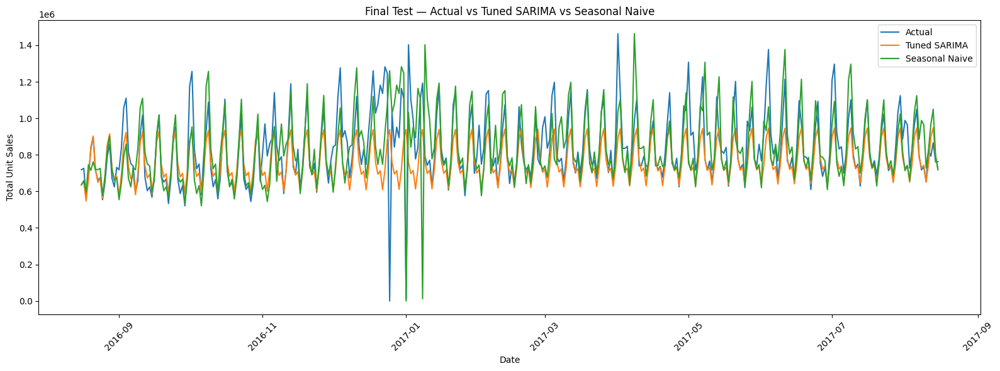

28. Final Test Actual vs Tuned SARIMA vs Seasonal Naive
   Saved: /kaggle/working/final_report_images/28_final_test_all_models.png



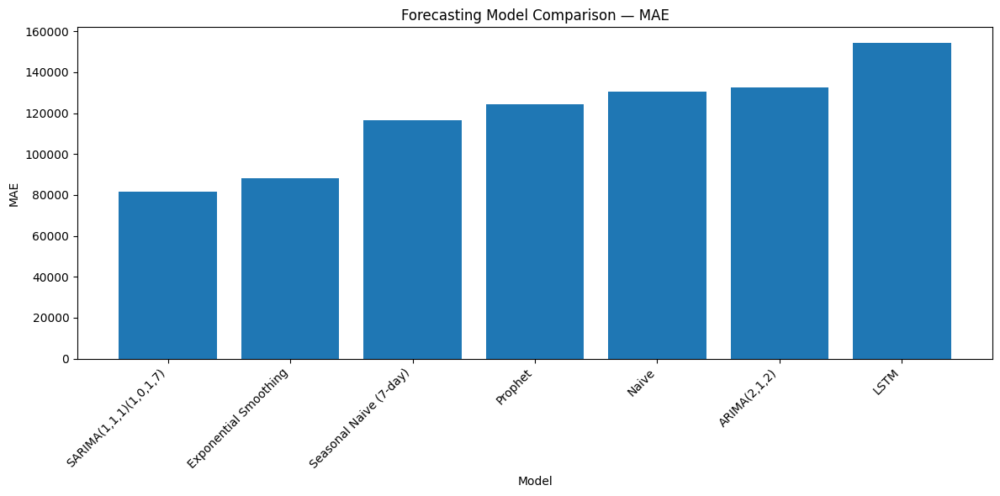

29. Forecasting Model Comparison — MAE
   Saved: /kaggle/working/final_report_images/29_model_comparison_mae.png



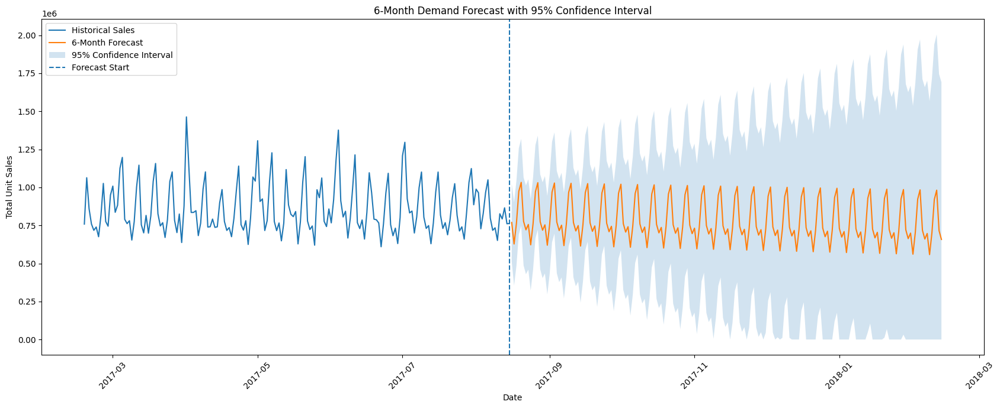

30. 6-Month Forecast with 95% Confidence Interval
   Saved: /kaggle/working/final_report_images/30_forecast_6_month_confidence_interval.png



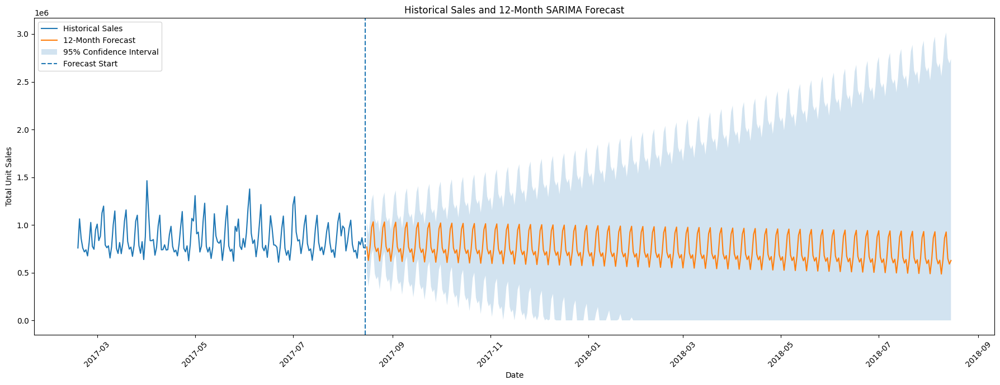

31. 12-Month Forecast with 95% Confidence Interval
   Saved: /kaggle/working/final_report_images/31_forecast_12_month_confidence_interval.png



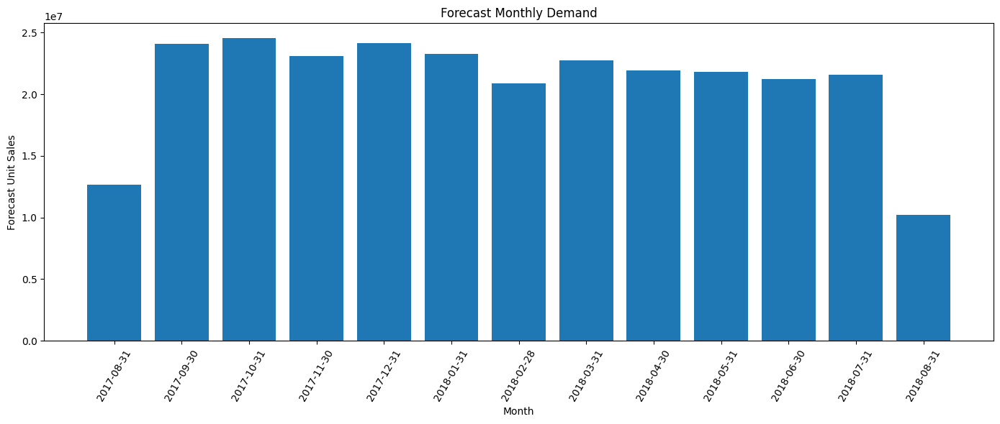

32. Forecast Monthly Demand
   Saved: /kaggle/working/final_report_images/32_monthly_forecast_demand.png



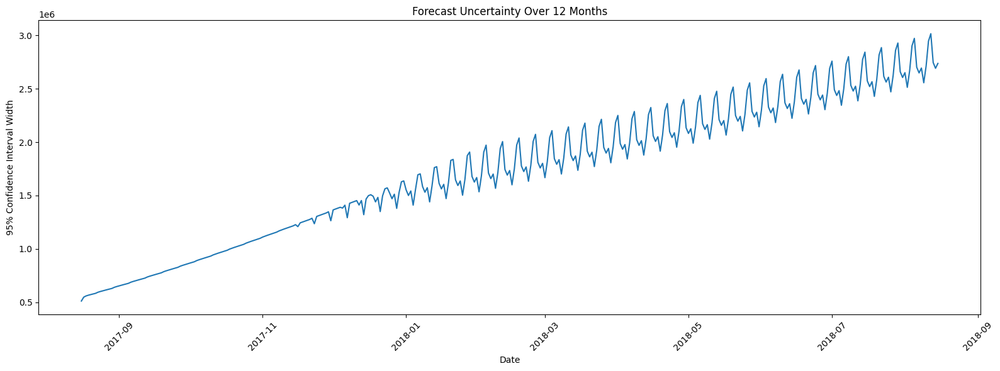

33. Forecast Uncertainty Over 12 Months
   Saved: /kaggle/working/final_report_images/33_forecast_uncertainty.png



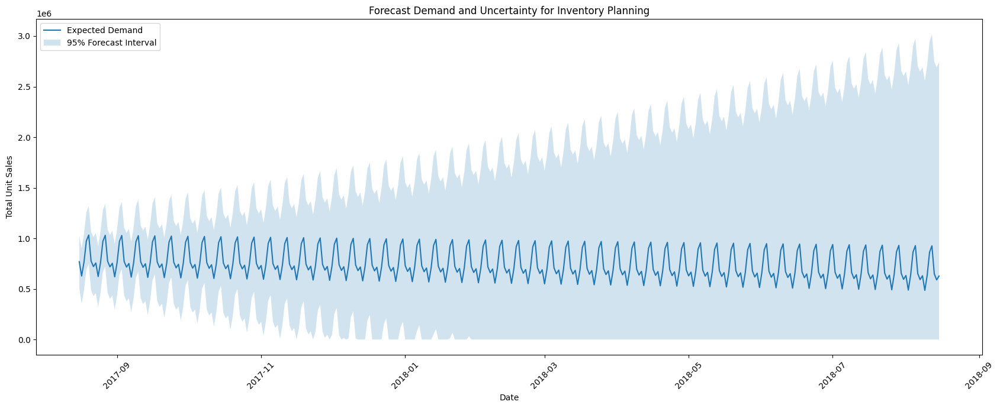

34. Forecast Demand and Uncertainty for Inventory Planning
   Saved: /kaggle/working/final_report_images/34_inventory_demand_uncertainty.png



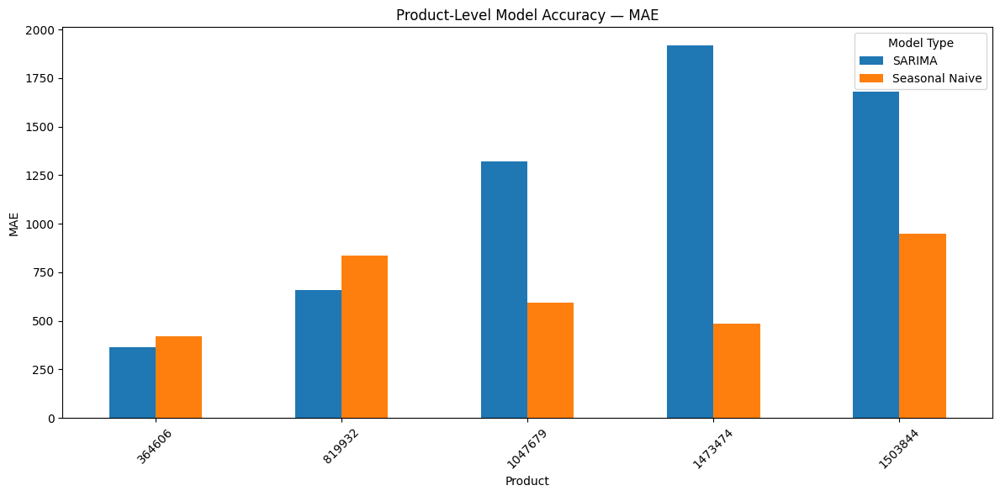

35. Product-Level Model Accuracy Comparison
   Saved: /kaggle/working/final_report_images/35_product_level_model_accuracy.png



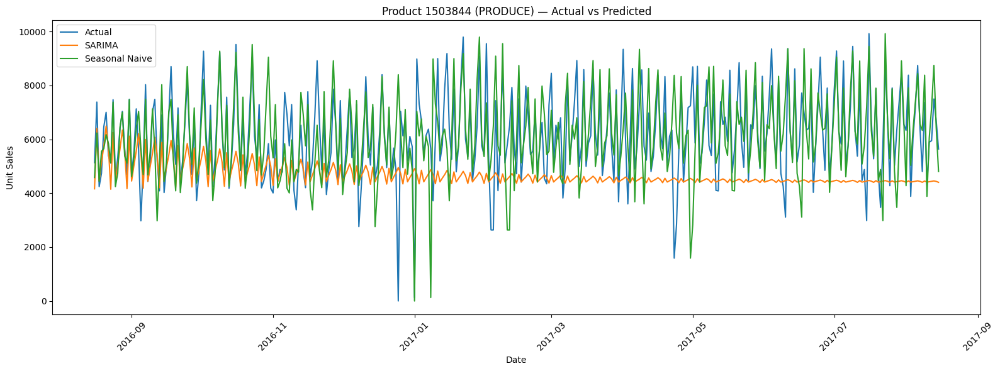

36. Product 1 — 1503844 Actual vs Predicted
   Saved: /kaggle/working/final_report_images/36_product_1_1503844_actual_vs_predicted.png



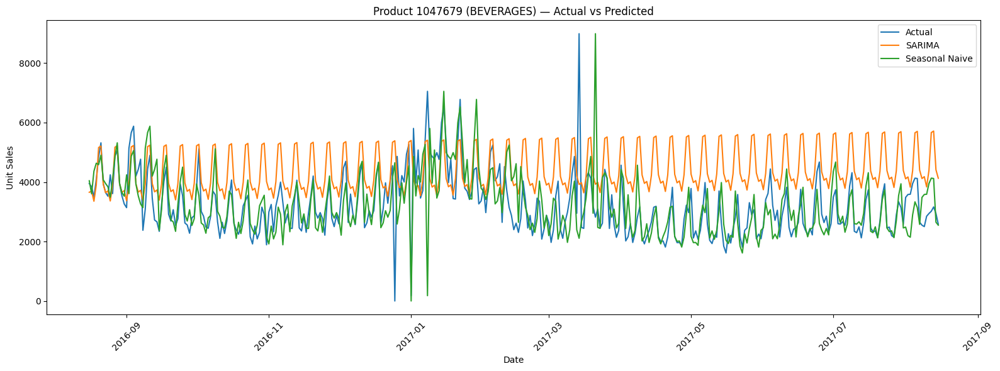

37. Product 2 — 1047679 Actual vs Predicted
   Saved: /kaggle/working/final_report_images/37_product_2_1047679_actual_vs_predicted.png



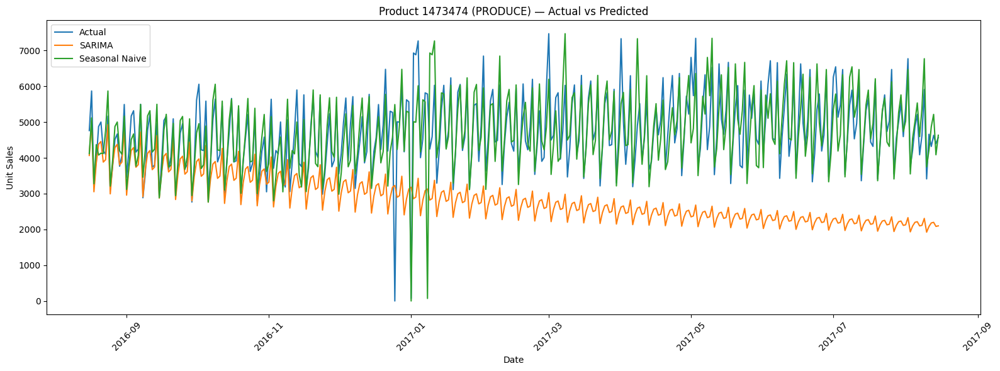

38. Product 3 — 1473474 Actual vs Predicted
   Saved: /kaggle/working/final_report_images/38_product_3_1473474_actual_vs_predicted.png



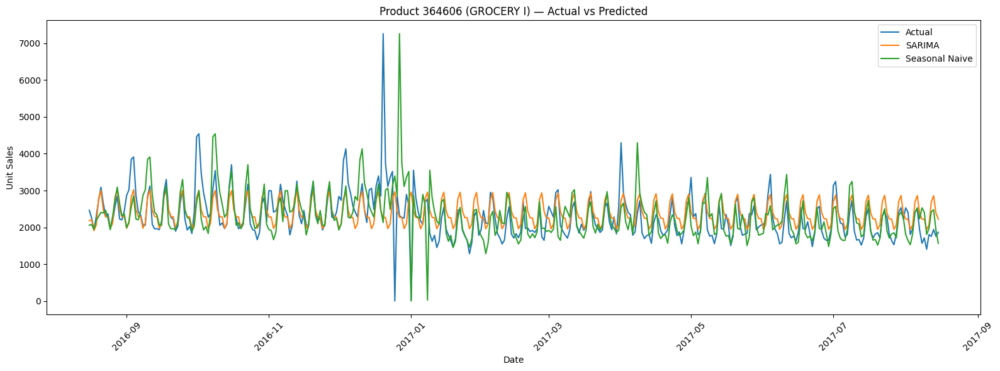

39. Product 4 — 364606 Actual vs Predicted
   Saved: /kaggle/working/final_report_images/39_product_4_364606_actual_vs_predicted.png



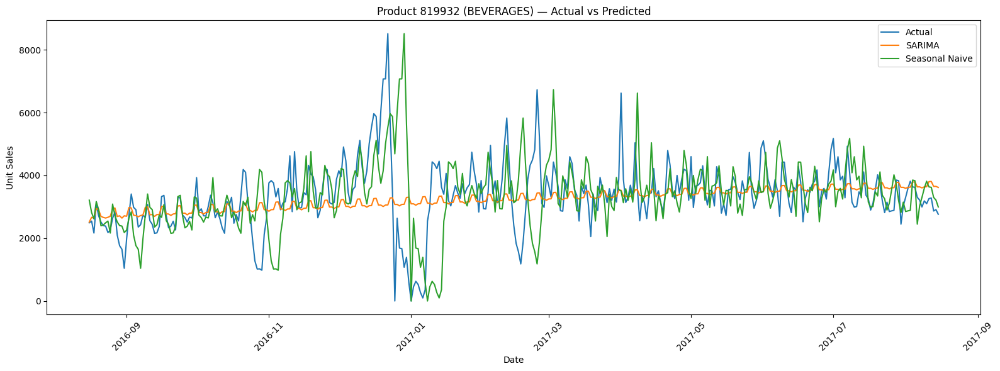

40. Product 5 — 819932 Actual vs Predicted
   Saved: /kaggle/working/final_report_images/40_product_5_819932_actual_vs_predicted.png

ALL REPORT IMAGES GENERATED

Total images generated: 40

Image folder:
/kaggle/working/final_report_images

Ordered image files:
/kaggle/working/final_report_images/01_daily_sales_trend.png
/kaggle/working/final_report_images/02_daily_sales_distribution.png
/kaggle/working/final_report_images/03_weekly_sales_trend.png
/kaggle/working/final_report_images/04_monthly_sales_trend.png
/kaggle/working/final_report_images/05_average_sales_by_month.png
/kaggle/working/final_report_images/06_average_sales_by_day_of_week.png
/kaggle/working/final_report_images/07_year_month_sales_heatmap.png
/kaggle/working/final_report_images/08_holiday_vs_nonholiday_sales.png
/kaggle/working/final_report_images/09_daily_sales_30day_rolling.png
/kaggle/working/final_report_images/10_stationarity_original_series.png
/kaggle/working/final_report_images/11_stationarity_first_differe

In [97]:
# ============================================================
# STEP 34 — GENERATE ALL REPORT IMAGES SEQUENTIALLY
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf


# ============================================================
# 1. IMAGE OUTPUT DIRECTORY
# ============================================================

image_dir = "/kaggle/working/final_report_images"

os.makedirs(
    image_dir,
    exist_ok=True
)

print("=" * 80)
print("FINAL REPORT IMAGE GENERATION")
print("=" * 80)
print(f"Images will be saved to:\n{image_dir}\n")


# ============================================================
# 2. HELPER FUNCTION
# ============================================================

image_counter = 0


def save_report_image(
    title,
    filename
):
    """
    Save current matplotlib figure with a sequential number.
    """

    global image_counter

    image_counter += 1

    numbered_filename = (
        f"{image_counter:02d}_{filename}"
    )

    output_path = os.path.join(
        image_dir,
        numbered_filename
    )

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"{image_counter:02d}. {title}"
    )

    print(
        f"   Saved: {output_path}\n"
    )

    plt.close()


# ============================================================
# 3. PREPARE COMMON DATA
# ============================================================

daily_features["date"] = pd.to_datetime(
    daily_features["date"]
)

forecast_df["date"] = pd.to_datetime(
    forecast_df["date"]
)

# Make sure required series exist
ts = (
    forecast_df
    .set_index("date")["total_sales"]
    .asfreq("D")
)

diff1 = ts.diff(1).dropna()

diff7 = ts.diff(7).dropna()


# ============================================================
# 4. IMAGE 01
# DAILY SALES TREND
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["total_sales"]
)

plt.title(
    "Daily Total Sales Over Time"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Daily Total Sales Over Time",
    "daily_sales_trend.png"
)


# ============================================================
# 5. IMAGE 02
# DAILY SALES DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    daily_sales["total_sales"],
    bins=50
)

plt.title(
    "Distribution of Daily Total Sales"
)

plt.xlabel("Total Unit Sales")
plt.ylabel("Frequency")

plt.tight_layout()

save_report_image(
    "Distribution of Daily Total Sales",
    "daily_sales_distribution.png"
)


# ============================================================
# 6. IMAGE 03
# WEEKLY SALES TREND
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    weekly_sales["date"],
    weekly_sales["total_sales"]
)

plt.title(
    "Weekly Total Sales Over Time"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Weekly Total Sales Over Time",
    "weekly_sales_trend.png"
)


# ============================================================
# 7. IMAGE 04
# MONTHLY SALES TREND
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_sales["date"],
    monthly_sales["total_sales"]
)

plt.title(
    "Monthly Total Sales Over Time"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Monthly Total Sales Over Time",
    "monthly_sales_trend.png"
)


# ============================================================
# 8. IMAGE 05
# AVERAGE SALES BY MONTH
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_pattern.index,
    monthly_pattern.values
)

plt.title(
    "Average Daily Sales by Month"
)

plt.xlabel("Month")
plt.ylabel("Average Daily Sales")

plt.xticks(
    range(1, 13)
)

plt.tight_layout()

save_report_image(
    "Average Daily Sales by Month",
    "average_sales_by_month.png"
)


# ============================================================
# 9. IMAGE 06
# AVERAGE SALES BY DAY OF WEEK
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    weekday_pattern["day_name"],
    weekday_pattern["total_sales"]
)

plt.title(
    "Average Daily Sales by Day of Week"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Daily Sales")

plt.xticks(
    rotation=45
)

plt.tight_layout()

save_report_image(
    "Average Daily Sales by Day of Week",
    "average_sales_by_day_of_week.png"
)


# ============================================================
# 10. IMAGE 07
# YEAR × MONTH HEATMAP
# ============================================================

plt.figure(figsize=(14, 6))

sns.heatmap(
    year_month_sales,
    annot=True,
    fmt=".0f"
)

plt.title(
    "Average Daily Sales by Year and Month"
)

plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()

save_report_image(
    "Year by Month Sales Heatmap",
    "year_month_sales_heatmap.png"
)


# ============================================================
# 11. IMAGE 08
# HOLIDAY VS NON-HOLIDAY
# ============================================================

holiday_plot = (
    daily_features
    .dropna(subset=["total_sales"])
    .groupby("is_holiday")["total_sales"]
    .mean()
)

holiday_labels = [
    "Non-Holiday",
    "Holiday"
]

holiday_values = [
    holiday_plot.get(0, 0),
    holiday_plot.get(1, 0)
]

plt.figure(figsize=(8, 5))

plt.bar(
    holiday_labels,
    holiday_values
)

plt.title(
    "Average Sales: Holiday vs Non-Holiday"
)

plt.xlabel("Day Type")
plt.ylabel("Average Daily Sales")

plt.tight_layout()

save_report_image(
    "Holiday vs Non-Holiday Sales",
    "holiday_vs_nonholiday_sales.png"
)


# ============================================================
# 12. IMAGE 09
# DAILY SALES + ROLLING TREND
# ============================================================

daily_plot = daily_features.copy()

daily_plot["rolling_30d"] = (
    daily_plot["total_sales"]
    .rolling(
        window=30,
        min_periods=15
    )
    .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(
    daily_plot["date"],
    daily_plot["total_sales"],
    alpha=0.35,
    label="Daily Sales"
)

plt.plot(
    daily_plot["date"],
    daily_plot["rolling_30d"],
    linewidth=2,
    label="30-Day Rolling Average"
)

plt.title(
    "Daily Sales with 30-Day Rolling Trend"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Daily Sales with 30-Day Rolling Trend",
    "daily_sales_30day_rolling.png"
)


# ============================================================
# 13. IMAGE 10
# STATIONARITY — ORIGINAL
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    ts.index,
    ts.values
)

plt.title(
    "Original Daily Sales Series"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Original Daily Sales Series",
    "stationarity_original_series.png"
)


# ============================================================
# 14. IMAGE 11
# FIRST DIFFERENCE
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    diff1.index,
    diff1.values
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "First-Differenced Daily Sales"
)

plt.xlabel("Date")
plt.ylabel("Change in Sales")

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "First-Differenced Daily Sales",
    "stationarity_first_difference.png"
)


# ============================================================
# 15. IMAGE 12
# 7-DAY DIFFERENCE
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    diff7.index,
    diff7.values
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "7-Day Seasonal Difference"
)

plt.xlabel("Date")
plt.ylabel("7-Day Change in Sales")

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "7-Day Seasonal Difference",
    "stationarity_7day_difference.png"
)


# ============================================================
# 16. IMAGE 13
# ACF
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 5)
)

plot_acf(
    diff1,
    lags=40,
    ax=ax
)

ax.set_title(
    "ACF — First-Differenced Daily Sales"
)

plt.tight_layout()

save_report_image(
    "ACF Plot",
    "acf_first_difference.png"
)


# ============================================================
# 17. IMAGE 14
# PACF
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 5)
)

plot_pacf(
    diff1,
    lags=40,
    method="ywm",
    ax=ax
)

ax.set_title(
    "PACF — First-Differenced Daily Sales"
)

plt.tight_layout()

save_report_image(
    "PACF Plot",
    "pacf_first_difference.png"
)


# ============================================================
# 18. IMAGE 15
# SEASONAL ACF
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 5)
)

plot_acf(
    diff7,
    lags=60,
    ax=ax
)

ax.set_title(
    "ACF — 7-Day Seasonal Difference"
)

plt.tight_layout()

save_report_image(
    "Seasonal ACF Plot",
    "acf_7day_difference.png"
)


# ============================================================
# 19. IMAGE 16
# SEASONAL PACF
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 5)
)

plot_pacf(
    diff7,
    lags=60,
    method="ywm",
    ax=ax
)

ax.set_title(
    "PACF — 7-Day Seasonal Difference"
)

plt.tight_layout()

save_report_image(
    "Seasonal PACF Plot",
    "pacf_7day_difference.png"
)


# ============================================================
# 20. IMAGE 17
# VALIDATION — SEASONAL NAIVE
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    seasonal_naive_predictions.values,
    label="Seasonal Naive"
)

plt.title(
    "Actual vs Seasonal Naive — Validation"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Actual vs Seasonal Naive — Validation",
    "validation_actual_vs_seasonal_naive.png"
)


# ============================================================
# 21. IMAGE 18
# VALIDATION — ARIMA
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    arima_predictions.values,
    label="ARIMA"
)

plt.title(
    "Actual vs ARIMA — Validation"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Actual vs ARIMA — Validation",
    "validation_actual_vs_arima.png"
)


# ============================================================
# 22. IMAGE 19
# VALIDATION — SARIMA
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    sarima_predictions.values,
    label="SARIMA"
)

plt.title(
    "Actual vs SARIMA — Validation"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Actual vs SARIMA — Validation",
    "validation_actual_vs_sarima.png"
)


# ============================================================
# 23. IMAGE 20
# VALIDATION — EXPONENTIAL SMOOTHING
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    exp_predictions.values,
    label="Exponential Smoothing"
)

plt.title(
    "Actual vs Exponential Smoothing — Validation"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Actual vs Exponential Smoothing — Validation",
    "validation_actual_vs_exponential_smoothing.png"
)


# ============================================================
# 24. IMAGE 21
# VALIDATION — PROPHET
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    prophet_predictions.values,
    label="Prophet"
)

plt.title(
    "Actual vs Prophet — Validation"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Actual vs Prophet — Validation",
    "validation_actual_vs_prophet.png"
)


# ============================================================
# 25. IMAGE 22
# VALIDATION — LSTM
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    lstm_predictions.values,
    label="LSTM"
)

plt.title(
    "Actual vs LSTM — Validation"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Actual vs LSTM — Validation",
    "validation_actual_vs_lstm.png"
)


# ============================================================
# 26. IMAGE 23
# VALIDATION — MAIN MODELS TOGETHER
# ============================================================

plt.figure(figsize=(18, 7))

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Actual"
)

plt.plot(
    validation_ts.index,
    sarima_predictions.values,
    label="SARIMA"
)

plt.plot(
    validation_ts.index,
    exp_predictions.values,
    label="Exponential Smoothing"
)

plt.plot(
    validation_ts.index,
    prophet_predictions.values,
    label="Prophet"
)

plt.plot(
    validation_ts.index,
    lstm_predictions.values,
    label="LSTM"
)

plt.title(
    "Actual vs Major Forecasting Models"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Actual vs SARIMA vs Exponential Smoothing vs Prophet vs LSTM",
    "validation_all_main_models.png"
)


# ============================================================
# 27. IMAGE 24
# BACKTEST MAE BY FOLD
# ============================================================

sarima_fold_results = (
    backtest_results_df[
        backtest_results_df["Model Type"] == "SARIMA"
    ]
)

seasonal_fold_results = (
    backtest_results_df[
        backtest_results_df["Model Type"] == "Seasonal Naive"
    ]
)

plt.figure(figsize=(10, 5))

plt.plot(
    sarima_fold_results["Fold"],
    sarima_fold_results["MAE"],
    marker="o",
    label="SARIMA"
)

plt.plot(
    seasonal_fold_results["Fold"],
    seasonal_fold_results["MAE"],
    marker="o",
    label="Seasonal Naive"
)

plt.title(
    "Backtesting MAE by Fold"
)

plt.xlabel("Backtest Fold")
plt.ylabel("MAE")

plt.legend()

plt.tight_layout()

save_report_image(
    "Backtesting MAE by Fold",
    "backtesting_mae_by_fold.png"
)


# ============================================================
# 28. IMAGE 25
# BACKTEST FOLD 1
# ============================================================

first_fold = (
    backtest_predictions_df[
        backtest_predictions_df["fold"] == 1
    ]
)

plt.figure(figsize=(16, 6))

plt.plot(
    first_fold["date"],
    first_fold["actual"],
    label="Actual"
)

plt.plot(
    first_fold["date"],
    first_fold["sarima_prediction"],
    label="SARIMA"
)

plt.plot(
    first_fold["date"],
    first_fold["seasonal_naive_prediction"],
    label="Seasonal Naive"
)

plt.title(
    "Backtest Fold 1 — Actual vs Forecast"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Backtest Fold 1 Actual vs Forecast",
    "backtest_fold1_actual_vs_forecast.png"
)


# ============================================================
# 29. IMAGE 26
# FINAL TEST — TUNED SARIMA
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    test_ts.index,
    test_ts.values,
    label="Actual"
)

plt.plot(
    test_predictions.index,
    test_predictions.values,
    label="Tuned SARIMA"
)

plt.title(
    "Final Test — Actual vs Tuned SARIMA"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Final Test Actual vs Tuned SARIMA",
    "final_test_actual_vs_sarima.png"
)


# ============================================================
# 30. IMAGE 27
# FINAL TEST — SEASONAL NAIVE
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    test_ts.index,
    test_ts.values,
    label="Actual"
)

plt.plot(
    seasonal_naive_test_predictions.index,
    seasonal_naive_test_predictions.values,
    label="Seasonal Naive"
)

plt.title(
    "Final Test — Actual vs Seasonal Naive"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Final Test Actual vs Seasonal Naive",
    "final_test_actual_vs_seasonal_naive.png"
)


# ============================================================
# 31. IMAGE 28
# FINAL TEST — BOTH MODELS
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    test_ts.index,
    test_ts.values,
    label="Actual"
)

plt.plot(
    test_predictions.index,
    test_predictions.values,
    label="Tuned SARIMA"
)

plt.plot(
    seasonal_naive_test_predictions.index,
    seasonal_naive_test_predictions.values,
    label="Seasonal Naive"
)

plt.title(
    "Final Test — Actual vs Tuned SARIMA vs Seasonal Naive"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Final Test Actual vs Tuned SARIMA vs Seasonal Naive",
    "final_test_all_models.png"
)


# ============================================================
# 32. IMAGE 29
# MODEL MAE COMPARISON
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["MAE"]
)

plt.title(
    "Forecasting Model Comparison — MAE"
)

plt.xlabel("Model")
plt.ylabel("MAE")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

save_report_image(
    "Forecasting Model Comparison — MAE",
    "model_comparison_mae.png"
)


# ============================================================
# 33. IMAGE 30
# FINAL 6-MONTH FORECAST
# ============================================================

recent_history = final_series.tail(180)

plt.figure(figsize=(17, 7))

plt.plot(
    recent_history.index,
    recent_history.values,
    label="Historical Sales"
)

plt.plot(
    forecast_6m.index,
    forecast_6m["forecast"],
    label="6-Month Forecast"
)

plt.fill_between(
    forecast_6m.index,
    forecast_6m["lower_95_inventory"],
    forecast_6m["upper_95_inventory"],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.axvline(
    final_series.index.max(),
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    "6-Month Demand Forecast with 95% Confidence Interval"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "6-Month Forecast with 95% Confidence Interval",
    "forecast_6_month_confidence_interval.png"
)


# ============================================================
# 34. IMAGE 31
# FINAL 12-MONTH FORECAST
# ============================================================

plt.figure(figsize=(18, 7))

plt.plot(
    recent_history.index,
    recent_history.values,
    label="Historical Sales"
)

plt.plot(
    forecast_output.index,
    forecast_output["forecast"],
    label="12-Month Forecast"
)

plt.fill_between(
    forecast_output.index,
    forecast_output["lower_95_inventory"],
    forecast_output["upper_95_inventory"],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.axvline(
    final_series.index.max(),
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    "Historical Sales and 12-Month SARIMA Forecast"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "12-Month Forecast with 95% Confidence Interval",
    "forecast_12_month_confidence_interval.png"
)


# ============================================================
# 35. IMAGE 32
# MONTHLY FORECAST
# ============================================================

plt.figure(figsize=(14, 6))

plt.bar(
    monthly_forecast["date"].astype(str),
    monthly_forecast["forecast_units"]
)

plt.title(
    "Forecast Monthly Demand"
)

plt.xlabel("Month")
plt.ylabel("Forecast Unit Sales")

plt.xticks(
    rotation=60
)

plt.tight_layout()

save_report_image(
    "Forecast Monthly Demand",
    "monthly_forecast_demand.png"
)


# ============================================================
# 36. IMAGE 33
# FORECAST UNCERTAINTY
# ============================================================

forecast_interval_width = (
    forecast_output["upper_95_inventory"]
    -
    forecast_output["lower_95_inventory"]
)

plt.figure(figsize=(16, 6))

plt.plot(
    forecast_output.index,
    forecast_interval_width
)

plt.title(
    "Forecast Uncertainty Over 12 Months"
)

plt.xlabel("Date")
plt.ylabel("95% Confidence Interval Width")

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Forecast Uncertainty Over 12 Months",
    "forecast_uncertainty.png"
)


# ============================================================
# 37. IMAGE 34
# INVENTORY PLANNING UNCERTAINTY
# ============================================================

plt.figure(figsize=(17, 7))

plt.plot(
    inventory_df.index,
    inventory_df["forecast"],
    label="Expected Demand"
)

plt.fill_between(
    inventory_df.index,
    inventory_df["lower_95"],
    inventory_df["upper_95"],
    alpha=0.2,
    label="95% Forecast Interval"
)

plt.title(
    "Forecast Demand and Uncertainty for Inventory Planning"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

save_report_image(
    "Forecast Demand and Uncertainty for Inventory Planning",
    "inventory_demand_uncertainty.png"
)


# ============================================================
# 38. IMAGE 35
# PRODUCT-LEVEL MODEL ACCURACY
# ============================================================

product_plot_data = (
    product_accuracy[
        [
            "item_nbr",
            "Model",
            "MAE"
        ]
    ]
    .copy()
)

product_plot_data["Model Type"] = (
    product_plot_data["Model"]
    .str.replace(
        r" - \d+",
        "",
        regex=True
    )
)

product_mae_pivot = (
    product_plot_data
    .pivot(
        index="item_nbr",
        columns="Model Type",
        values="MAE"
    )
)

plt.figure(figsize=(12, 6))

product_mae_pivot.plot(
    kind="bar",
    ax=plt.gca()
)

plt.title(
    "Product-Level Model Accuracy — MAE"
)

plt.xlabel("Product")
plt.ylabel("MAE")

plt.xticks(
    rotation=45
)

plt.tight_layout()

save_report_image(
    "Product-Level Model Accuracy Comparison",
    "product_level_model_accuracy.png"
)


# ============================================================
# 39. IMAGES 36–40
# PRODUCT-LEVEL ACTUAL VS PREDICTED
# ============================================================

for product_number, item_id in enumerate(
    top_product_ids,
    start=1
):

    if item_id not in product_predictions:
        continue

    result = product_predictions[item_id]

    try:

        family = (
            top_5_products
            .loc[
                top_5_products["item_nbr"] == item_id,
                "family"
            ]
            .iloc[0]
        )

    except Exception:

        family = "Unknown"


    plt.figure(figsize=(16, 6))

    plt.plot(
        result["actual"].index,
        result["actual"].values,
        label="Actual"
    )

    plt.plot(
        result["sarima"].index,
        result["sarima"].values,
        label="SARIMA"
    )

    plt.plot(
        result["seasonal_naive"].index,
        result["seasonal_naive"].values,
        label="Seasonal Naive"
    )

    plt.title(
        f"Product {item_id} ({family}) — "
        "Actual vs Predicted"
    )

    plt.xlabel("Date")
    plt.ylabel("Unit Sales")

    plt.legend()

    plt.xticks(rotation=45)

    plt.tight_layout()

    save_report_image(
        f"Product {product_number} — "
        f"{item_id} Actual vs Predicted",
        f"product_{product_number}_{item_id}_actual_vs_predicted.png"
    )


# ============================================================
# 40. FINAL IMAGE LIST
# ============================================================

print("=" * 80)
print("ALL REPORT IMAGES GENERATED")
print("=" * 80)

print(
    f"\nTotal images generated: "
    f"{image_counter}"
)

print(
    f"\nImage folder:\n{image_dir}"
)

print("\nOrdered image files:")

for filename in sorted(
    os.listdir(image_dir)
):

    print(
        os.path.join(
            image_dir,
            filename
        )
    )

In [98]:
# ============================================================
# STEP 35 — CREATE ONE SELF-CONTAINED REPORT FILE
# ============================================================
#
# Output:
# /kaggle/working/Favorita_Demand_Forecasting_Final_Report.html
#
# This HTML contains:
#   - Full Markdown report
#   - All generated plots embedded inside the file
#   - No dependency on separate image files
#
# You can:
#   1. Open the HTML in a browser
#   2. Review the complete report
#   3. Print / Save as PDF
#
# ============================================================

from pathlib import Path
import base64
import re
import html


# ============================================================
# 1. PATHS
# ============================================================

report_md_path = Path(
    "/kaggle/working/Favorita_Demand_Forecasting_Report.md"
)

image_dir = Path(
    "/kaggle/working/final_report_images"
)

output_html_path = Path(
    "/kaggle/working/"
    "Favorita_Demand_Forecasting_Final_Report.html"
)


# ============================================================
# 2. CHECK FILES
# ============================================================

if not report_md_path.exists():
    raise FileNotFoundError(
        f"Report not found:\n{report_md_path}"
    )

if not image_dir.exists():
    raise FileNotFoundError(
        f"Image directory not found:\n{image_dir}"
    )


# ============================================================
# 3. READ MARKDOWN REPORT
# ============================================================

markdown_text = report_md_path.read_text(
    encoding="utf-8"
)


# ============================================================
# 4. IMAGE FILE LIST
# ============================================================

image_files = sorted(
    image_dir.glob("*.png")
)

print("=" * 80)
print("REPORT + IMAGE COMBINER")
print("=" * 80)

print(
    f"\nMarkdown report:\n{report_md_path}"
)

print(
    f"\nImages found: {len(image_files)}"
)

for image in image_files:
    print(
        " -",
        image.name
    )


# ============================================================
# 5. MAP REPORT PLACEHOLDERS TO IMAGE FILES
# ============================================================

image_map = {

    # --------------------------------------------------------
    # EDA
    # --------------------------------------------------------

    "Daily Total Sales Over Time":
        "01_daily_sales_trend.png",

    "Distribution of Daily Total Sales":
        "02_daily_sales_distribution.png",

    "Weekly Total Sales Over Time":
        "03_weekly_sales_trend.png",

    "Monthly Total Sales Over Time":
        "04_monthly_sales_trend.png",

    "Average Daily Sales by Month":
        "05_average_sales_by_month.png",

    "Average Daily Sales by Day of Week":
        "06_average_sales_by_day_of_week.png",

    "Year by Month Sales Heatmap":
        "07_year_month_sales_heatmap.png",

    "Holiday vs Non-Holiday Sales":
        "08_holiday_vs_nonholiday_sales.png",

    # --------------------------------------------------------
    # Stationarity
    # --------------------------------------------------------

    "Original Daily Sales Series":
        "10_stationarity_original_series.png",

    "First-Differenced Daily Sales":
        "11_stationarity_first_difference.png",

    "7-Day Seasonal Difference":
        "12_stationarity_7day_difference.png",

    # --------------------------------------------------------
    # ACF / PACF
    # --------------------------------------------------------

    "ACF Plot":
        "13_acf_first_difference.png",

    "PACF Plot":
        "14_pacf_first_difference.png",

    "Seasonal ACF Plot":
        "15_acf_7day_difference.png",

    "Seasonal PACF Plot":
        "16_pacf_7day_difference.png",

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    "Actual vs Seasonal Naive — Validation":
        "17_validation_actual_vs_seasonal_naive.png",

    "Actual vs ARIMA — Validation":
        "18_validation_actual_vs_arima.png",

    "Actual vs SARIMA — Validation":
        "19_validation_actual_vs_sarima.png",

    "Actual vs Exponential Smoothing — Validation":
        "20_validation_actual_vs_exponential_smoothing.png",

    "Actual vs Prophet — Validation":
        "21_validation_actual_vs_prophet.png",

    "Actual vs LSTM — Validation":
        "22_validation_actual_vs_lstm.png",

    "Actual vs SARIMA vs Exponential Smoothing vs Prophet vs LSTM":
        "23_validation_all_main_models.png",

    # --------------------------------------------------------
    # Backtesting
    # --------------------------------------------------------

    "Backtesting MAE by Fold":
        "24_backtesting_mae_by_fold.png",

    "Backtest Fold 1 Actual vs Forecast":
        "25_backtest_fold1_actual_vs_forecast.png",

    # --------------------------------------------------------
    # Final test
    # --------------------------------------------------------

    "Final Test Actual vs Tuned SARIMA":
        "26_final_test_actual_vs_sarima.png",

    "Final Test Actual vs Seasonal Naive":
        "27_final_test_actual_vs_seasonal_naive.png",

    "Final Test Actual vs Tuned SARIMA vs Seasonal Naive":
        "28_final_test_all_models.png",

    # --------------------------------------------------------
    # Forecasting
    # --------------------------------------------------------

    "6-Month Forecast with 95% Confidence Interval":
        "30_forecast_6_month_confidence_interval.png",

    "12-Month Forecast with 95% Confidence Interval":
        "31_forecast_12_month_confidence_interval.png",

    "Forecast Monthly Demand":
        "32_monthly_forecast_demand.png",

    "Forecast Uncertainty Over 12 Months":
        "33_forecast_uncertainty.png",

    "Forecast Demand and Uncertainty for Inventory Planning":
        "34_inventory_demand_uncertainty.png",

    # --------------------------------------------------------
    # Product level
    # --------------------------------------------------------

    "Product-Level Model Accuracy Comparison":
        "35_product_level_model_accuracy.png",
}


# ============================================================
# 6. PRODUCT IMAGE MAPPING
# ============================================================

product_images = sorted(
    image_dir.glob(
        "3[6-9]_product_*_actual_vs_predicted.png"
    )
)

# Also capture image 40
product_images += sorted(
    image_dir.glob(
        "40_product_*_actual_vs_predicted.png"
    )
)

# More robust fallback:
if len(product_images) < 5:

    all_product_images = sorted(
        image_dir.glob(
            "*_product_*_actual_vs_predicted.png"
        )
    )

    product_images = all_product_images


print(
    f"\nProduct-level images found: "
    f"{len(product_images)}"
)


# ============================================================
# 7. CONVERT IMAGE TO BASE64 HTML
# ============================================================

def image_to_html(
    image_path,
    title
):

    image_bytes = image_path.read_bytes()

    encoded = base64.b64encode(
        image_bytes
    ).decode("utf-8")

    return f"""
<figure class="report-figure">
    <img
        src="data:image/png;base64,{encoded}"
        alt="{html.escape(title)}"
    />
    <figcaption>
        {html.escape(title)}
    </figcaption>
</figure>
"""


# ============================================================
# 8. REPLACE STANDARD IMAGE PLACEHOLDERS
# ============================================================

embedded_count = 0

for title, filename in image_map.items():

    placeholder = (
        f"[image - {title}]"
    )

    image_path = (
        image_dir / filename
    )

    if image_path.exists():

        replacement = image_to_html(
            image_path,
            title
        )

        markdown_text = (
            markdown_text.replace(
                placeholder,
                replacement
            )
        )

        embedded_count += 1

    else:

        print(
            f"WARNING: Image missing for: "
            f"{title}"
        )


# ============================================================
# 9. REPLACE PRODUCT PLACEHOLDERS
# ============================================================

for i in range(1, 6):

    placeholder = (
        f"[image - Product {i} Actual vs Predicted]"
    )

    if i <= len(product_images):

        product_image = product_images[i - 1]

        replacement = image_to_html(
            product_image,
            f"Product {i} — Actual vs Predicted"
        )

        markdown_text = (
            markdown_text.replace(
                placeholder,
                replacement
            )
        )

        embedded_count += 1

    else:

        print(
            f"WARNING: Product {i} image not found."
        )


# ============================================================
# 10. HANDLE THE ROLLING TREND IMAGE
# ============================================================

rolling_image = (
    image_dir /
    "09_daily_sales_30day_rolling.png"
)

rolling_placeholder = (
    "[image - Daily Sales with 30-Day Rolling Trend]"
)

if rolling_image.exists():

    # Add this visualization immediately after
    # the EDA visualization section.
    rolling_html = image_to_html(
        rolling_image,
        "Daily Sales with 30-Day Rolling Trend"
    )

    # If the placeholder isn't in the report,
    # we'll append it later in the appendix.
    if rolling_placeholder in markdown_text:

        markdown_text = (
            markdown_text.replace(
                rolling_placeholder,
                rolling_html
            )
        )


# ============================================================
# 11. OPTIONAL: CREATE APPENDIX FOR ALL EXTRA IMAGES
# ============================================================
#
# Some generated images may not have an explicit placeholder
# in the Markdown report. We don't want to lose them.
#
# These include:
#   - Rolling trend
#   - Stationarity plots if not used
#   - Model comparison chart
#
# ============================================================

used_files = set(
    image_map.values()
)

for image_path in product_images:
    used_files.add(
        image_path.name
    )

extra_images = [
    image
    for image in image_files
    if image.name not in used_files
]


if extra_images:

    appendix = """

# Appendix — Additional Generated Visualizations

The following visualizations were generated during the analysis
and are included here for completeness.

"""

    for image_path in extra_images:

        title = (
            image_path
            .stem
            .replace("_", " ")
            .title()
        )

        appendix += image_to_html(
            image_path,
            title
        )

    markdown_text += appendix


# ============================================================
# 12. CONVERT MARKDOWN TO HTML
# ============================================================

try:

    import markdown

    html_body = markdown.markdown(
        markdown_text,
        extensions=[
            "tables",
            "fenced_code",
            "toc"
        ]
    )

except ImportError:

    print(
        "\nMarkdown package not found."
    )

    print(
        "Installing markdown..."
    )

    !pip install markdown -q

    import markdown

    html_body = markdown.markdown(
        markdown_text,
        extensions=[
            "tables",
            "fenced_code",
            "toc"
        ]
    )


# ============================================================
# 13. CREATE PROFESSIONAL HTML DOCUMENT
# ============================================================

html_document = f"""
<!DOCTYPE html>

<html lang="en">

<head>

<meta charset="UTF-8">

<meta name="viewport"
      content="width=device-width,
               initial-scale=1.0">

<title>
Favorita Grocery Demand Forecasting
</title>


<style>

body {{
    font-family:
        Arial,
        Helvetica,
        sans-serif;

    line-height: 1.6;

    color: #222;

    max-width: 1200px;

    margin: 0 auto;

    padding: 40px;
}}

h1 {{
    font-size: 32px;

    border-bottom:
        3px solid #222;

    padding-bottom: 12px;
}}

h2 {{
    font-size: 25px;

    margin-top: 45px;

    border-bottom:
        1px solid #ddd;

    padding-bottom: 8px;
}}

h3 {{
    font-size: 20px;

    margin-top: 30px;
}}

table {{
    border-collapse: collapse;

    width: 100%;

    margin: 20px 0;
}}

th,
td {{
    border: 1px solid #ddd;

    padding: 9px;

    text-align: left;
}}

th {{
    background: #f2f2f2;

    font-weight: bold;
}}

tr:nth-child(even) {{
    background: #fafafa;
}}

.report-figure {{
    margin: 30px auto;

    text-align: center;

    page-break-inside:
        avoid;
}}

.report-figure img {{
    max-width: 100%;

    height: auto;

    display: block;

    margin: 0 auto;

    border:
        1px solid #ddd;
}}

.report-figure figcaption {{
    margin-top: 8px;

    font-weight: bold;

    font-size: 14px;

    color: #444;
}}

code {{
    background: #f4f4f4;

    padding: 2px 5px;

    border-radius: 3px;
}}

pre {{
    background: #f4f4f4;

    padding: 15px;

    overflow-x: auto;
}}

hr {{
    border: 0;

    border-top:
        1px solid #ddd;

    margin: 35px 0;
}}

@media print {{

    body {{
        max-width: none;

        padding: 20px;
    }}

    h1,
    h2,
    h3 {{
        page-break-after:
            avoid;
    }}

    .report-figure {{
        page-break-inside:
            avoid;
    }}

    table {{
        page-break-inside:
            avoid;
    }}

}}

</style>

</head>


<body>

{html_body}

</body>

</html>
"""


# ============================================================
# 14. SAVE SINGLE FILE
# ============================================================

output_html_path.write_text(
    html_document,
    encoding="utf-8"
)


# ============================================================
# 15. FINAL CHECK
# ============================================================

file_size_mb = (
    output_html_path.stat().st_size
    /
    (1024 ** 2)
)


print("\n" + "=" * 80)
print("SINGLE-FILE REPORT CREATED")
print("=" * 80)

print(
    "\nFile:"
)

print(
    output_html_path
)

print(
    f"\nFile size: "
    f"{file_size_mb:.2f} MB"
)

print(
    f"\nEmbedded standard images: "
    f"{embedded_count}"
)

print(
    f"Total PNG images available: "
    f"{len(image_files)}"
)

print(
    "\nEverything is embedded inside this ONE HTML file."
)

print(
    "\nOpen the HTML file in your browser, "
    "then use Print → Save as PDF "
    "to create a single PDF version."
)

REPORT + IMAGE COMBINER

Markdown report:
/kaggle/working/Favorita_Demand_Forecasting_Report.md

Images found: 40
 - 01_daily_sales_trend.png
 - 02_daily_sales_distribution.png
 - 03_weekly_sales_trend.png
 - 04_monthly_sales_trend.png
 - 05_average_sales_by_month.png
 - 06_average_sales_by_day_of_week.png
 - 07_year_month_sales_heatmap.png
 - 08_holiday_vs_nonholiday_sales.png
 - 09_daily_sales_30day_rolling.png
 - 10_stationarity_original_series.png
 - 11_stationarity_first_difference.png
 - 12_stationarity_7day_difference.png
 - 13_acf_first_difference.png
 - 14_pacf_first_difference.png
 - 15_acf_7day_difference.png
 - 16_pacf_7day_difference.png
 - 17_validation_actual_vs_seasonal_naive.png
 - 18_validation_actual_vs_arima.png
 - 19_validation_actual_vs_sarima.png
 - 20_validation_actual_vs_exponential_smoothing.png
 - 21_validation_actual_vs_prophet.png
 - 22_validation_actual_vs_lstm.png
 - 23_validation_all_main_models.png
 - 24_backtesting_mae_by_fold.png
 - 25_backtest_fold1_